In [ ]:
print("test")

test


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches
from tqdm import tqdm
import h5py
import pickle
from scipy.integrate import simpson

In [3]:
def compact_exp_format(num):
    s = "{:.1e}".format(num)  # one decimal place
    base, exp = s.split("e")
    exp = int(exp)
    # Return a string that is already in math mode
    return r"{} \times 10^{{{}}}".format(base, exp)

In [4]:
from feedback_mimic import (
    Mtot_to_MDelta, get_some_quantities, get_spectra, 
    get_realspace_profile, get_NFW_profile, comoving_distance, 
    get_cached_profile
)

##### Power Spectrum Plots

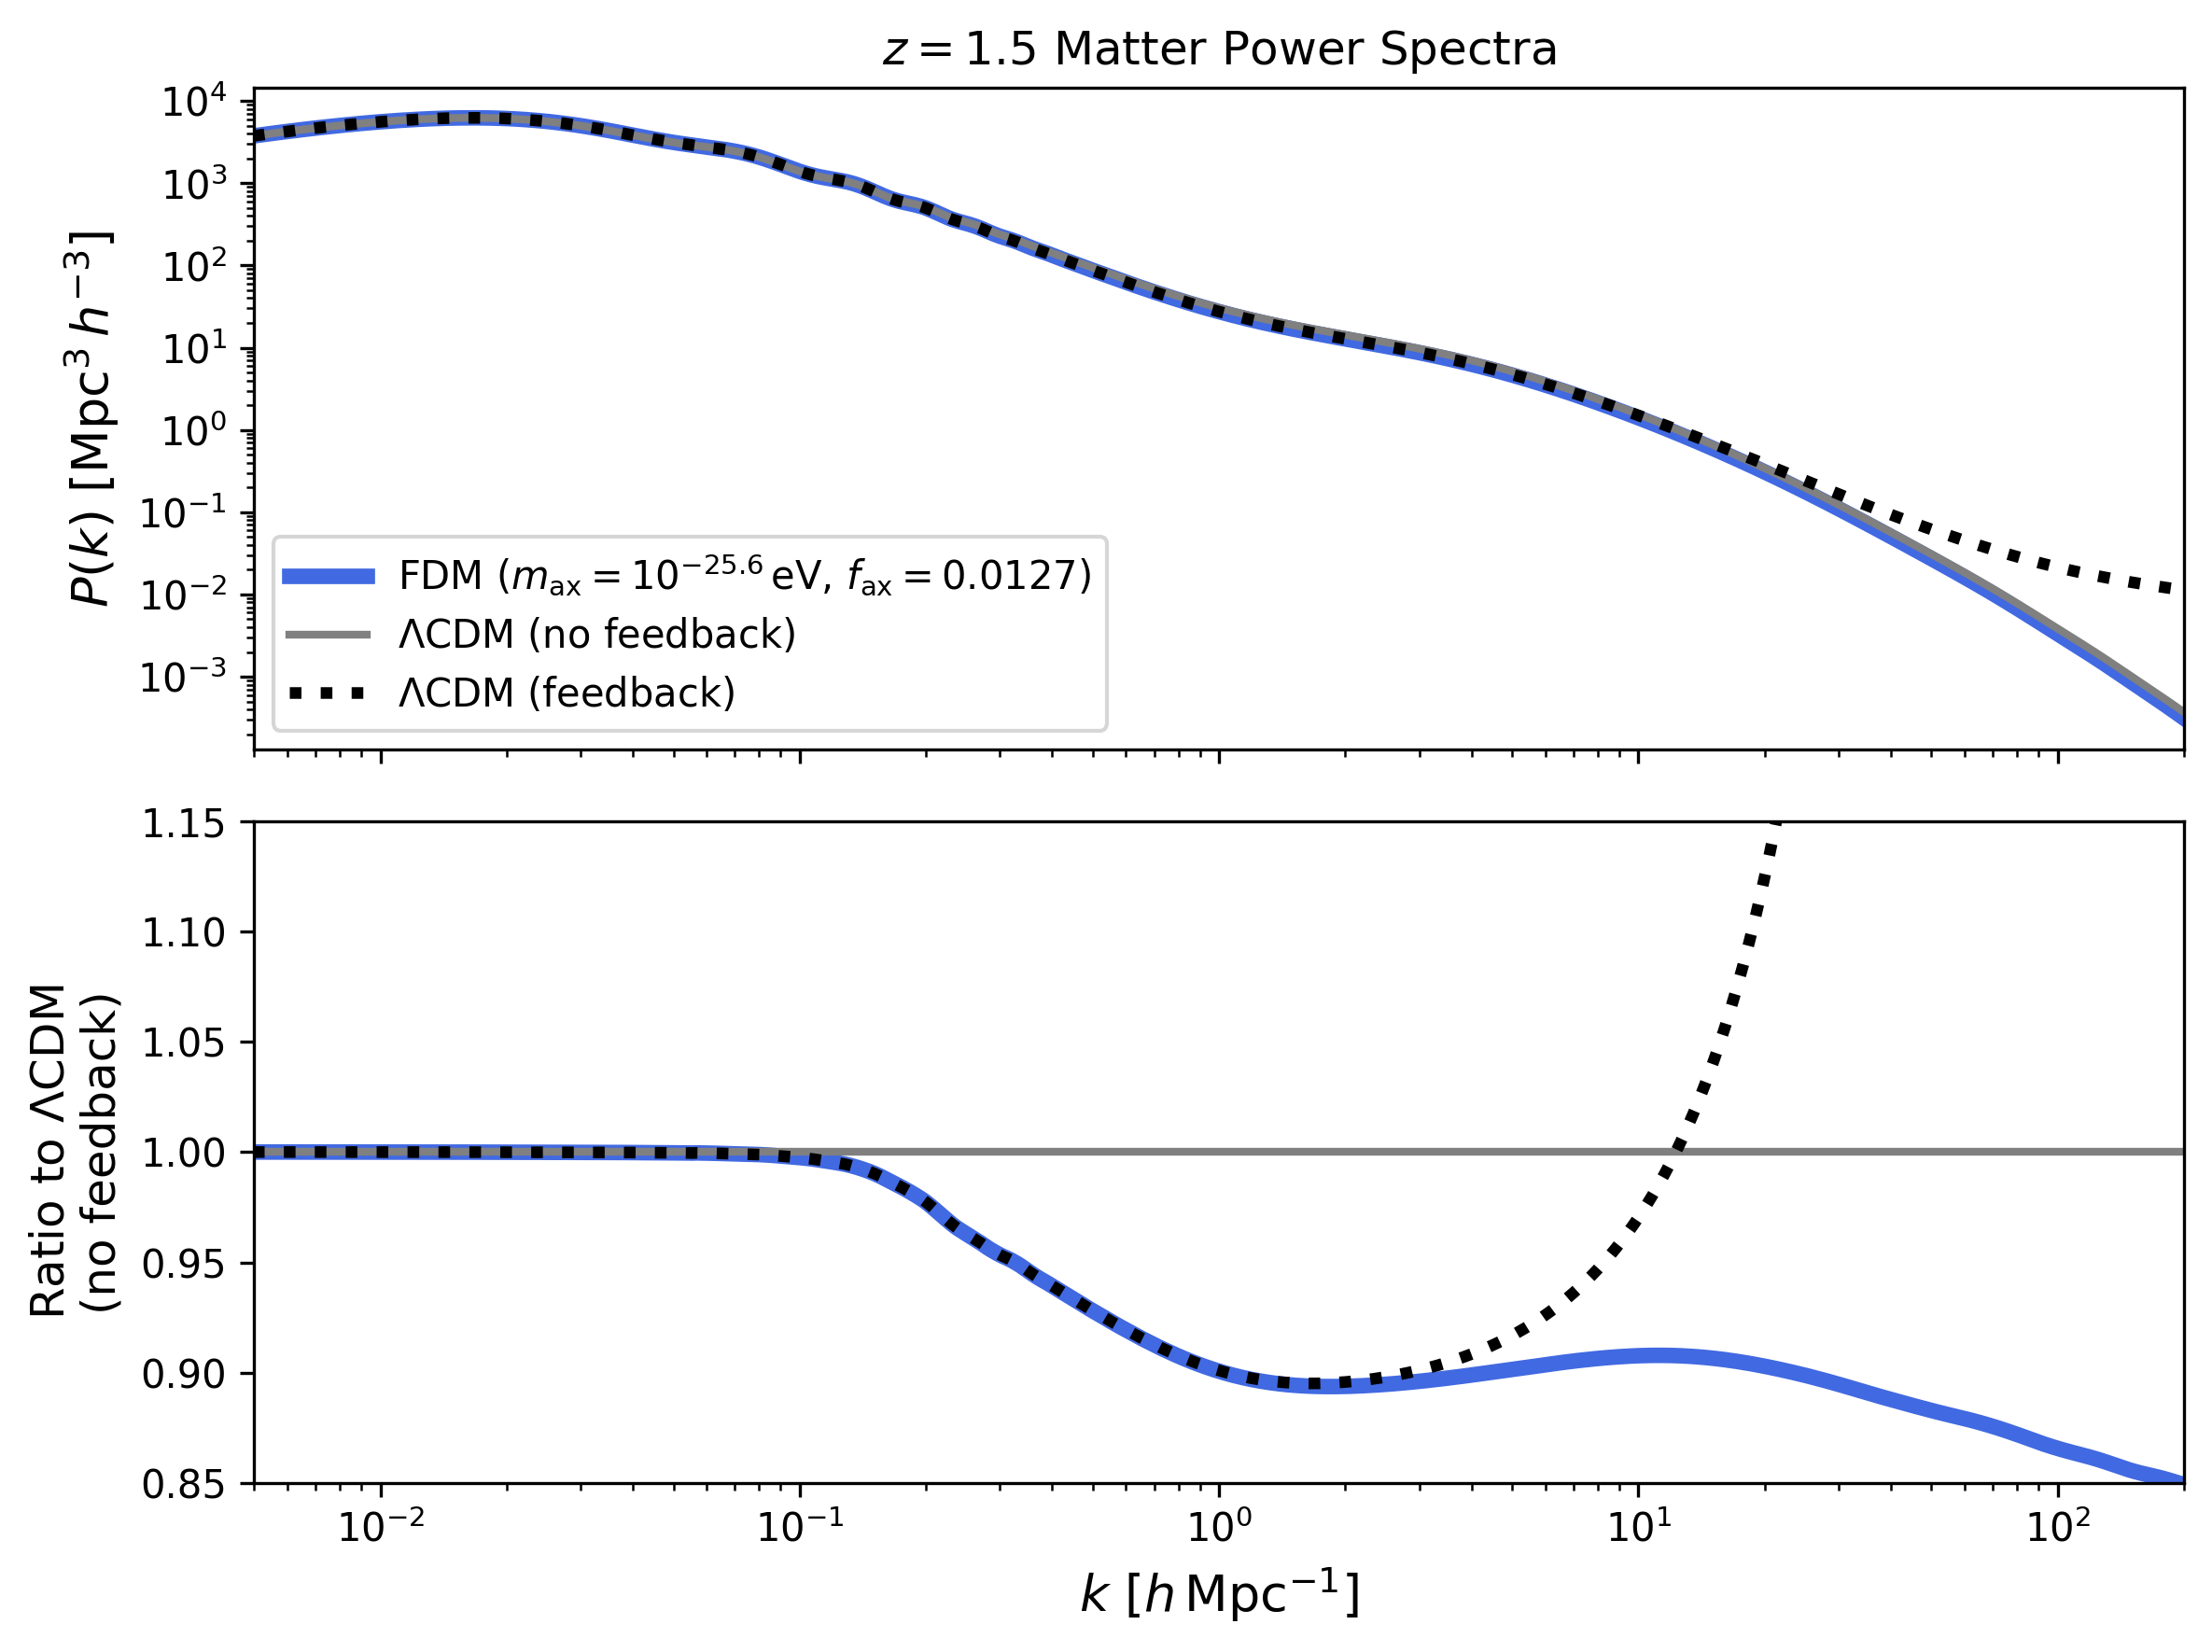

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=300, sharex=True, height_ratios=[1.0,1.0])

z = 1.5

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
with open(f"results/halo_model/{z}_data_FDM_full2h_preferred.pkl", "rb") as f:
    data_FDM_preferred = pickle.load(f)

r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
k_arr_HMCode = data_LCDM['power_spec_dic']['k']
M_arr = data_LCDM['M']
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1/min(K_ARR)), 1500)

# FDM preferred
ax1.plot(k_arr_HMCode, data_FDM_preferred['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
# ΛCDM baseline
ax1.plot(k_arr_HMCode, data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
ax2.plot(k_arr_HMCode, data_LCDM['P'] / data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
# P^target = P_FDM * S_cooling
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, M_arr, K_ARR, R_ARR, Del=200, reference_density="critical"
)
f_cga = 0.09 * (2.5e11 / M200c_arr)**0.6
R_h   = 0.015 * r200c_arr

u_cga_HMCodek = f_cga[:, None] * np.exp(-(k_arr_HMCode[None, :] * R_h[:, None])**2)
u_cooled = u_cga_HMCodek + (1 - f_cga[:, None]) * data_LCDM['utilde']
u_cooled[M_arr < 2.5e11] = data_LCDM['utilde'][M_arr < 2.5e11]
S_cooling = get_spectra(data_LCDM, u_cooled, full_output=False) / data_LCDM['P']

ax1.plot(k_arr_HMCode, data_FDM_preferred['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')

ax2.set_xlabel(r'$k$ $[h\,\text{Mpc}^{-1}]$', fontsize=13)
ax1.set_ylabel(r'$P(k)$ $[\text{Mpc}^{3}\,h^{-3}]$', fontsize=13)
ax2.set_ylabel(r'Ratio to $\Lambda$CDM' + '\n(no feedback)', fontsize=12)
ax1.set_title(rf'$z={z}$ Matter Power Spectra')
ax2.set_xlim(5e-3, 2e2)
ax2.set_ylim(0.85, 1.15)
ax2.set_xscale('log')
ax1.set_yscale('log')
ax1.legend(loc='lower left')

plt.tight_layout()
plt.show()

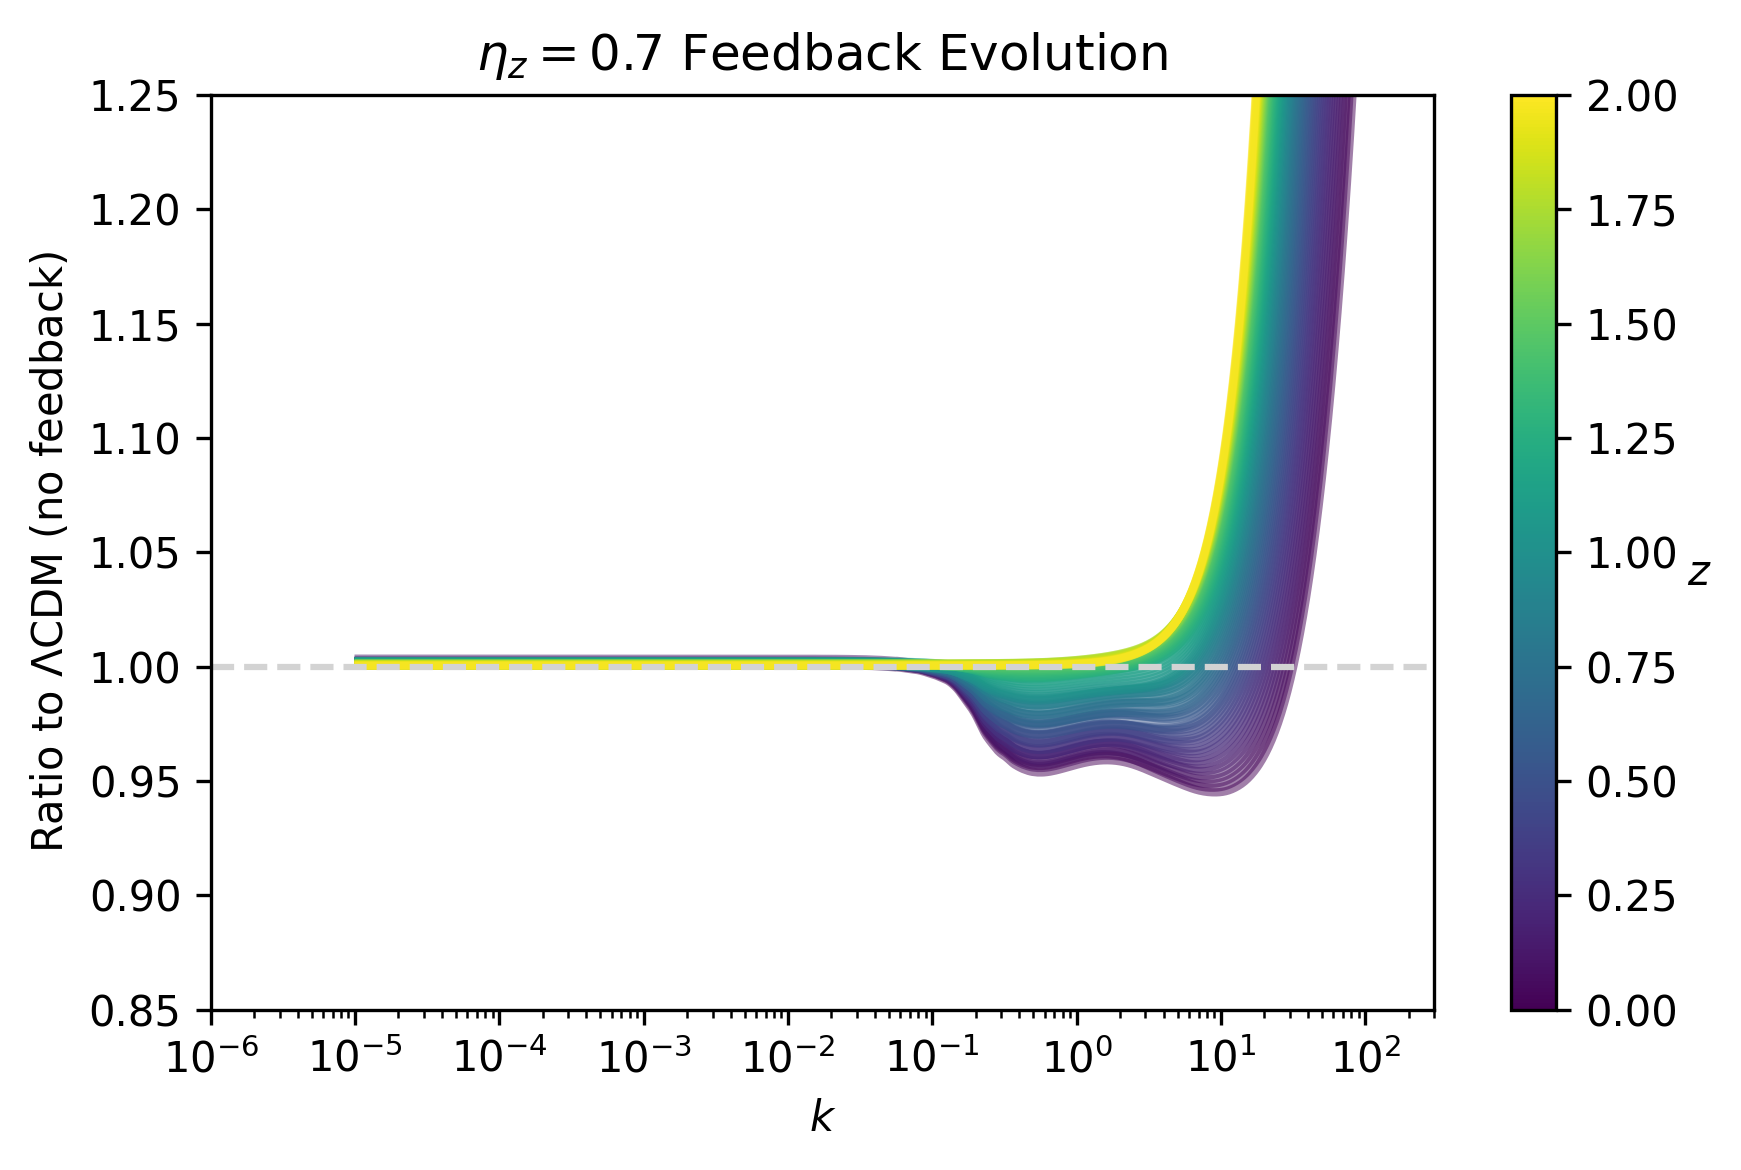

In [24]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 4), dpi=300)

gamma_val = 0.0
etaz = 0.7

K_ARR  = np.logspace(-6, 6, 8192)
R_ARR  = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

z_arr = np.linspace(0.0, 2.0, 81)
#z_arr = [0.0,0.5,1.0,1.5,2.0]
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(z_arr)))

for z, color in zip(z_arr, colors):
    with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    k_arr_HMCode = data_LCDM['power_spec_dic']['k']
    try:
        feedback_model = f"etaz{etaz}_preferred_cooled"
        baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
        #baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]
    
        ax1.semilogx(k_arr_HMCode, baryonic_profile[-1]['P']/data_LCDM['P'], c=color, ls='-',lw=2.,alpha=0.5)
    except:
        print(f"can't find z={z}")

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.0, vmax=2.0))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax1)
cbar.set_label(r'$z$', rotation=0, labelpad=5)

ax1.axhline(1.0, c='lightgray', ls='--')

ax1.set_xlabel(r'$k$')
ax1.set_ylabel(r'Ratio to $\Lambda$CDM (no feedback)')

ax1.set_ylim(0.85,1.25)
ax1.set_xlim(1e-6,3e2)
ax1.set_title(fr"$\eta_z = {etaz}$ Feedback Evolution")

plt.tight_layout()
plt.show()

##### Profile Plots

/tmp/ipykernel_662865/2735125127.py:30: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
/tmp/ipykernel_662865/2735125127.py:33: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])


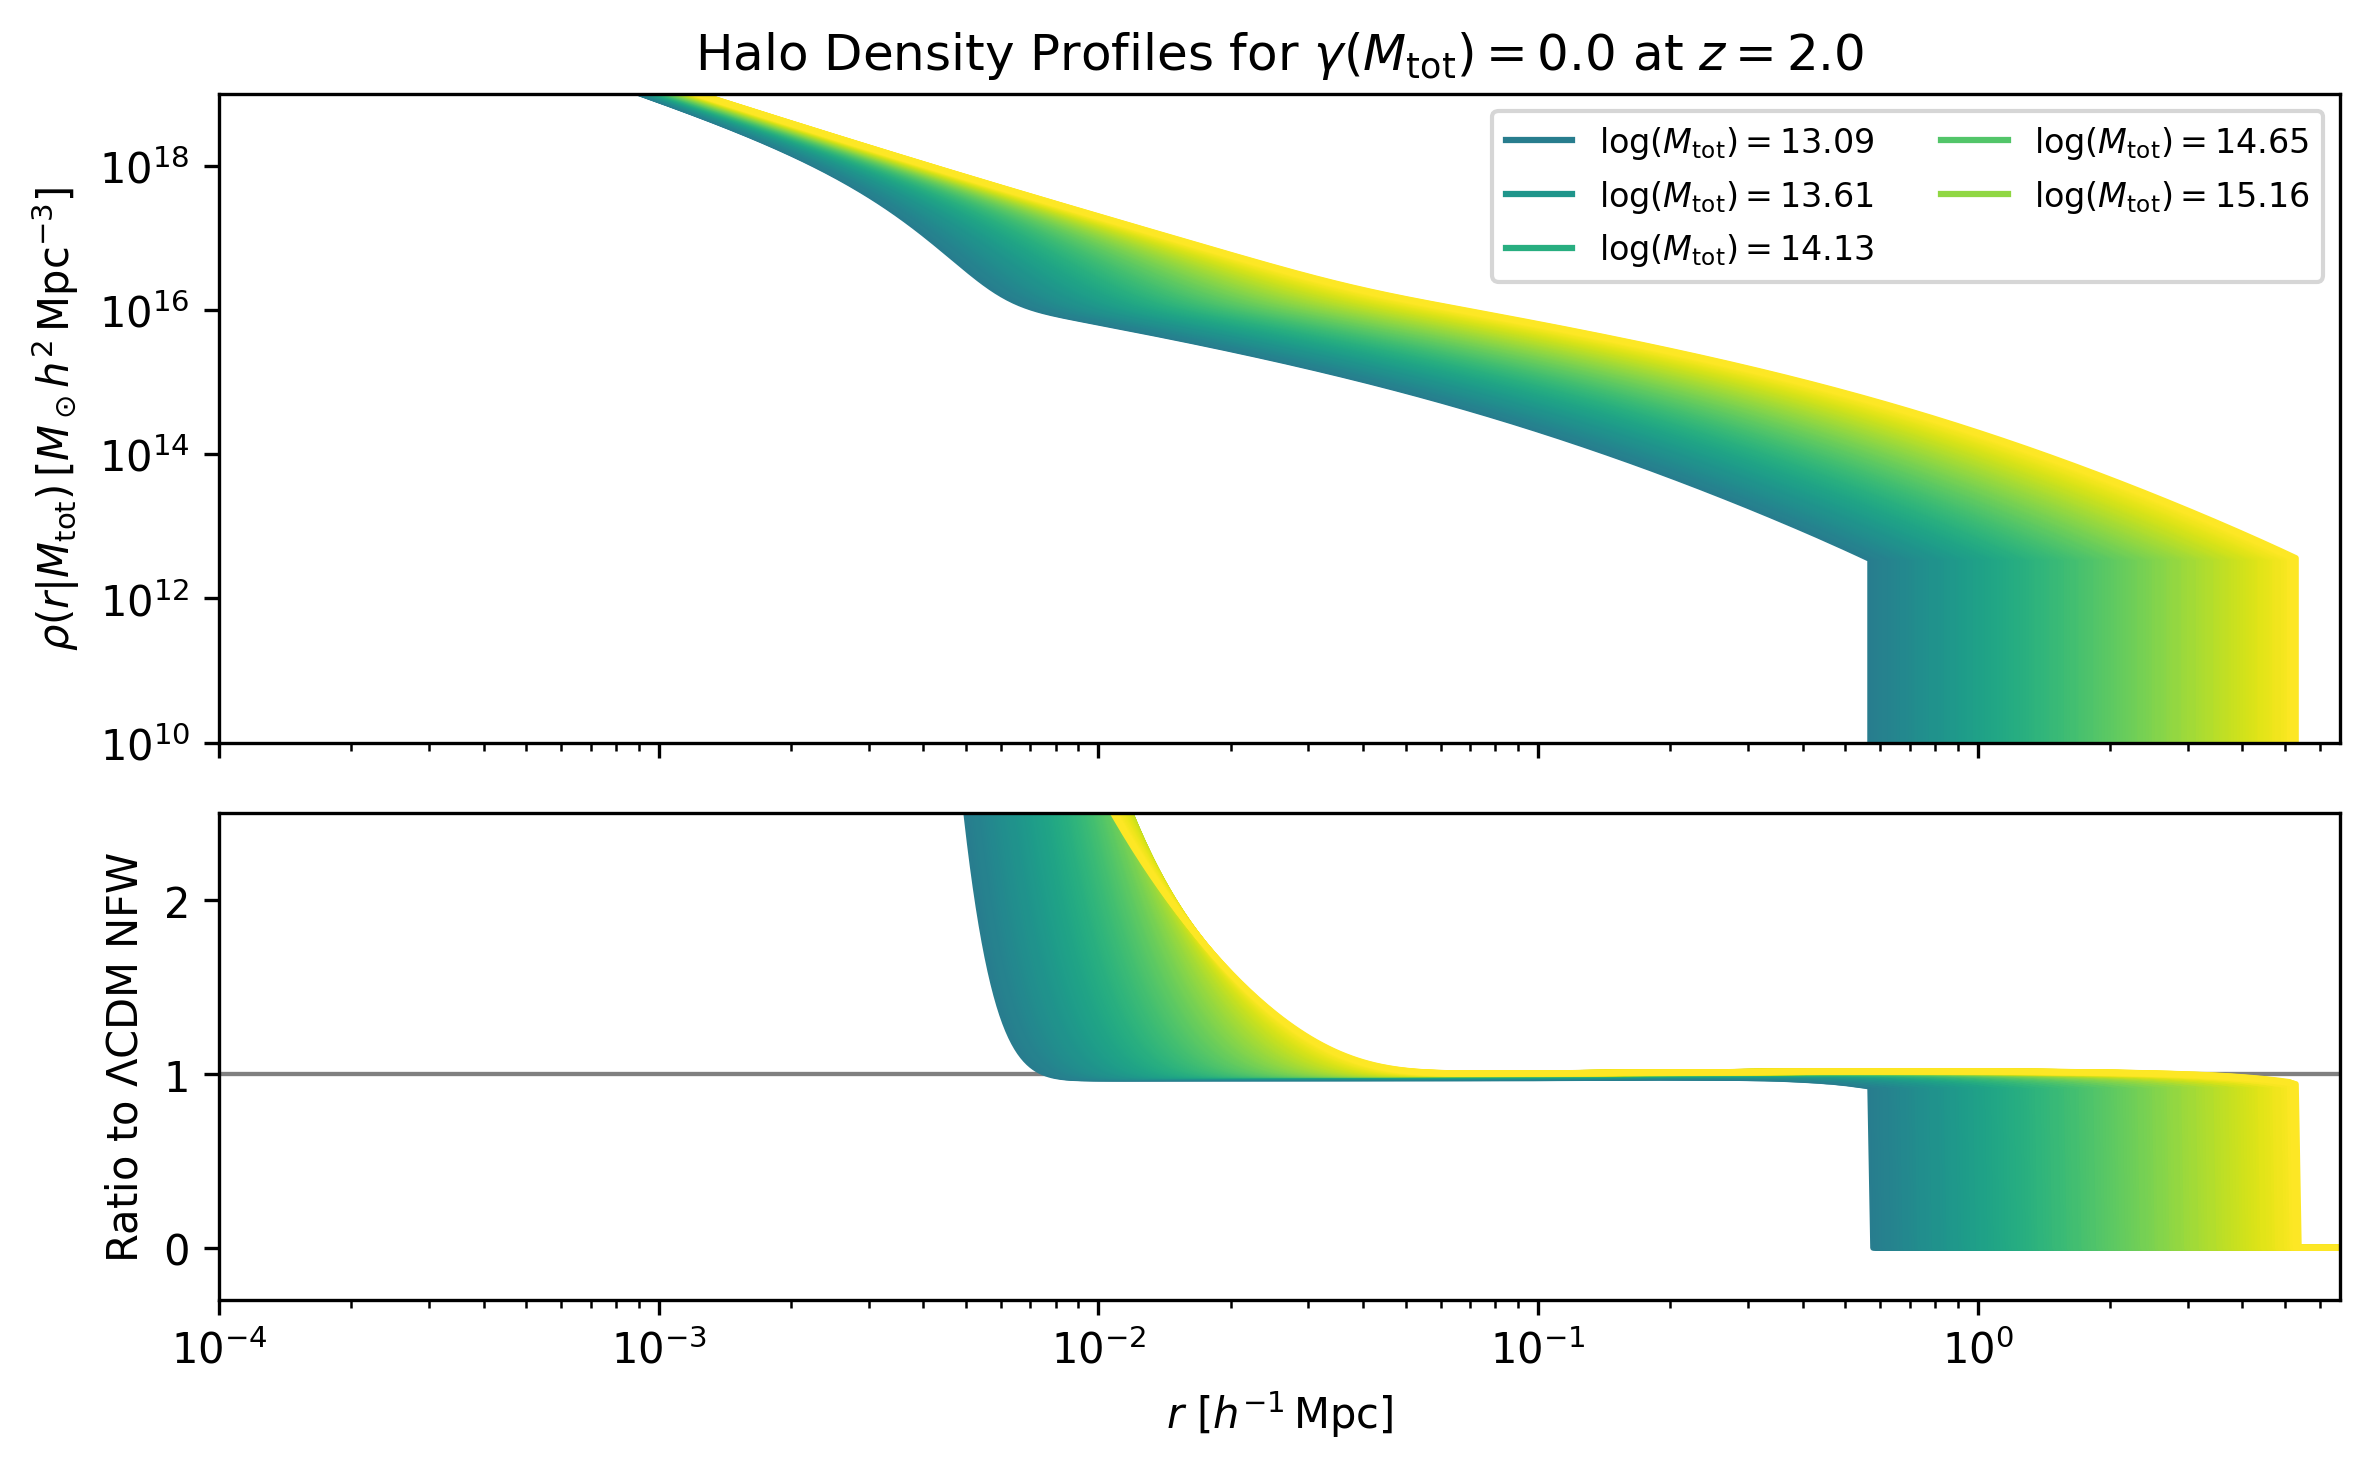

In [29]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), dpi=300, sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)
k_arr = np.logspace(-6, 6, 8192)
r_arr = np.logspace(-4, np.log10(1/min(k_arr)), 1500)

gamma_val = 0.0
etaz = 0.7
z = 2.0
feedback_model = f"etaz{etaz}_preferred_cooled"
keys = np.arange(np.size(data_LCDM['M'])) # M values
keys_labels = [0,31,62,93,125,156,187,218,249] # M values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
rho_NFW = get_realspace_profile(get_NFW_profile(k_arr=k_arr, r_s=r_s, r_v=r_v, r_t=max(r_arr) * r_v/r_v), 
                                r_t=max(r_arr) * r_v/r_v, r_arr=r_arr, k_arr=k_arr, M_arr=data_LCDM['M'])

#baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]
for m_index in keys[125:]:
    if m_index in keys_labels:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
    else:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])
#print(np.round(baryonic_profile[-1]['M_total_enclosed']/M_arr,4))

ax1.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
ax2.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
#ax2.set_ylim(0.5,1.5)
#ax1.set_ylim(1e12,1e19)
ax2.set_ylim(-0.3,2.5)
ax1.set_ylim(1e10,1e19)

ax2.set_ylabel(r'Ratio to $\Lambda$CDM NFW')
ax2.set_xscale("log")
ax2.set_yscale("linear")
ax1.set_yscale("log")
ax1.set_ylabel(r'$\rho(r|M_\text{tot}) \, [M_\odot h^2\,\text{Mpc}^{-3} ]$')
ax2.set_xlabel(r'$r$ $[h^{-1}\,\text{Mpc}]$')

ax1.set_title(rf'Halo Density Profiles for $\gamma(M_\text{{tot}}) = {gamma_val}$ at $z={z}$')
ax1.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

###### Pressure Profile Prescriptions Test

In [6]:
from feedback_mimic import universal_pressure_profile, get_BCM_profile, pressure_profile_arico, pressure_profile_baryon_pasting, compute_y0, dn_dlog10Mtot

In [7]:
z = 0.0
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1.0 / K_ARR.min()), 1500)

bias_sz = 0.8

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
axion_dic = None
r_t, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM, axion_dic)

Mtot, hmf_log10 = dn_dlog10Mtot(data_LCDM, "LCDM")
rho = get_realspace_profile(
        u_k=get_NFW_profile(r_v=r_t, k_arr=K_ARR, r_s=r_s, r_t=r_t),
        r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot, r_t=r_t)

/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")


In [8]:
from axionHMcode.cosmology.variance import func_sigma_M
from axionHMcode.cosmology.overdensities import func_delta_c
from axionHMcode.halo_model.halo_mass_function import func_sheth_tormen
HM_sigma = func_sigma_M(Mtot, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos']['Omega_m_0'])
HM_delta_c = func_delta_c(z, 
                          data_LCDM['cosmos']['Omega_ax_0'], data_LCDM['cosmos']['Omega_m_0'], data_LCDM['cosmos']['Omega_w_0'], 
                          data_LCDM['cosmos']['G_a'], data_LCDM['cosmos']['version'])
HM_nu = HM_delta_c / HM_sigma

In [9]:
from cosmocnc_axionHMcode_jax.cosmocnc_jax.surveys.survey_sr_so_sim import (
    precompute_q_prefactors, sr_q_so_sim_layer0, sr_q_so_sim_layer1
)

import os
os.environ["TOMOGRAPHIC_BINS"] = "DES"
from mcmc_likelihood import get_log_likelihood
ln_L, nc = get_log_likelihood(
    catalogue_name = f"/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_DES_mock_seed42.pkl",
    omega_m  = 0.143344,
    A_s      = 2.1e-9,
    A_sz     = -4.3054, # just default vals from cosmocnc paper
    alpha_sz = 1.233,
    beta_sz  = 2.0,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    return_nc = True,
    n_points = 1000,
    n_mass_points_coarse = 1000
)

H_FID = 0.68
def q_via_survey_sr(M500c_h, z, nc, A_sz, alpha_sz, beta_sz, bias_sz, dof, h_fid=H_FID):
    """
    Computes q per-halo using the EXACT algorithm survey_sr_so_sim.py's
    sr_q_so_sim_layer0/layer1 use in the real likelihood, in place of
    feedback_mimic's profile_to_q integral method. Deliberately uses nc's
    OWN D_A/E_z (the same emulator-derived values the real likelihood
    consumes) rather than an independent reference -- this catalog is meant
    to inherit whatever the likelihood's own machinery produces, so any
    comparison against the LCDM_COSMOCNC catalog isolates exactly the
    profile-integral-vs-analytic-formula question, nothing else.
    """
    iz = np.argmin(np.abs(np.asarray(nc.redshift_vec) - z))
    E_z_val, D_A_val = float(nc.E_z[iz]), float(nc.D_A[iz])
    H0_val = h_fid * 100.

    prefactor_logy0, prefactor_M_500_to_theta = precompute_q_prefactors(
        E_z_val, H0_val, D_A_val, A_sz, bias_sz, alpha_sz, beta_sz)

    M500c_phys = np.asarray(M500c_h) / h_fid
    x0_500 = np.log(M500c_phys / 1e14)
    sr = nc.scaling_relations['q_so_sim']
    sigma_sz_poly = sr.sigma_sz_poly
    log_theta_min = sr.log_theta_min          # same bounds object the
    log_theta_max = sr.log_theta_max          # likelihood itself uses

    x1, _ = sr_q_so_sim_layer0(x0_500, prefactor_logy0, prefactor_M_500_to_theta,
                                 sigma_sz_poly, alpha_sz,
                                 log_theta_min, log_theta_max)
    q = sr_q_so_sim_layer1(x1, prefactor_logy0, prefactor_M_500_to_theta, dof)
    return np.asarray(q)

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/
defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/cosmocnc_axionHMcode_jax/cosmocnc_jax/
cache_suffix = 
Loaded precomputed tables from cache
Shear cache already made
PATH_TO_CLASS_SZ_DATA not set. Setting it now...
Defaulting to: /home/jange/class_sz_data_directory


2026-07-28 16:02:47.268248: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/cnc.py:808: DeprecationWarning: compute_class_szfast is deprecated. Use initialize_classy_szfast instead.
  self.cosmology = cosmology_model(cosmo_params=self.cosmo_params,
/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")


In [10]:
out = {}

In [11]:
from feedback_mimic import profile_to_q

out['arnaud'] = profile_to_q(
                data_LCDM, axion_dic=axion_dic, rho=rho, r_t=r_t,
                M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                bias_sz=0.8, dof=0.0, pressure_profile_prescription = "ArnaudUPP",
                full_output = True)
# q, y0, np.exp(log_sigma_sz), theta_500

FEEDBACK_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/feedback_models"
etaz           = 0.7
FEEDBACK_MODEL = f"etaz{etaz}_preferred_cooled"
gamma_val = 0.0
baryonic_profile = np.load(
    f"{FEEDBACK_INPUT_FILE}/{FEEDBACK_MODEL}/"
    f"utilde_results_gamma{0.0}_z{z}.npy",
    allow_pickle=True)[()]
rho_feedback  = baryonic_profile[-1]['rho_hat_unbiased']
r_t_feedback  = baryonic_profile[-1]['r_t_unbiased']
out['arnaud_gamma0feedback'] = profile_to_q(
                data_LCDM, axion_dic=axion_dic, rho=rho_feedback, r_t=r_t_feedback,
                M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                bias_sz=0.8, dof=0.0, pressure_profile_prescription = "ArnaudUPP",
                full_output = True)

h_fid = 0.68
M500c, R500c = Mtot_to_MDelta(
    data_LCDM, r_t=r_t, M_arr=Mtot, r_arr=R_ARR, Del=500,
    reference_density="critical", axion_dic=axion_dic, rho=rho, k_arr=K_ARR)
out['default_scaling_relation'] = q_via_survey_sr(M500c, z, nc, A_sz=-4.3054, alpha_sz=1.233,
                               beta_sz=2.0, bias_sz=0.8, dof=0.0, h_fid=h_fid)
out['best_fit_scaling_relation'] = q_via_survey_sr(M500c, z, nc, A_sz=-4.353355099, alpha_sz=1.199496418,
                               beta_sz=2.000448160, bias_sz=0.8, dof=0.0, h_fid=h_fid)
#https://arxiv.org/pdf/2408.06189
out['PlanckSZiFi_scaling_relation'] = q_via_survey_sr(M500c, z, nc, A_sz=-4.3054, alpha_sz=1.1233,
                               beta_sz=2.0, bias_sz=0.62, dof=0.0, h_fid=h_fid)
# q

/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:515: RuntimeWarning: divide by zero encountered in divide
  theta_500 = r500_biased / D_A_h * (180*60/np.pi)
/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:406: RuntimeWarning: invalid value encountered in divide
  P500 = (500.*f_B*G*mu*rho_crit/(2.*mu_e)) * (M500/r500) # km^2 * M_sun / (Mpc^3 * s^2)
/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:413: RuntimeWarning: divide by zero encountered in divide
  x = np.einsum('r,M->Mr',r_arr,1./r500) # M,r
/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:426: RuntimeWarning: invalid value encountered in divide
  alpha_P_prime = 0.10 - (alpha_P + 0.10) * (x/0.5)**3 / (1 + (x/0.5)**3)
/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:510: RuntimeWarning: divide by zero encountered in log
  log_y0 = np.log(y0)
/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:515: RuntimeWarning: invalid value encountered in divide
  theta_500 = r500_biased / D_A_h * (180*60/n

In [12]:
out['baryonPasting_nelson2014'] = profile_to_q(data_LCDM, axion_dic=axion_dic, rho=rho, r_t=r_t,
                        M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                        bias_sz=0.8, dof=0.0, 
                        nu=HM_nu,
                        Gamma=1.2,              # Shaw et al. (2010) default
                        B_param=None,           # None -> B = 1 (Arico-equivalent normalisation)
                        A_star=0.09,
                        M_star_0=2.5e11,
                        eta_star=0.32,
                        f_th_model="nelson2014",
                        pressure_profile_prescription = "baryonPasting",
                        full_output = True)
# q, y0, np.exp(log_sigma_sz), theta_500
out['baryonPasting_green2020'] = profile_to_q(data_LCDM, axion_dic=axion_dic, rho=rho, r_t=r_t,
                        M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                        bias_sz=0.8, dof=0.0, 
                        nu=HM_nu,
                        Gamma=1.2,              # Shaw et al. (2010) default
                        B_param=None,           # None -> B = 1 (Arico-equivalent normalisation)
                        A_star=0.09,
                        M_star_0=2.5e11,
                        eta_star=0.32,
                        f_th_model="green2020",
                        pressure_profile_prescription = "baryonPasting",
                        full_output = True)
# q, y0, np.exp(log_sigma_sz), theta_500

/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:974: RuntimeWarning: divide by zero encountered in divide
  x_200m = r_arr[None, :] / r200m[:, None]


In [13]:
out['arico_nelson2014'] = profile_to_q(data_LCDM, axion_dic=axion_dic, rho=rho, r_t=r_t,
                        M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                        bias_sz=0.8, dof=0.0, 
                        nu=HM_nu,
                        theta_out=4.0,          # sets the polytropic index
                        theta_co=0.1,           # BCM core radius / r200c   (fixed in BCM)
                        theta_ej=4.0,           # BCM ejection radius / r200c
                        M_gas_c=1.2e14,         # beta_gas pivot mass, Msun/h
                        mu_gas=0.31,            # beta_gas slope
                        A_star=0.09,            # BCM stellar normalisation
                        M_star_0=2.5e11,        # BCM stellar pivot, Msun/h
                        eta_star=0.32,          # total stellar fraction slope
                        f_th_model="nelson2014",
                        pressure_profile_prescription = "AricoBCM",
                        full_output = True)
# q, y0, np.exp(log_sigma_sz), theta_500
out['arico_green2020'] = profile_to_q(data_LCDM, axion_dic=axion_dic, rho=rho, r_t=r_t,
                        M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                        bias_sz=0.8, dof=0.0, 
                        nu=HM_nu,
                        theta_out=4.0,          # sets the polytropic index
                        theta_co=0.1,           # BCM core radius / r200c   (fixed in BCM)
                        theta_ej=4.0,           # BCM ejection radius / r200c
                        M_gas_c=1.2e14,         # beta_gas pivot mass, Msun/h
                        mu_gas=0.31,            # beta_gas slope
                        A_star=0.09,            # BCM stellar normalisation
                        M_star_0=2.5e11,        # BCM stellar pivot, Msun/h
                        eta_star=0.32,          # total stellar fraction slope
                        f_th_model="green2020",
                        pressure_profile_prescription = "AricoBCM",
                        full_output = True)
# q, y0, np.exp(log_sigma_sz), theta_500

/scratch/scratch-jange/FeedbackMimic/feedback_mimic.py:859: RuntimeWarning: divide by zero encountered in divide
  x_200m = r_arr[None, :] / r200m[:, None]


In [47]:
rho_BCM = get_BCM_profile(data_LCDM, K_ARR, R_ARR, Mtot,
                    theta_ej=4.0, theta_co=0.1, M_c=1e14, mu_gas=0.31,
                    A_star=0.09, M_star0=2.5e11, eta_cga=0.6, eta_star=0.32,
                    R_cga_h_frac=0.015, axion_dic=None, min_M=1e12, 
                    gas_type="Arico", rho_NFW=None,
                    gas_normalization="to_virial")[0]
out['arnaud_on_BCM'] = profile_to_q(
                data_LCDM, axion_dic=axion_dic, rho=rho_BCM, r_t=r_t,
                M_arr=Mtot, k_arr=K_ARR, r_arr=R_ARR,
                bias_sz=0.8, dof=0.0, pressure_profile_prescription = "ArnaudUPP",
                full_output = True)

In [48]:
M_enc = get_enclosed_mass(rho_BCM, r_t=r_t, r_arr=R_ARR)
print((M_enc / Mtot)[Mtot > 1e13])

[1.00418631 0.99988995 1.00136454 1.00252598 1.00338099 1.00393618
 1.00419813 0.99981657 1.00130228 1.00247715 1.00334797 1.0039212
 1.00420344 0.99973392 1.00123201 1.00242146 1.00330884 1.00390062
 1.00420328 0.99964229 1.00115423 1.0023594  1.00326415 1.00387503
 1.00419829 0.99954158 1.00106908 1.00229124 1.00321443 1.00384503
 1.00418917 0.99943186 1.00097662 1.00221713 1.00315985 1.00381085
 1.00417629 0.9993128  1.00087668 1.00213723 1.00310064 1.0037729
 1.00416006 0.99918411 1.0007691  1.00205133 1.0030367  1.00373121
 1.00414064 0.99904519 1.00065362 1.00195933 1.00296814 1.00368593
 1.00411825 1.00427076 1.00052968 1.00186079 1.00289468 1.0036369
 1.00409299 1.00426834 1.00039673 1.00175546 1.00281614 1.00358411
 1.00406484 1.00426347 1.00025387 1.00164263 1.00273201 1.00352734
 1.00403378 1.00425634 1.00010029 1.00152166 1.0026419  1.00346628
 1.00399963 1.00424686 0.99993456 1.00139143 1.00254513 1.0034005
 1.00396229 1.00423516 0.9997551  1.00125083 1.00244078 1.00332941

(0.8, 500.0)

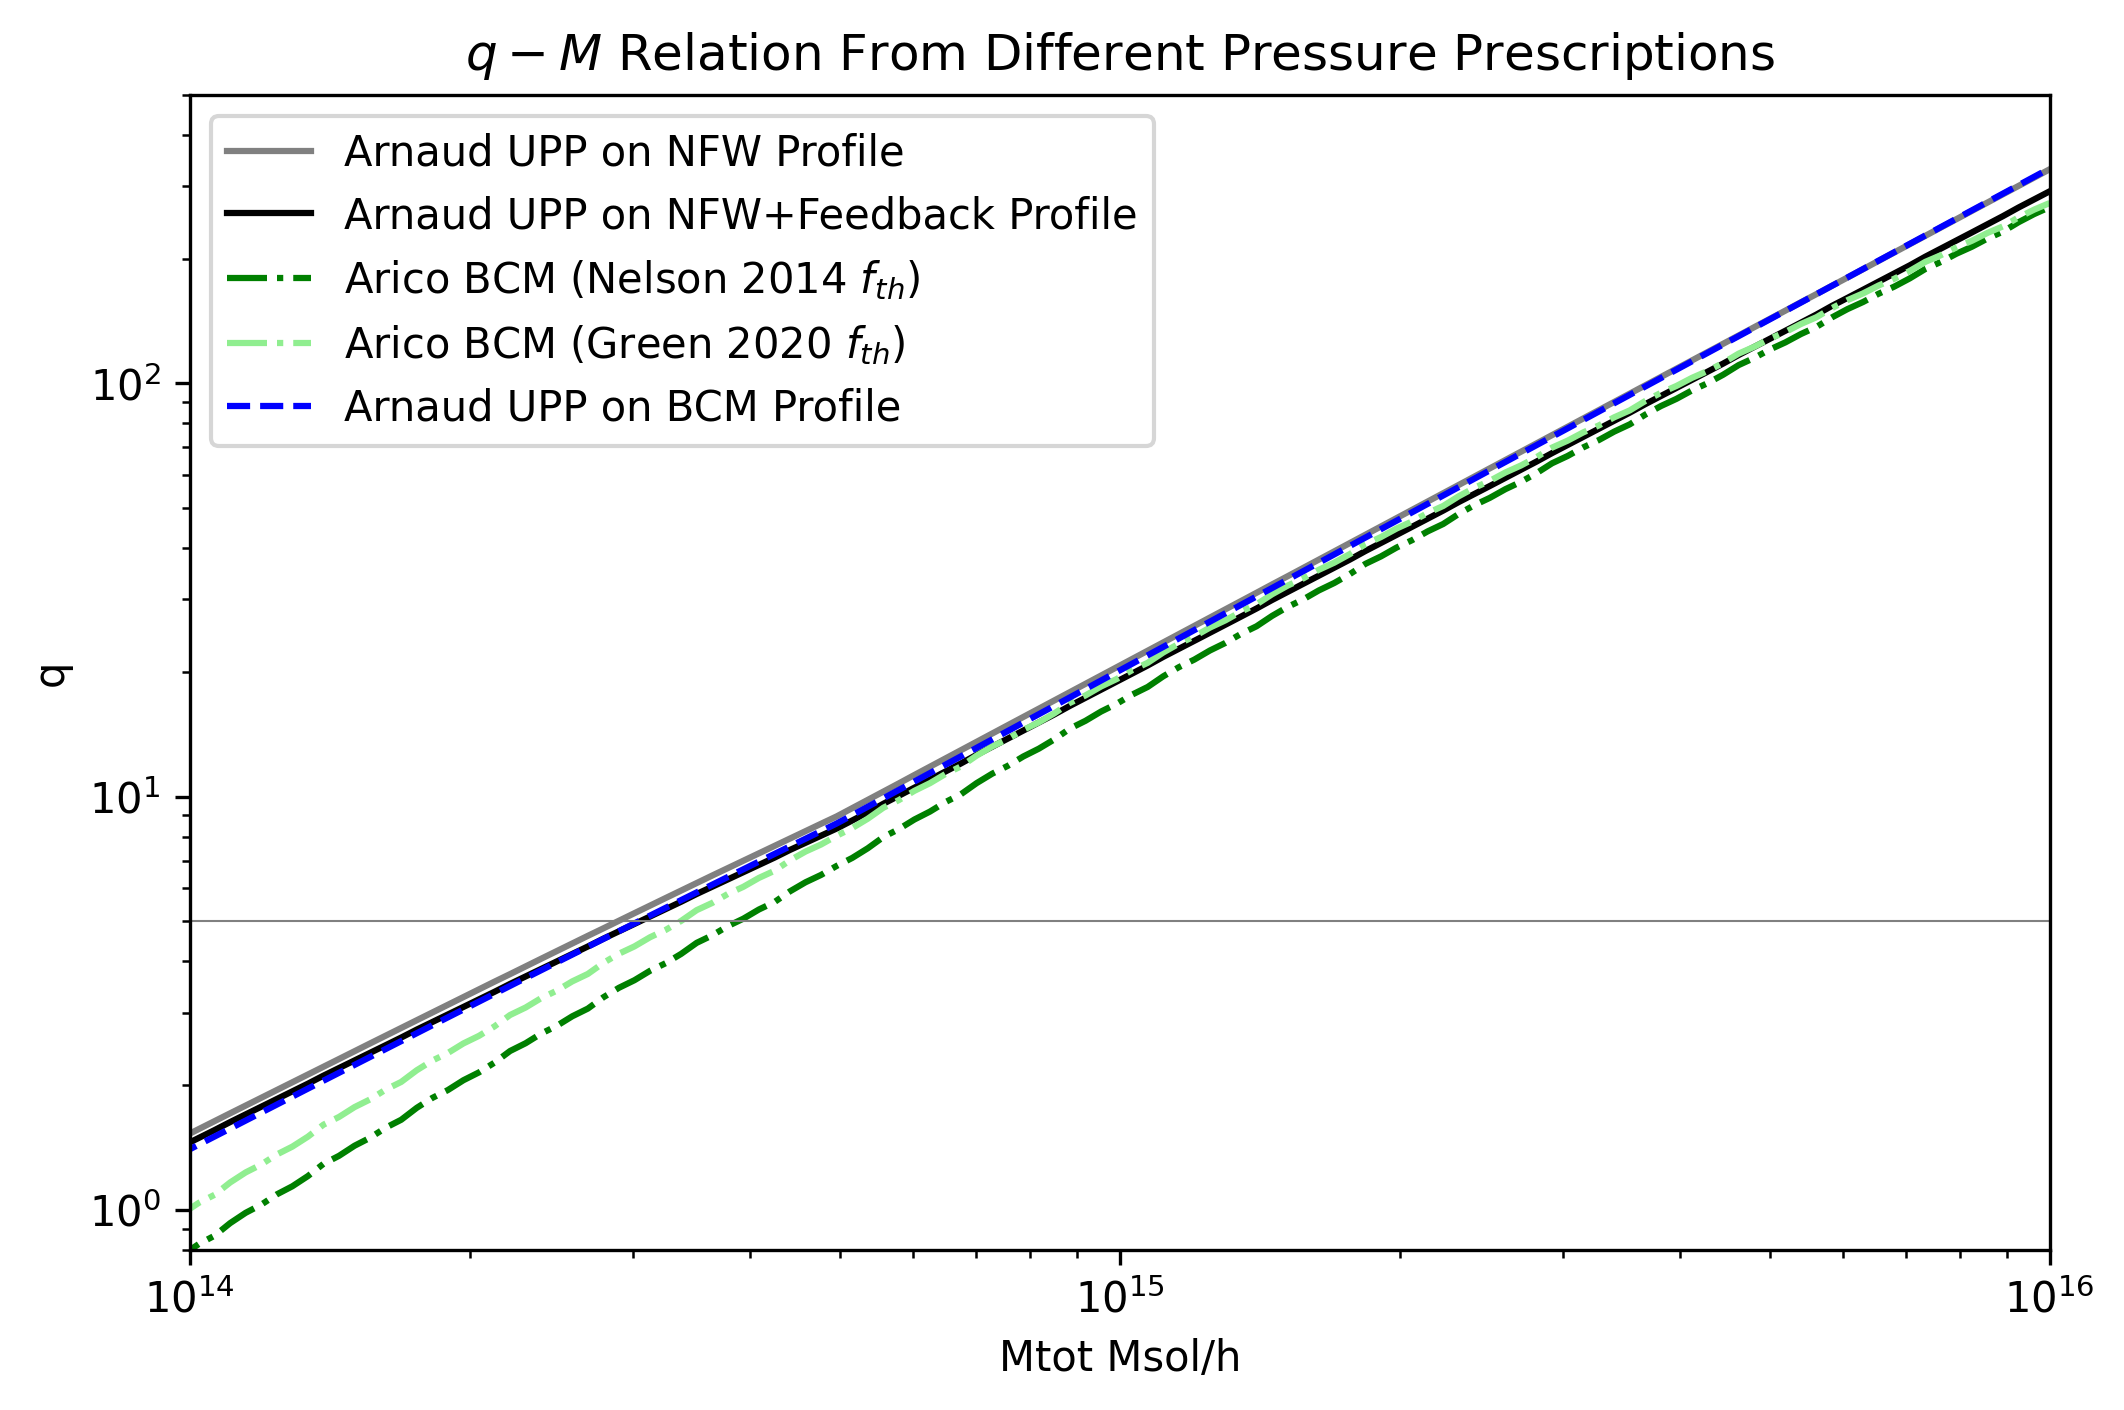

In [49]:
plt.figure(dpi=300, figsize=(8,5))
plt.loglog(Mtot, out['arnaud'][0], label='Arnaud UPP on NFW Profile', c='gray')
plt.loglog(Mtot, out['arnaud_gamma0feedback'][0], label='Arnaud UPP on NFW+Feedback Profile', c='black')
#plt.loglog(Mtot, out['PlanckSZiFi_scaling_relation'], label=r'Scaling Relation (Synthetic Planck SZiFi parameter values)', ls='--', c='red')
#plt.loglog(Mtot, out['default_scaling_relation'], label='Scaling Relation (default cosmocnc parameter values)', ls=':', c='salmon')
#plt.loglog(Mtot, out['best_fit_scaling_relation'], label='Best Fit Scaling Relation (to Arnaud UPP)',
#           ls='--', c='red')
#plt.loglog(Mtot, out['baryonPasting_nelson2014'][0], label='Baryon Pasting (Nelson 2014 $f_{th}$)',
#          c='blue',ls='-.')
#plt.loglog(Mtot, out['baryonPasting_green2020'][0], label='Baryon Pasting (Green 2020 $f_{th}$)',
#          c='lightblue',ls='-.')
plt.loglog(Mtot, out['arico_nelson2014'][0], label='Arico BCM (Nelson 2014 $f_{th}$)',
          c='green',ls='-.')
plt.loglog(Mtot, out['arico_green2020'][0], label='Arico BCM (Green 2020 $f_{th}$)',
          c='lightgreen',ls='-.')
plt.loglog(Mtot, out['arnaud_on_BCM'][0], label='Arnaud UPP on BCM Profile',
          c='blue', ls='--')
plt.axhline(5.0, c='gray', lw=0.5)
#plt.semilogx(Mtot, out['arnaud'][0], label='Arnaud UPP on NFW Profile', c='gray')
#plt.semilogx(Mtot, out['best_fit_scaling_relation'], label='Best Fit Scaling Relation (to Arnaud UPP)',
#           ls='--', c='red')

plt.legend()
plt.title(r'$q-M$ Relation From Different Pressure Prescriptions')
plt.ylabel('q')
plt.xlabel('Mtot Msol/h')
plt.xlim(1e14,1e16)
plt.ylim(8e-1,5e2)

##### Cluster Counts Plot

###### Catalog Plots

LCDM_DES: N_sel=11082
LCDM_hat0p0_DES: N_sel=9747
FDM_preferred_DES: N_sel=10752


/tmp/ipykernel_662865/2362213547.py:387: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


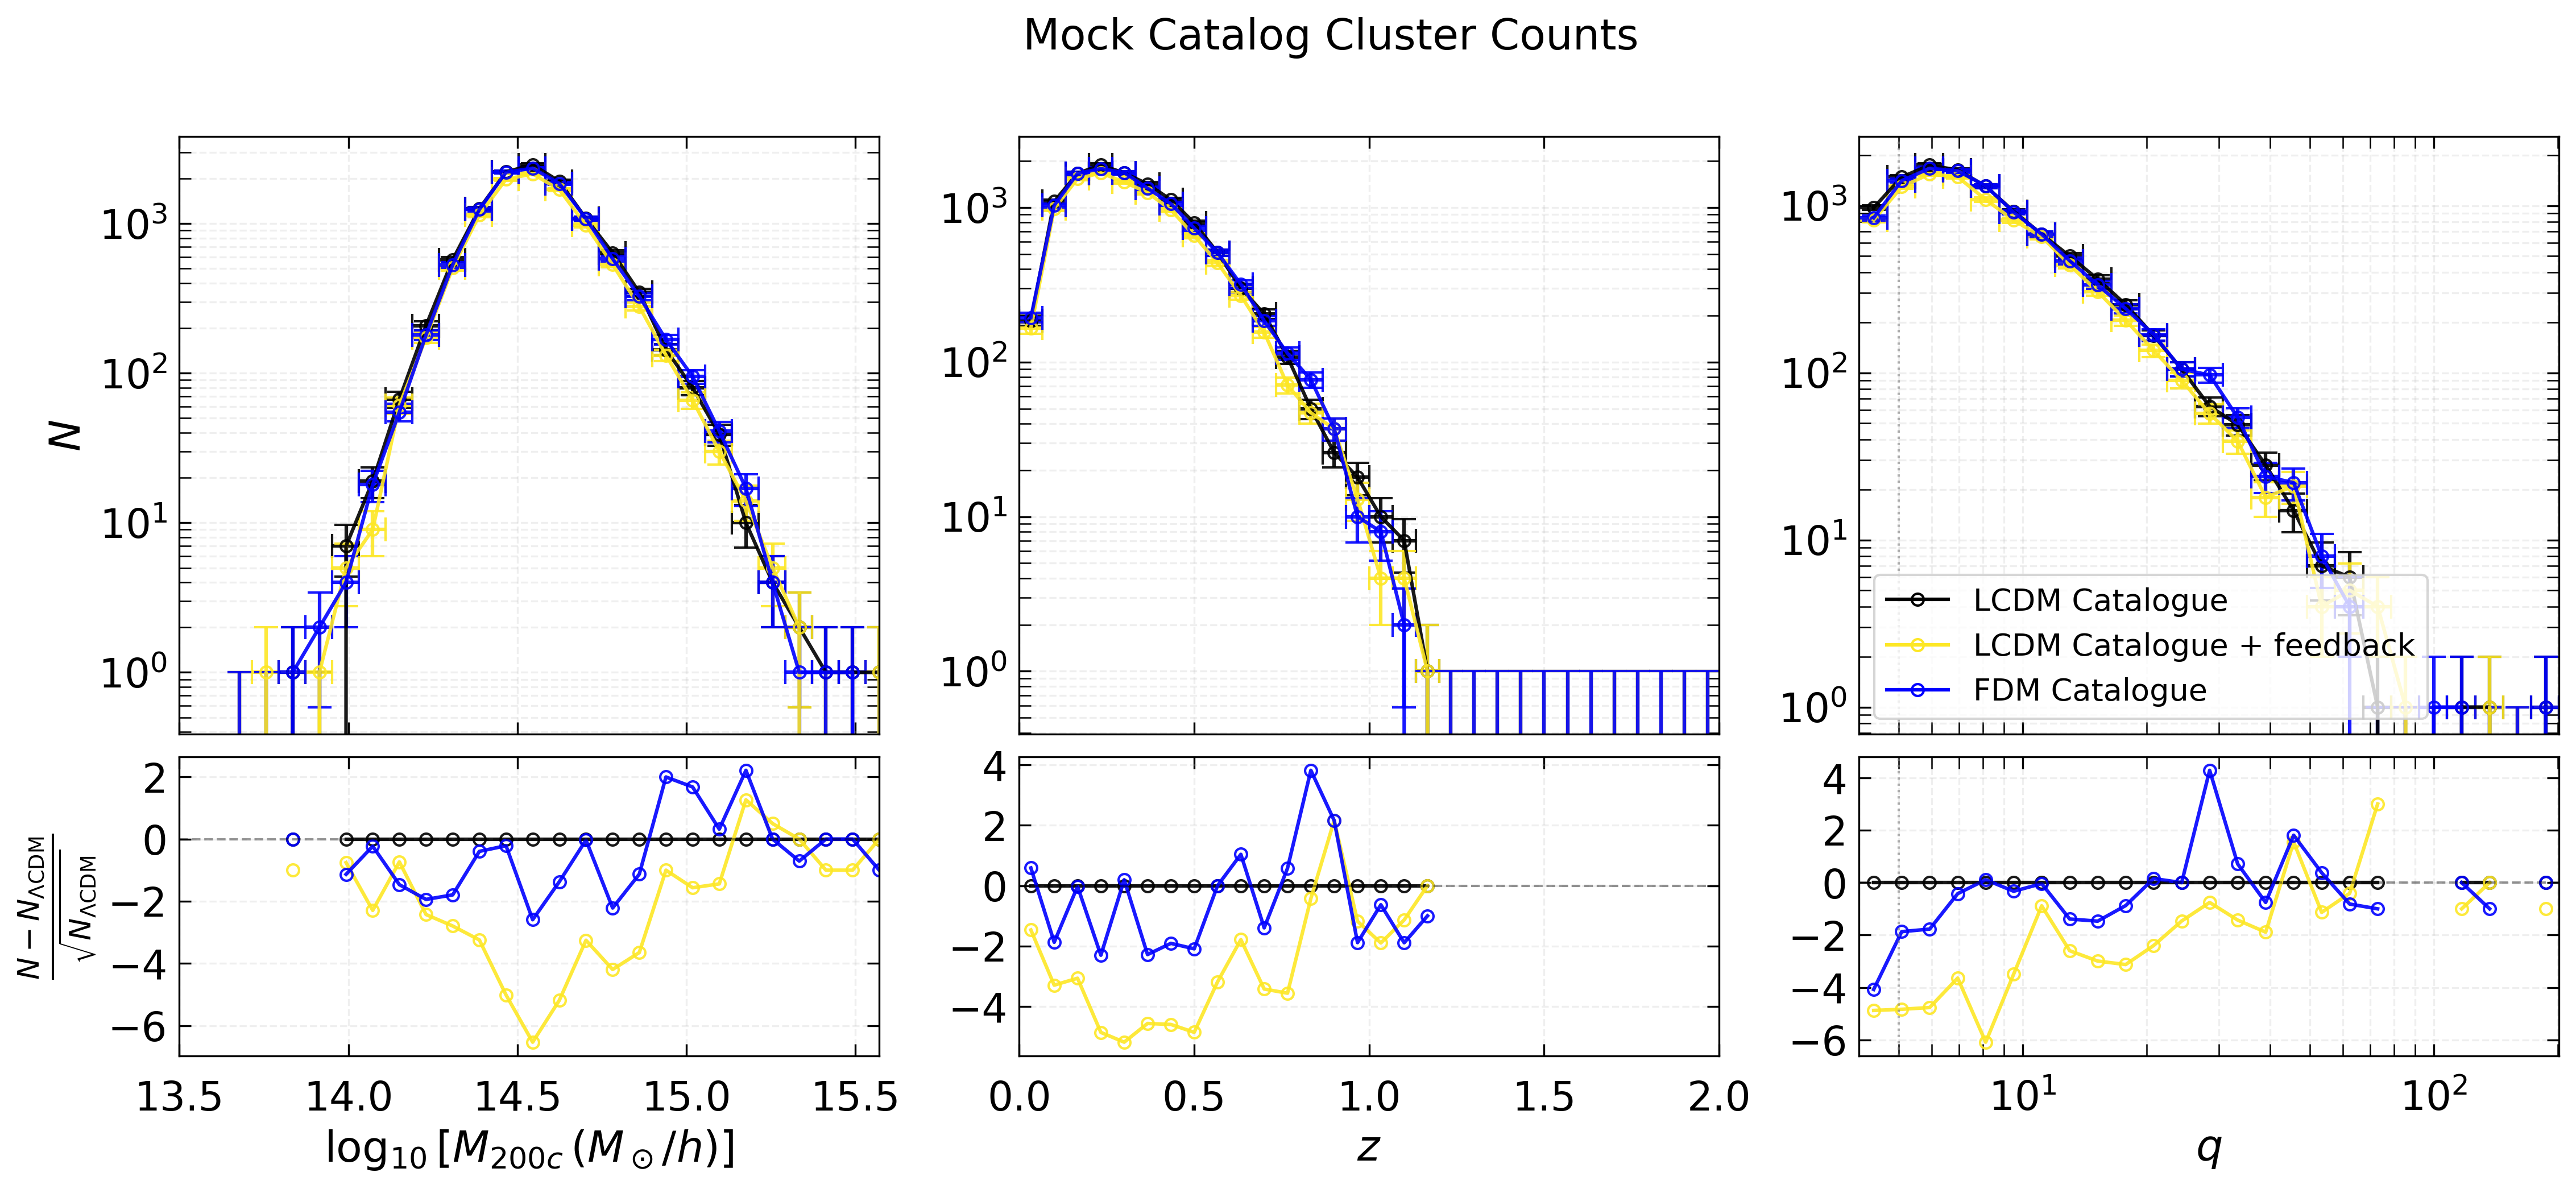

In [32]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%matplotlib inline

# ──────────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────────

CATALOG_DIR = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
SEED = 50

keys = [0.0, 0.0] # gamma values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))
HMF_TYPES = [
    'LCDM_DES',
    'LCDM_hat0p0_DES',
    'FDM_preferred_DES',
]

COLORS = [
    'k',
    color_dict[0.0],
    'blue',
]

LABELS = [
    r'LCDM Catalogue',
    r'LCDM Catalogue + feedback',
    r'FDM Catalogue',
]

N_BINS_M = 25
N_BINS_Z = 30
N_BINS_Q = 25

label_size = 17
title_size = 18
legend_size = 13

q_type = 'q_true'

# ──────────────────────────────────────────────────────────────────────────────
# STYLING
# ──────────────────────────────────────────────────────────────────────────────

def style_ax(ax):

    ax.tick_params(
        axis='x',
        which='both',
        length=5,
        direction='in',
        pad=10
    )

    ax.tick_params(
        axis='y',
        which='both',
        length=5,
        direction='in',
        pad=5
    )

    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

    plt.setp(
        ax.get_yticklabels(),
        rotation='horizontal',
        fontsize=label_size
    )

    plt.setp(
        ax.get_xticklabels(),
        fontsize=label_size
    )

    ax.grid(
        visible=True,
        which='both',
        alpha=0.2,
        linestyle='--'
    )


# ──────────────────────────────────────────────────────────────────────────────
# LOAD CATALOGS
# ──────────────────────────────────────────────────────────────────────────────

cats = {}

for hmf_type in HMF_TYPES:

    path = (
        f"{CATALOG_DIR}/"
        f"{hmf_type.replace('.', 'p')}_mock_seed{SEED}.pkl"
    )

    with open(path, "rb") as f:
        cats[hmf_type] = pickle.load(f)

    print(f"{hmf_type}: N_sel={cats[hmf_type]['n_selected']}")

# ──────────────────────────────────────────────────────────────────────────────
# BINNING
# ──────────────────────────────────────────────────────────────────────────────

ref = cats['LCDM_DES']

M_edges = np.logspace(
    np.log10(ref['M200c_true'].min() * 0.6),
    np.log10(ref['M200c_true'].max() * 1.1),
    N_BINS_M + 1
)

z_edges = np.linspace(
    0.0,
    2.0,
    N_BINS_Z + 1
)

q_edges = np.logspace(
    np.log10(ref['Q_TH'] * 0.8),
    np.log10(ref[q_type].max() * 1.1),
    N_BINS_Q + 1
)

M_centres = 0.5 * (M_edges[1:] + M_edges[:-1])
z_centres = 0.5 * (z_edges[1:] + z_edges[:-1])
q_centres = 0.5 * (q_edges[1:] + q_edges[:-1])

# plotting coordinates

M_x = np.log10(M_centres)
z_x = z_centres
q_x = q_centres

# ──────────────────────────────────────────────────────────────────────────────
# HORIZONTAL BIN-WIDTH ERRORS
# ──────────────────────────────────────────────────────────────────────────────

M_xerr = np.vstack([
    M_x - np.log10(M_edges[:-1]),
    np.log10(M_edges[1:]) - M_x
])

z_xerr = np.vstack([
    z_x - z_edges[:-1],
    z_edges[1:] - z_x
])

q_xerr = np.vstack([
    q_x - q_edges[:-1],
    q_edges[1:] - q_x
])

# ──────────────────────────────────────────────────────────────────────────────
# HISTOGRAMS
# ──────────────────────────────────────────────────────────────────────────────

counts = {}

for hmf_type in HMF_TYPES:

    c = cats[hmf_type]

    counts[hmf_type] = {
        'M': np.histogram(c['M200c_true'], bins=M_edges)[0].astype(float),
        'z': np.histogram(c['z'], bins=z_edges)[0].astype(float),
        'q': np.histogram(c[q_type], bins=q_edges)[0].astype(float),
    }

n_lcdm = counts['LCDM_DES']

# ──────────────────────────────────────────────────────────────────────────────
# FIGURE
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 7),
    dpi=300,
    gridspec_kw={
        'height_ratios': [1, 0.5],
        'hspace': 0.05,
    }
)

(ax_M, ax_z, ax_q), (ax_dM, ax_dz, ax_dq) = axes

top_axes = [ax_M, ax_z, ax_q]
bot_axes = [ax_dM, ax_dz, ax_dq]

# ──────────────────────────────────────────────────────────────────────────────
# PLOTTING
# ──────────────────────────────────────────────────────────────────────────────

for hmf_type, color, label in zip(HMF_TYPES, COLORS, LABELS):

    n = counts[hmf_type]

    # -------------------------------------------------------------------------
    # TOP ROW
    # -------------------------------------------------------------------------

    for ax, vals, x, xerr in [

        (ax_M, n['M'], M_x, M_xerr),
        (ax_z, n['z'], z_x, z_xerr),
        (ax_q, n['q'], q_x, q_xerr),

    ]:

        ax.errorbar(
            x,
            vals,
            xerr=xerr,
            yerr=np.sqrt(np.maximum(vals, 1)),
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            capsize=5,
            color=color,
            alpha=0.9,
            label=label
        )

    # -------------------------------------------------------------------------
    # BOTTOM ROW
    # -------------------------------------------------------------------------

    for ax, vals, ref_vals, x in [

        (ax_dM, n['M'], n_lcdm['M'], M_x),
        (ax_dz, n['z'], n_lcdm['z'], z_x),
        (ax_dq, n['q'], n_lcdm['q'], q_x),

    ]:

        safe_ref = np.where(ref_vals > 0, ref_vals, np.nan)

        delta_sigma = (vals - ref_vals) / np.sqrt(safe_ref)

        ax.plot(
            x,
            delta_sigma,
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            color=color,
            alpha=0.9,
        )

# ──────────────────────────────────────────────────────────────────────────────
# TOP ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in top_axes:

    style_ax(ax)

    ax.set_yscale('log')

    ax.tick_params(
        labelbottom=False
    )

top_axes[0].set_ylabel(
        r'$N$',
        size=title_size
    )

# q axis

ax_q.set_xscale('log')

ax_q.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# BOTTOM ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in bot_axes:

    style_ax(ax)

    ax.axhline(
        0,
        color='k',
        lw=1,
        ls='--',
        alpha=0.4
    )

bot_axes[0].set_ylabel(
    r'$\frac{N-N_{\Lambda\rm CDM}}{\sqrt{N_{\Lambda\rm CDM}}}$',
    size=title_size
)

ax_dM.set_xlabel(
    r'$\log_{10}[M_{200c}\,(M_\odot/h)]$',
    size=title_size
)

ax_dz.set_xlabel(
    r'$z$',
    size=title_size
)

ax_dq.set_xlabel(
    r'$q$',
    size=title_size
)

ax_dq.set_xscale('log')

ax_dq.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# AXIS LIMITS
# ──────────────────────────────────────────────────────────────────────────────

ax_M.set_xlim(M_x.min(), M_x.max())
ax_dM.set_xlim(M_x.min(), M_x.max())

ax_z.set_xlim(z_edges[0], z_edges[-1])
ax_dz.set_xlim(z_edges[0], z_edges[-1])

ax_q.set_xlim(q_edges[0], q_edges[-1])
ax_dq.set_xlim(q_edges[0], q_edges[-1])

# optional redshift ticks

ax_M.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_dM.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_z.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax_dz.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])

# ──────────────────────────────────────────────────────────────────────────────
# LEGEND
# ──────────────────────────────────────────────────────────────────────────────

handles = [
    Line2D(
        [0],
        [0],
        color=c,
        lw=1.5,
        marker='o',
        markersize=5,
        fillstyle='none',
        label=l
    )
    for c, l in zip(COLORS, LABELS)
]

ax_q.legend(
    handles=handles,
    loc='lower left',
    frameon=True,
    fontsize=legend_size
)

plt.suptitle("Mock Catalog Cluster Counts", fontsize=title_size)
plt.tight_layout()
plt.show()

###### q vals

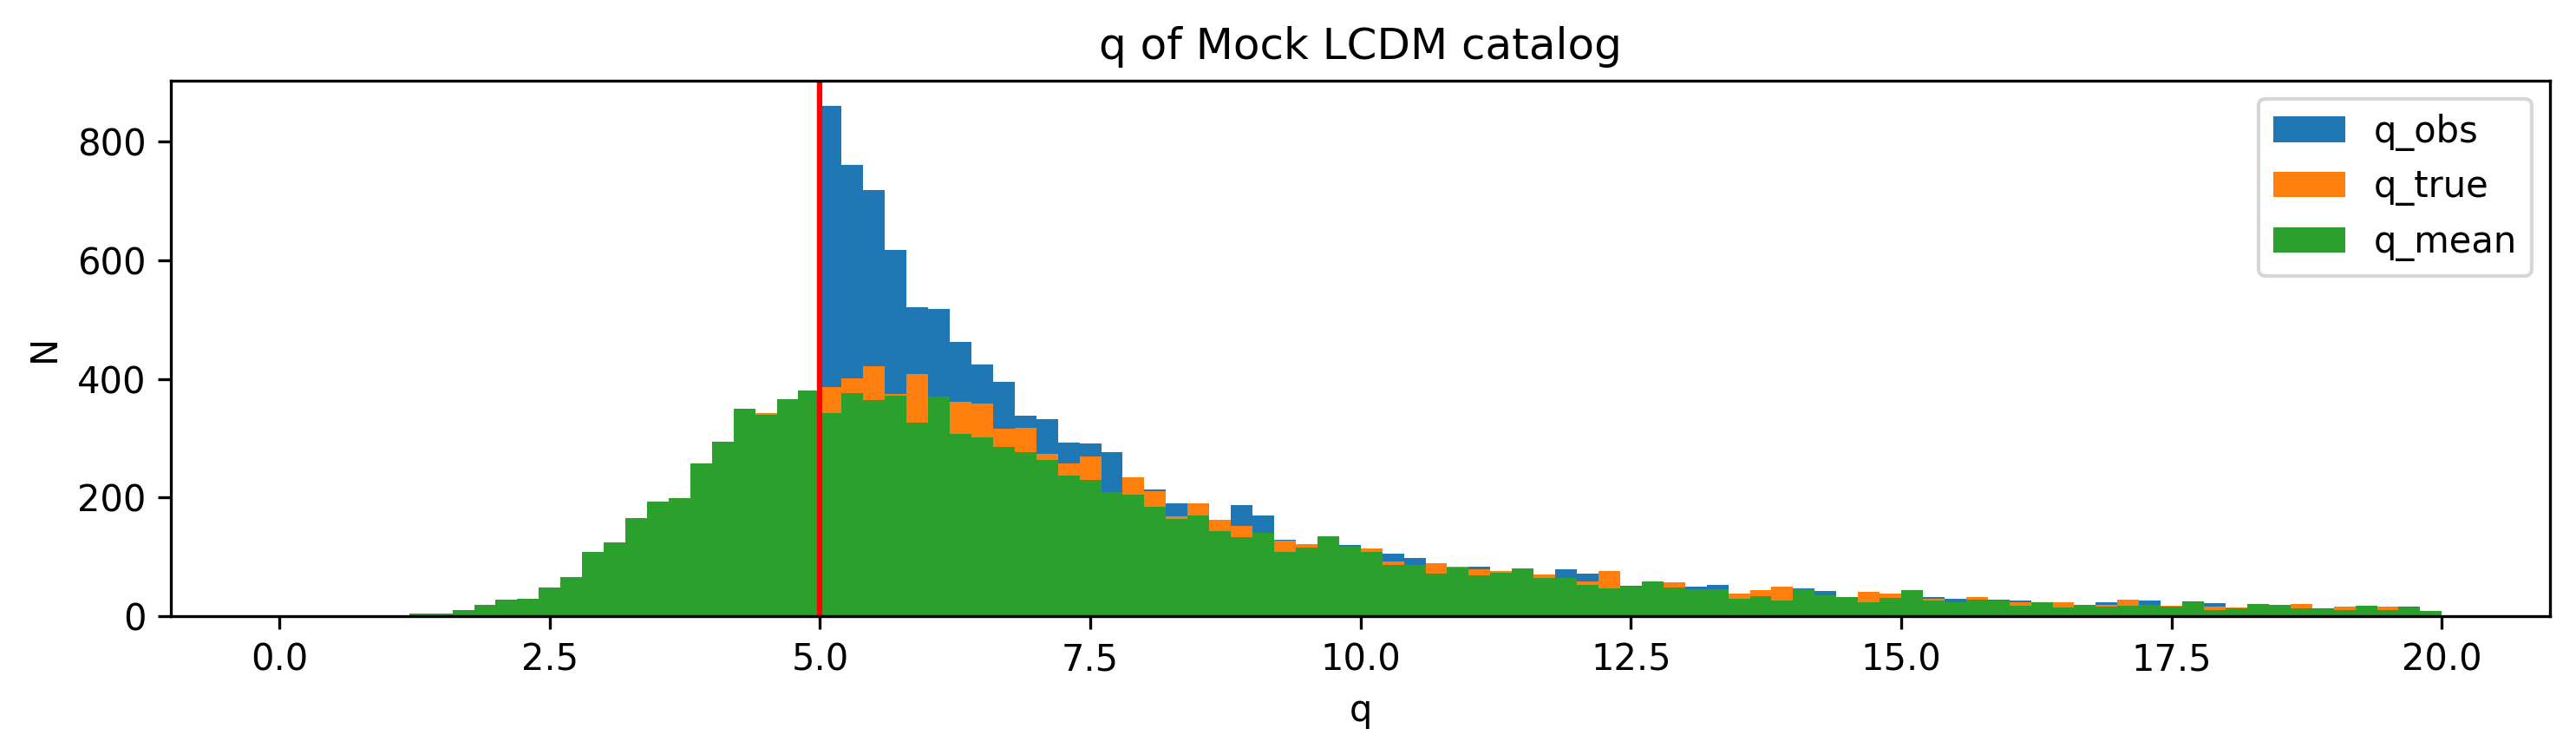

In [34]:
fig, axes = plt.subplots(1, 1, figsize=(10, 3), dpi=300)

axes.hist(cats['LCDM_DES']['q_obs'], bins=100, range=(0, 20), label='q_obs')
axes.hist(cats['LCDM_DES']['q_true'], bins=100, range=(0, 20), label='q_true')
axes.hist(cats['LCDM_DES']['q_mean'], bins=100, range=(0, 20), label='q_mean')
axes.axvline(cats['LCDM_DES']['Q_TH'], color='r')

axes.set_title("q of Mock LCDM catalog")
axes.set_xlabel("q")
axes.set_ylabel("N")
axes.legend()

plt.tight_layout()
plt.show()

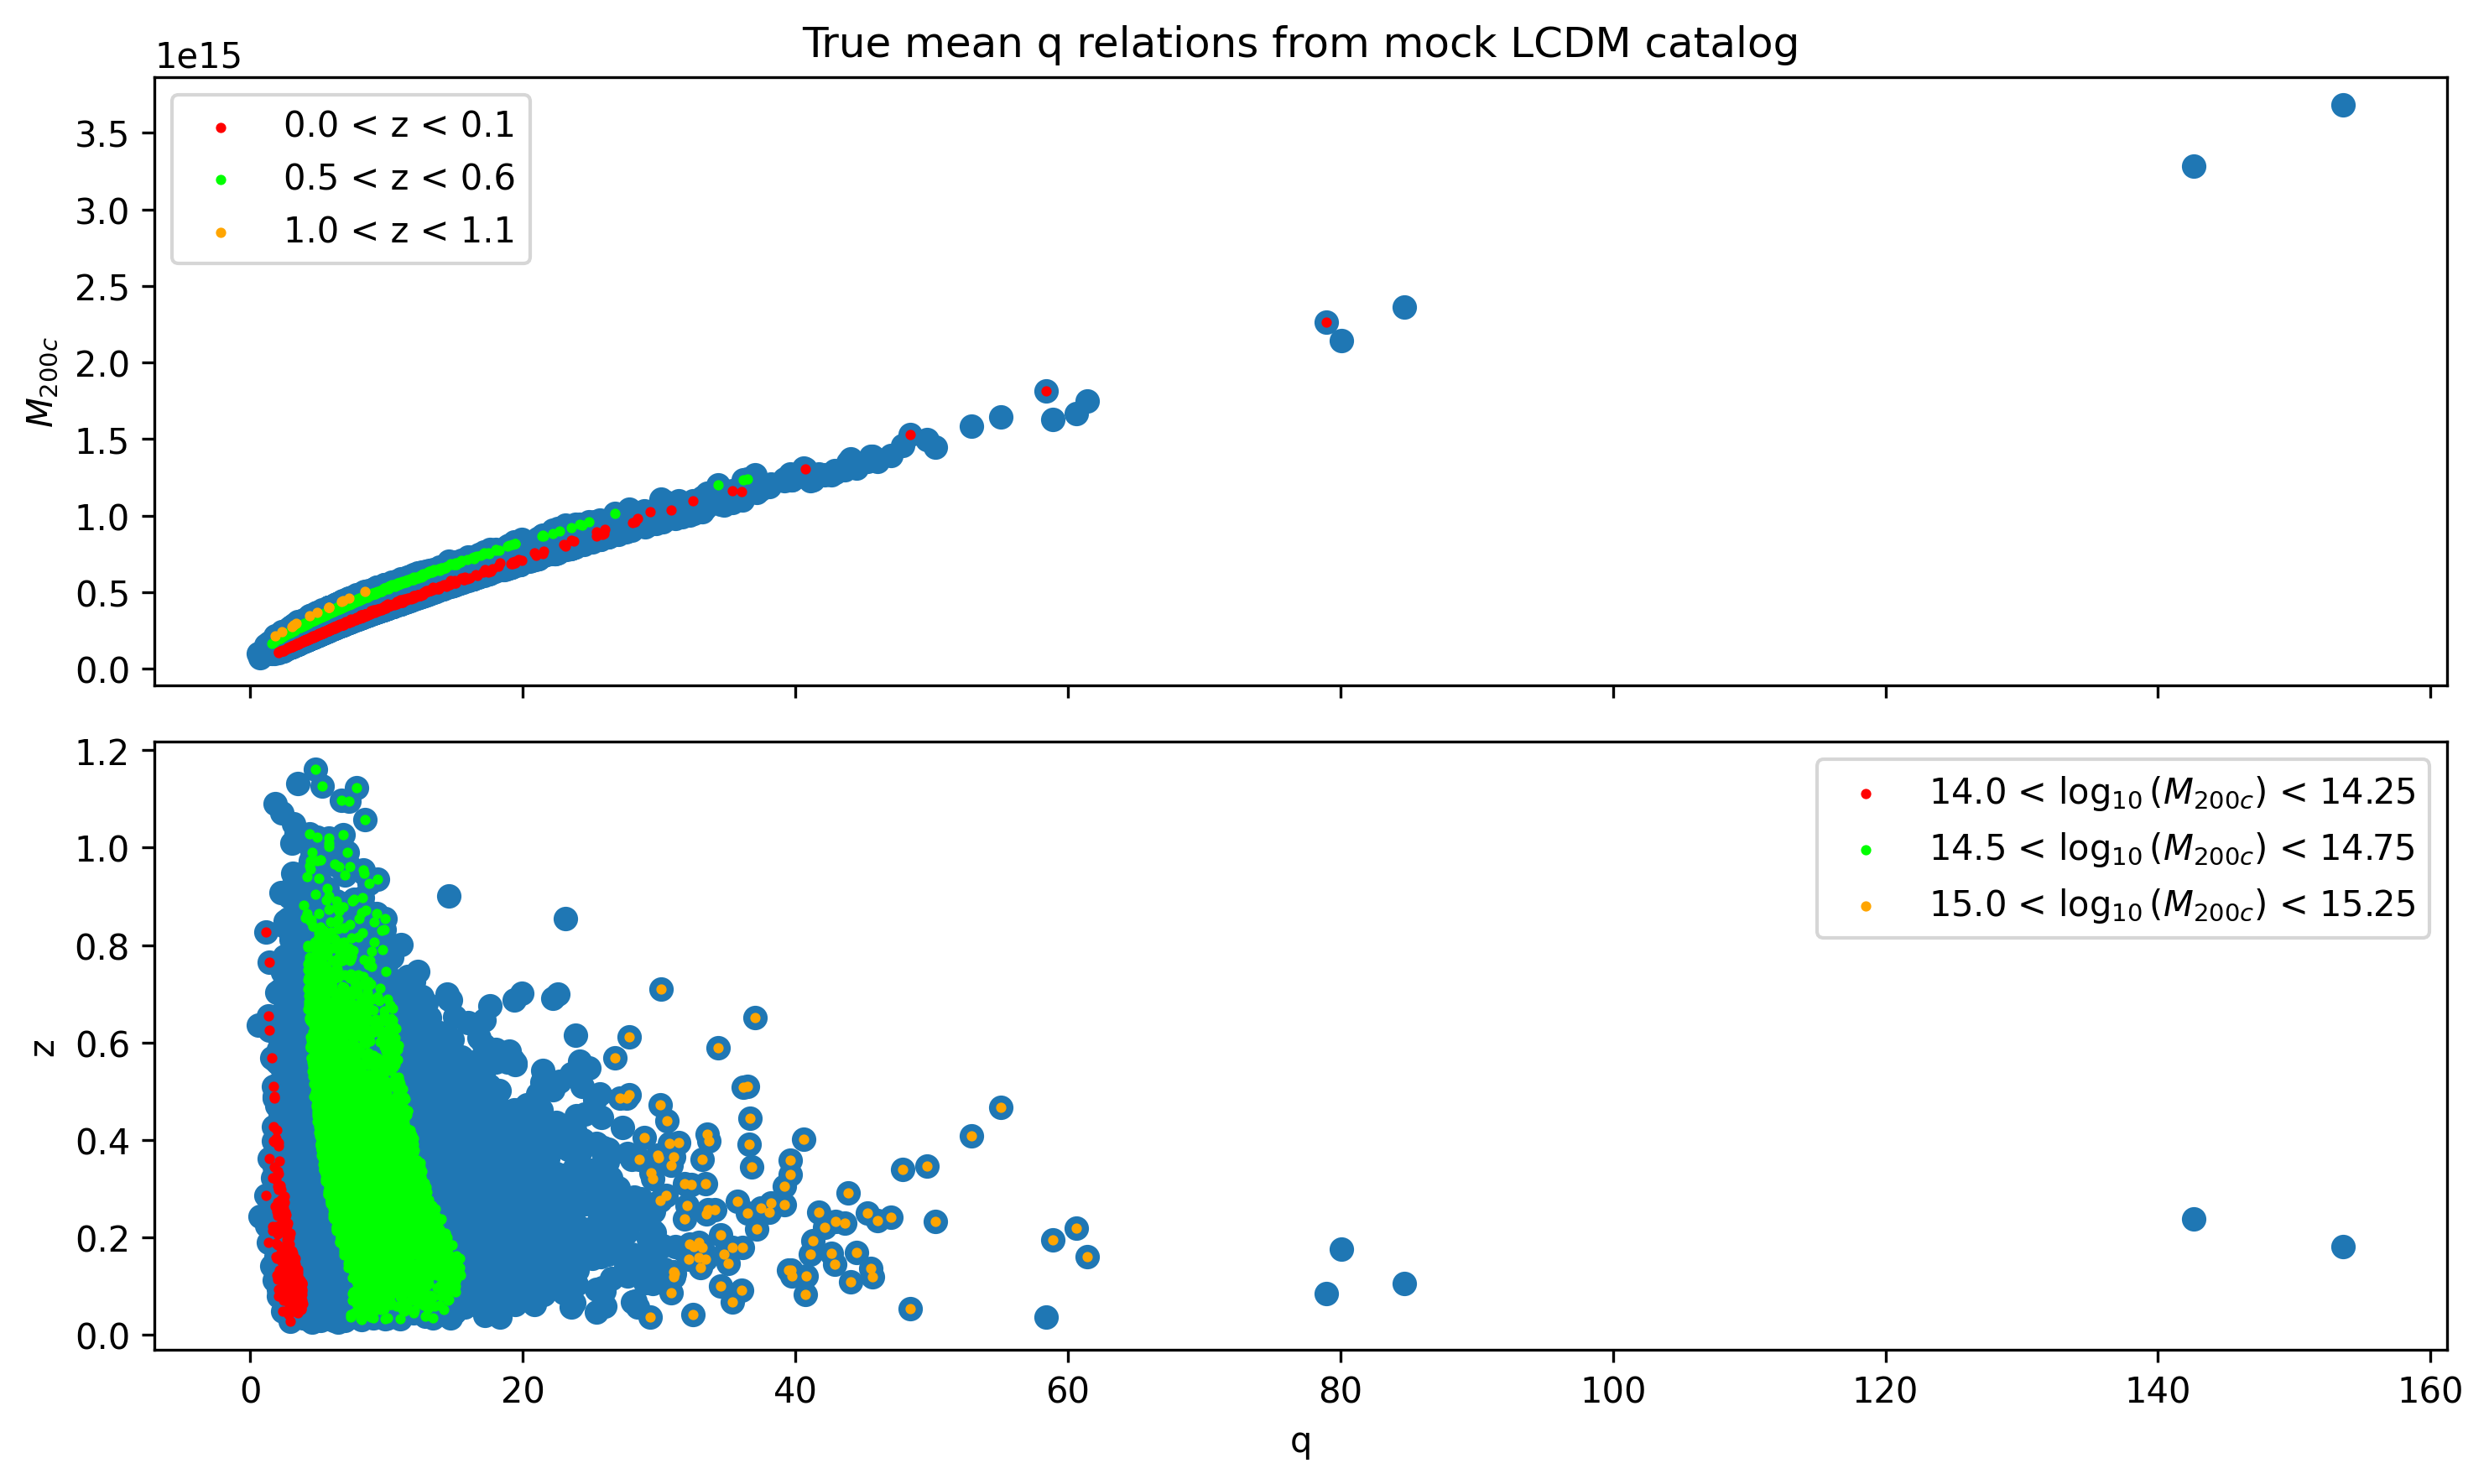

In [10]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_DES_mock_seed50.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), dpi=300, sharex=True)

ax0.scatter(catalogue['q_mean'],catalogue['M200c_true'])

zmin, zmax = 0.0, 0.1
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='red', s=15, label=f'{zmin} < z < {zmax}', marker='.')

zmin, zmax = 0.5, 0.6
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='lime', s=15, label=f'{zmin} < z < {zmax}', marker='.')

zmin, zmax = 1.0, 1.1
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='orange', s=15, label=f'{zmin} < z < {zmax}', marker='.')
ax0.legend()
ax0.set_ylabel(r"$M_{{200c}}$")

ax1.scatter(catalogue['q_mean'],catalogue['z'])

Mmin, Mmax = 10**14, 10**14.25
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='red', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')
Mmin, Mmax = 10**14.5, 10**14.75
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='lime', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')
Mmin, Mmax = 10**15, 10**15.25
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='orange', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')

ax1.legend()
ax1.set_ylabel("z")

ax1.set_xlabel("q")
ax0.set_title("True mean q relations from mock LCDM catalog")
plt.tight_layout()
plt.show()

###### Fiducial SZ Params

In [5]:
import pickle
import numpy as np
from scipy.optimize import minimize, brentq, least_squares

import os
os.environ["TOMOGRAPHIC_BINS"] = "DES"
from mcmc_likelihood import get_log_likelihood
from cosmocnc_axionHMcode_jax.cosmocnc_jax.surveys.survey_sr_so_sim import (
    precompute_q_prefactors, sr_q_so_sim_layer0, sr_q_so_sim_layer1
)
from cosmocnc_axionHMcode_jax.cosmocnc_jax.mass_conversion import _nfw_m, _nfw_m_prime

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/
defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/cosmocnc_axionHMcode_jax/cosmocnc_jax/
cache_suffix = 
Loaded precomputed tables from cache
Shear cache already made


In [6]:
SEEDS = [50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75]
A_sz_fid_vals = {}
alpha_sz_fid_vals = {}
beta_sz_fid_vals = {}

In [32]:
# ── Fiducials
h_fid = 0.68
omega_m_fid = 0.143344
A_s_fid = 2.1e-9
bias_sz = 0.8
dof = 0
x0_guess = (-4.3054, 1.1233, 2.0)

for SEED in SEEDS:
    if SEED not in A_sz_fid_vals.keys():
        try:
            CATALOGUE_PATH = f"/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_DES_mock_seed{SEED}.pkl"
        
            # ── Build a fresh nc -- needed for E_z, D_A, sigma_sz_poly, and HMF weight ──
            _, nc = get_log_likelihood(
                catalogue_name=CATALOGUE_PATH,
                omega_m=omega_m_fid, A_s=A_s_fid,
                A_sz=x0_guess[0], alpha_sz=x0_guess[1], beta_sz=x0_guess[2],
                b_WL_0=0.0, b_WL_z=0.0, b_WL_M=1.0, return_nc=True, observables=[['q_so_sim']])
            nc.get_hmf(return_profile_params=True)
            sigma_sz_poly = nc.scaling_relations['q_so_sim'].sigma_sz_poly
            log_theta_min = nc.scaling_relations['q_so_sim'].log_theta_min          # same bounds object the
            log_theta_max = nc.scaling_relations['q_so_sim'].log_theta_max          # likelihood itself uses
            
            # ── Load the catalog directly -- use its OWN, actual per-cluster z and q_mean ──
            with open(CATALOGUE_PATH, "rb") as f:
                cat = pickle.load(f)
            
            cat_z = np.asarray(cat['z'])              # actual, per-cluster redshifts -- no synthetic grid
            cat_M200c_h = np.asarray(cat['M200c_true'])  # Msol/h -- confirmed this is what's actually stored
            cat_q_mean = np.asarray(cat['q_mean'])
            
            print(f"catalog: {len(cat_z)} clusters, z range [{cat_z.min():.3f}, {cat_z.max():.3f}]")
            
            def nfw_m500c_conversions(c500c, n_iter=15):
                """Given c500c, returns (M200c/M500c, c200c) from the same Newton solve."""
                m_c500 = _nfw_m(c500c)
                def step(_, y):
                    cy = c500c * y
                    mc = _nfw_m(cy)
                    F  = 2.5 * y**(-3) - m_c500 / mc
                    Fp = -7.5 * y**(-4) + (m_c500 * c500c * _nfw_m_prime(cy)) / (mc**2)
                    return y - F / Fp
                y0 = np.full_like(c500c, 1.5)
                y = y0
                for i in range(n_iter):
                    y = step(i, y)
                M200_over_M500 = (y**3) / 2.5
                c200c = c500c * y
                return M200_over_M500, c200c
            
            # Get concentration_500c at a first-pass guess of M500c (M200c as a starting
            # point, since we don't have M500c yet), then iterate once to refine
            lnM500c_guess = np.log(cat_M200c_h / h_fid / 1e14)  # first-pass: M500c ~ M200c
            profile_guess = nc.get_profile_params_at_clusters(cat_z, lnM500c_guess[:, None])
            c500c_guess = profile_guess['concentration_500c'][:, 0]
            
            M200_over_M500_guess, _ = nfw_m500c_conversions(c500c_guess)
            cat_M500c_h = cat_M200c_h / M200_over_M500_guess   # first-pass M500c
            
            # one refinement pass: re-derive concentration at the refined M500c, redo the ratio
            lnM500c_refined = np.log(cat_M500c_h / h_fid / 1e14)
            profile_refined = nc.get_profile_params_at_clusters(cat_z, lnM500c_refined[:, None])
            c500c_refined = profile_refined['concentration_500c'][:, 0]
            M200_over_M500_refined, _ = nfw_m500c_conversions(c500c_refined)
            cat_M500c_h = cat_M200c_h / M200_over_M500_refined  # final M500c
            
            print(f"M200c/M500c ratio: mean={np.mean(M200_over_M500_refined):.3f}  "
                  f"std={np.std(M200_over_M500_refined):.3f}")
        
            z_unique = np.unique(cat_z)
            Ez_by_z, DA_by_z = {}, {}
            for z in z_unique:
                iz = np.argmin(np.abs(np.asarray(nc.redshift_vec) - z))
                Ez_by_z[z] = float(nc.E_z[iz])
                DA_by_z[z] = float(nc.D_A[iz])
                mask = (cat_z == z)
        
            # ── The fit itself, against the catalog's own actual q_mean, at its own z ──
            def residual(params):
                A_sz, alpha_sz, beta_sz = params
                q_pred = np.empty_like(cat_q_mean)
                for z in z_unique:
                    mask = (cat_z == z)
                    prefactor_logy0, prefactor_M_500_to_theta = precompute_q_prefactors(
                        Ez_by_z[z], h_fid * 100., DA_by_z[z], A_sz, bias_sz, alpha_sz, beta_sz)
                    x0_500 = np.log(cat_M500c_h[mask] / h_fid / 1e14)
                    x1, _ = sr_q_so_sim_layer0(x0_500, prefactor_logy0, prefactor_M_500_to_theta,
                                                 sigma_sz_poly, alpha_sz,
                                                 log_theta_min=log_theta_min, log_theta_max=log_theta_max)
                    q_pred[mask] = np.asarray(
                        sr_q_so_sim_layer1(x1, prefactor_logy0, prefactor_M_500_to_theta, dof))
                res = (q_pred - cat_q_mean)
                print(
                    f"A_sz={A_sz:.9f}, alpha_sz={alpha_sz:.9f}, beta_sz={beta_sz:.9f}, sum res^2={np.sum(res**2):.9f}"
                )
                    
                return res
            
            result = least_squares(residual, x0=np.asarray(x0_guess), method='lm')
            A_sz_fit, alpha_sz_fit, beta_sz_fit = result.x
            
            print(f"SEED {SEED} fitted: A_sz_fid={A_sz_fit:.9f}  alpha_sz_fid={alpha_sz_fit:.9f}  beta_sz_fid={beta_sz_fit:.9f}, residual cost: {result.cost:.9e}")
            A_sz_fid_vals[SEED] = A_sz_fit 
            alpha_sz_fid_vals[SEED] = alpha_sz_fit
            beta_sz_fid_vals[SEED] = beta_sz_fit
        except:
            print(f"Seed {SEED} couldn't be done")
            continue
    else:
        print(f"Seed {SEED} already done")
        continue

Seed 50 already done
Seed 51 already done
Seed 52 already done
Seed 53 already done
Seed 54 already done
Seed 55 already done
Seed 56 already done
Seed 57 already done
Seed 58 already done
Seed 59 already done
Seed 60 already done
Seed 61 already done
Seed 62 already done
Seed 63 already done
Seed 64 already done
Seed 65 already done
Seed 66 already done
Seed 67 already done
Seed 68 already done
Seed 69 already done
Seed 70 already done
Seed 71 already done
Seed 72 already done
Seed 73 already done
Seed 74 already done
Seed 75 already done


Mean A     : -4.352890598769685 +- 1.2228740514484122e-05
Mean alpha : 1.1991734303623067 +- 9.808281482777838e-05
Mean beta  : 1.9996943667059135 +- 0.0001709912069868937


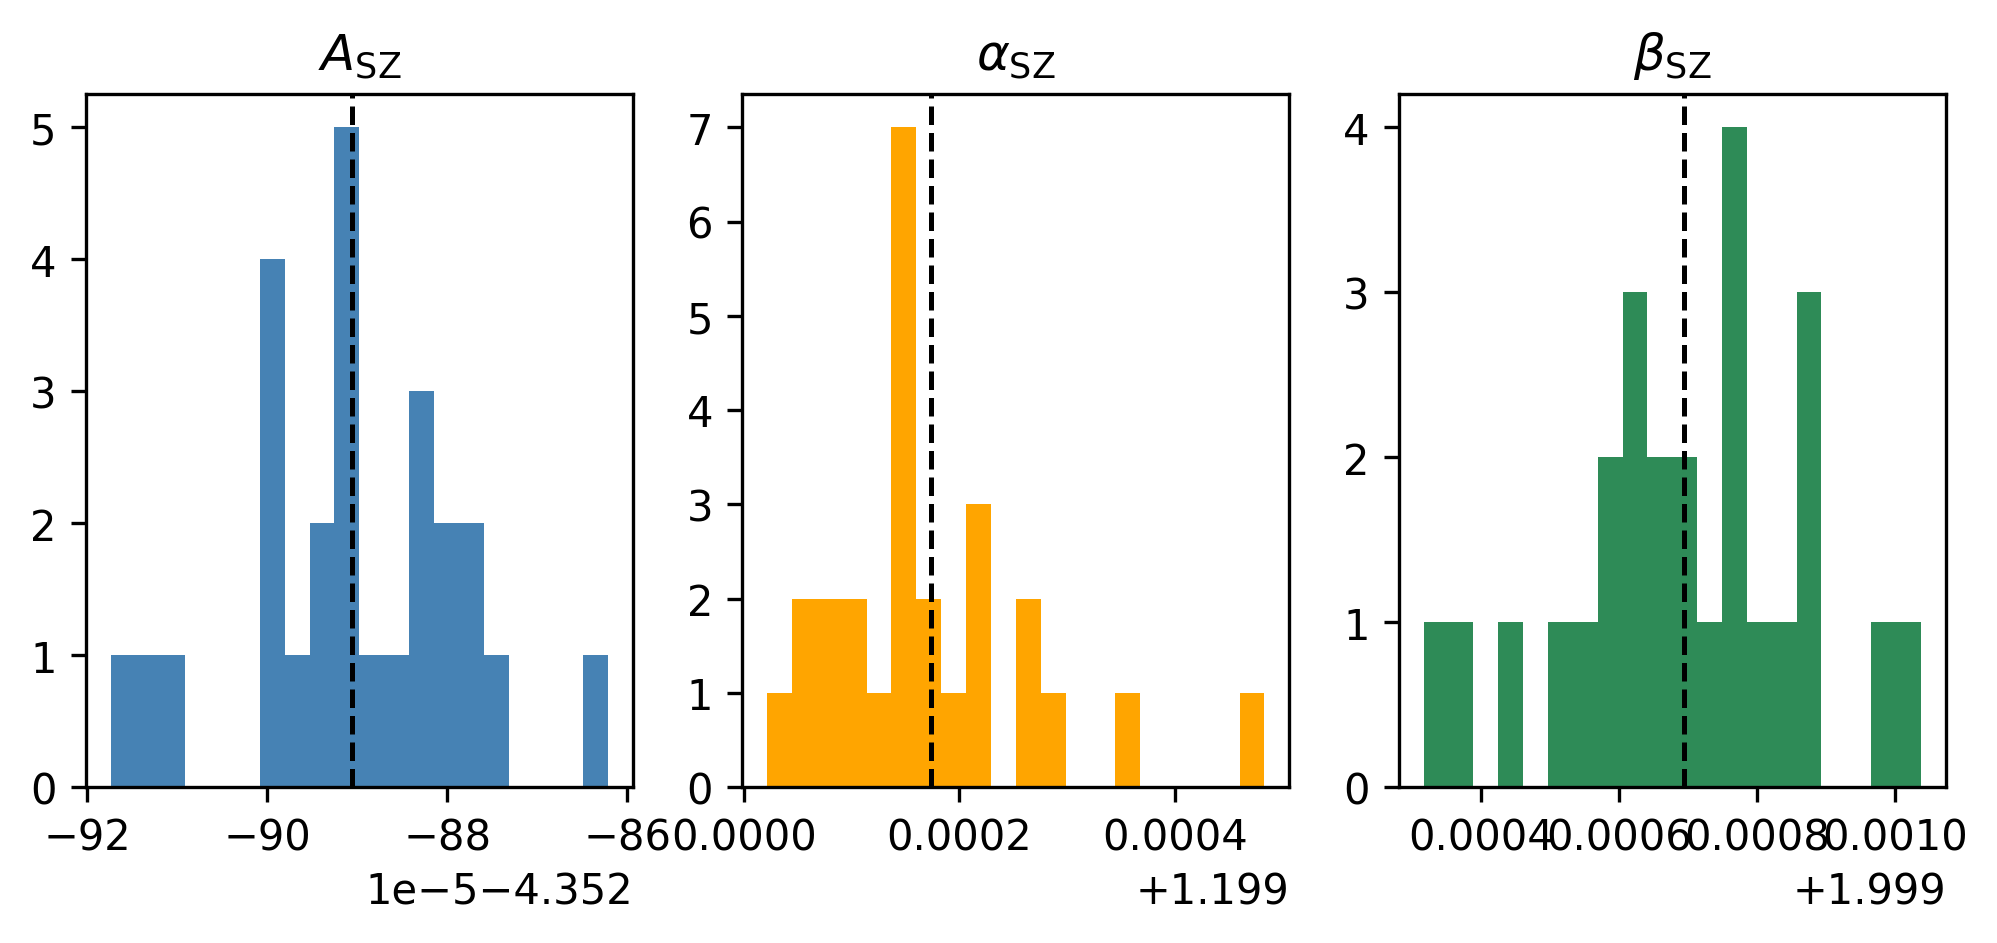

In [55]:
fig, (ax_A, ax_alpha, ax_beta) = plt.subplots(1, 3, figsize=(8,3), dpi=300)

mean_A = np.mean(list(A_sz_fid_vals.values()))
mean_alpha = np.mean(list(alpha_sz_fid_vals.values()))
mean_beta = np.mean(list(beta_sz_fid_vals.values()))

ax_A.hist(A_sz_fid_vals.values(), bins=20, color='steelblue')
ax_A.set_title(r"$A_\text{SZ}$")
ax_alpha.hist(alpha_sz_fid_vals.values(), bins=20, color='orange')
ax_alpha.set_title(r"$\alpha_\text{SZ}$")
ax_beta.hist(beta_sz_fid_vals.values(), bins=20, color='seagreen')
ax_beta.set_title(r"$\beta_\text{SZ}$")

for ax, vals in zip(
    (ax_A, ax_alpha, ax_beta),
    (A_sz_fid_vals.values(), alpha_sz_fid_vals.values(), beta_sz_fid_vals.values())
):
    mean = np.mean(list(vals))
    ax.axvline(mean, color='black', linestyle='--', linewidth=1.2)

print(f"Mean A     : {mean_A} +- {np.std(list(A_sz_fid_vals.values()))}")
print(f"Mean alpha : {mean_alpha} +- {np.std(list(alpha_sz_fid_vals.values()))}")
print(f"Mean beta  : {mean_beta} +- {np.std(list(beta_sz_fid_vals.values()))}")

###### Theory comparison

In [56]:
import os
import pickle
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import integrate
from scipy.special import erf

# ── CONFIG — must match generate_mock_catalogs.py exactly ───────────────────
HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
MOCK_DIR        = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
HMF_TYPE        = "LCDM_DES"
SEEDS           = [50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75]

FSKY  = 0.4
Q_TH  = 5.0
Q_MIN = 0.4 + 1e-6
Q_FLOOR = 0.4
SIGMA_LN_Q_INTRINSIC = 0.173
SIGMA_Q_OBS          = 1.0

M_TRANSITION = 10**12.5
M_MIN_SAMPLE = 10**12.5
M_MAX_SAMPLE = 1e16
NUM_M_SAMPLE = 300
ln_M_target  = np.linspace(np.log(M_MIN_SAMPLE), np.log(M_MAX_SAMPLE), NUM_M_SAMPLE)
M_target     = np.exp(ln_M_target)

Z_ARR = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1.0 / K_ARR.min()), 1500)

# Bin edges for the comparison plots
M_edges = np.linspace(14.0, 15.7, 18)
z_edges = np.linspace(0.0,  2.0,  18)
q_edges = np.logspace(np.log10(3.0), np.log10(400.), 18)

# ── IMPORTS ───────────────────────────────────────────────────────────────────
from feedback_mimic import (
    dn_dlog10Mtot, get_NFW_profile, get_realspace_profile,
    dV_dz, profile_to_q, Mtot_to_MDelta, get_some_quantities,
)


def bin_2d_to_1d_simpson(hist2d, z_arr, lnM_arr, edges, target_is_M):
    """
    Integrate hist2d (n_z, n_M) into 1D bins via cumulative-CDF differencing.
    """
    if target_is_M:
        dN_dlnM = integrate.simpson(hist2d, x=z_arr, axis=0)   # (n_M,) -- density per d(lnM)
        log10_M = lnM_arr / np.log(10.)
        # Integrate in ln(M) directly (native units of dN_dlnM), THEN
        # interpolate the resulting CDF at the log10(M) bin edges.
        cdf_full = integrate.cumulative_simpson(dN_dlnM, x=lnM_arr, initial=0.0)
        cdf_at_edges = np.interp(edges, log10_M, cdf_full)
        return np.diff(cdf_at_edges)
    else:
        dN_dz = integrate.simpson(hist2d, x=lnM_arr, axis=1)   # (n_z,)
        cdf_full = integrate.cumulative_simpson(dN_dz, x=z_arr, initial=0.0)
        cdf_at_edges = np.interp(edges, z_arr, cdf_full)
        return np.diff(cdf_at_edges)


def smoothstep_taper(q_of_M200c, q_floor=Q_FLOOR, q_min_soft=Q_MIN):
    x = (q_of_M200c - q_floor) / (q_min_soft - q_floor)
    t = np.clip(x, 0., 1.)
    return t**2 * (3. - 2. * t)


def selection_probability_exact(q_mean_grid, n_eps=1024,
                                 sigma_lnq=SIGMA_LN_Q_INTRINSIC,
                                 sigma_qobs=SIGMA_Q_OBS, q_th=Q_TH):
    """P(q_obs > Q_TH | q_mean), marginalising the intrinsic lognormal scatter."""
    q_mean_grid = np.asarray(q_mean_grid)
    eps  = np.linspace(-6 * sigma_lnq, 6 * sigma_lnq, n_eps)
    w    = np.exp(-0.5 * (eps / sigma_lnq)**2)
    w   /= np.trapezoid(w, eps)
    q_t  = q_mean_grid[None, :, :] * np.exp(eps[:, None, None])
    arg  = (q_th - q_t) / sigma_qobs
    p    = 0.5 * (1. - erf(arg / np.sqrt(2.)))
    return np.trapezoid(w[:, None, None] * p, eps, axis=0)


# ── BUILD THEORY: exactly mirrors generate_mock_catalogs.py's hmf_M_matrix ──

print("Building theory hmf_M_matrix and q_mean_grid (mirrors generator)...")

hmf_M_matrix = np.zeros((len(Z_ARR), NUM_M_SAMPLE))
q_mean_grid  = np.zeros_like(hmf_M_matrix)

for iz, z in enumerate(Z_ARR):
    with open(f"{HALO_INPUT_FILE}/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data = pickle.load(f)

    Mtot, hmf_log10 = dn_dlog10Mtot(data, "LCDM")
    hmf = hmf_log10 / np.log(10)

    r_t, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = \
        get_some_quantities(data)

    rho = get_realspace_profile(
        u_k=get_NFW_profile(r_v=r_t, k_arr=K_ARR, r_s=r_s, r_t=r_t),
        r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot, r_t=r_t)

    valid = Mtot > M_TRANSITION
    Mtot_v = Mtot[valid]; hmf_v = hmf[valid]; rho_v = rho[valid]; r_t_v = r_t[valid]

    M200c, _ = Mtot_to_MDelta(
        data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
        Del=200, reference_density="critical",
        rho=rho_v, k_arr=K_ARR)

    q_of_M200c = profile_to_q(
        data, rho=rho_v, r_t=r_t_v, M_arr=Mtot_v, k_arr=K_ARR, r_arr=R_ARR,
        bias_sz=0.8, dof=0.0, axion_dic=None)

    hmf_M200c = hmf_v * np.gradient(np.log(Mtot_v)) / np.gradient(np.log(M200c))

    order = np.argsort(M200c)
    M200c_s = M200c[order]; hmf_M200c_s = hmf_M200c[order]; q_s = q_of_M200c[order]

    # SAME smoothstep taper as the current generator (NOT the old hard Q_MIN mask).
    # NOTE: this taper is a near-threshold *numerical floor* (kills negligible-q
    # contributions below Q_FLOOR for interpolation stability) — it is NOT the
    # detection selection function itself. The detection selection function is
    # applied separately below via `selection_probability_exact`. Both the
    # "with-selection" and "without-selection" theory curves include this taper,
    # since it is a property of the underlying grid, not of detection.
    taper = smoothstep_taper(q_s)
    hmf_M200c_masked = hmf_M200c_s * taper

    hmf_M_matrix[iz] = np.interp(
        ln_M_target, np.log(M200c_s), hmf_M200c_masked * dV_dz(data),
        left=0., right=0.)

    q_mean_grid[iz] = np.interp(
        ln_M_target, np.log(M200c_s), q_s,
        left=q_s[0], right=q_s[-1])

hmf_M_fsky = hmf_M_matrix * FSKY   # matches generator's hmf_M_fsky exactly (no selection yet)

# ── THEORY: with and without the detection selection function ───────────────

Psel       = selection_probability_exact(q_mean_grid)
hmf_sel    = hmf_M_fsky * Psel     # dN/(dlnM dz), fsky included, AFTER detection
hmf_no_sel = hmf_M_fsky            # dN/(dlnM dz), fsky included, BEFORE detection

n_mean_theory_sel    = integrate.simpson(
    integrate.simpson(hmf_sel, x=ln_M_target, axis=1), x=Z_ARR)
n_mean_theory_no_sel = integrate.simpson(
    integrate.simpson(hmf_no_sel, x=ln_M_target, axis=1), x=Z_ARR)
print(f"Theory mean N (after selection)  = {n_mean_theory_sel:.2f}")
print(f"Theory mean N (before selection) = {n_mean_theory_no_sel:.2f}")

# Per-(z,M)-cell weights for the histogram-style q binning (Simpson is used
# directly for the M and z theory curves via bin_2d_to_1d_simpson below).
dlnM = np.gradient(ln_M_target)
dz   = np.gradient(Z_ARR)
weights_theory_sel    = hmf_sel    * dlnM[None, :] * dz[:, None]   # (n_z, n_M)
weights_theory_no_sel = hmf_no_sel * dlnM[None, :] * dz[:, None]

# ── THEORY HISTOGRAMS (M, z via Simpson-per-bin; q via weighted histogram) ──

theory_M_sel    = bin_2d_to_1d_simpson(hmf_sel,    Z_ARR, ln_M_target, M_edges, target_is_M=True)
theory_M_no_sel = bin_2d_to_1d_simpson(hmf_no_sel, Z_ARR, ln_M_target, M_edges, target_is_M=True)

theory_z_sel    = bin_2d_to_1d_simpson(hmf_sel,    Z_ARR, ln_M_target, z_edges, target_is_M=False)
theory_z_no_sel = bin_2d_to_1d_simpson(hmf_no_sel, Z_ARR, ln_M_target, z_edges, target_is_M=False)

theory_q_sel, _    = np.histogram(q_mean_grid.ravel(), bins=q_edges, weights=weights_theory_sel.ravel())
theory_q_no_sel, _ = np.histogram(q_mean_grid.ravel(), bins=q_edges, weights=weights_theory_no_sel.ravel())

# ── LOAD MOCKS: WITH selection (existing *_mock_seed{N}.pkl files) ──────────

print("\nLoading selected-cluster mock catalogs...")
mock_M_sel_list, mock_z_sel_list, mock_q_sel_list = [], [], []
n_sel_per_seed = []

for seed in SEEDS:
    path = f"{MOCK_DIR}/{HMF_TYPE}_mock_seed{seed}.pkl"
    with open(path, "rb") as f:
        cat = pickle.load(f)

    M200c_mock = np.asarray(cat['M200c_true'])   # Msol/h
    z_mock     = np.asarray(cat['z'])
    q_mock     = np.asarray(cat['q_mean'])       # noiseless q-M scaling relation value

    n_sel_per_seed.append(cat['n_selected'])

    h_M, _ = np.histogram(np.log10(M200c_mock), bins=M_edges)
    h_z, _ = np.histogram(z_mock,                bins=z_edges)
    h_q, _ = np.histogram(q_mock,                bins=q_edges)

    mock_M_sel_list.append(h_M)
    mock_z_sel_list.append(h_z)
    mock_q_sel_list.append(h_q)

mock_M_sel = np.array(mock_M_sel_list)   # (n_seeds, n_bins)
mock_z_sel = np.array(mock_z_sel_list)
mock_q_sel = np.array(mock_q_sel_list)

print(f"n_selected per seed: {n_sel_per_seed}")
print(f"mean n_selected: {np.mean(n_sel_per_seed):.1f}  (theory: {n_mean_theory_sel:.1f})")

# ── LOAD MOCKS: WITHOUT selection (new *_all_halos_seed{N}.pkl files) ───────
# These contain the FULL Poisson-drawn halo population (n_tot, pre-detection):
# M200c_true, z, q_mean only — no q_obs/q_true, no wl_data.

print("\nLoading all-halos (pre-selection) mock catalogs...")
mock_M_nosel_list, mock_z_nosel_list, mock_q_nosel_list = [], [], []
n_tot_per_seed = []

for seed in SEEDS:
    path = f"{MOCK_DIR}/{HMF_TYPE}_mock_seed{seed}_noselection.pkl"
    with open(path, "rb") as f:
        cat_all = pickle.load(f)

    M200c_all = np.asarray(cat_all['M200c_true'])   # Msol/h
    z_all     = np.asarray(cat_all['z'])
    q_all     = np.asarray(cat_all['q_mean'])

    n_tot_per_seed.append(cat_all['n_tot_draw'])

    h_M, _ = np.histogram(np.log10(M200c_all), bins=M_edges)
    h_z, _ = np.histogram(z_all,                bins=z_edges)
    h_q, _ = np.histogram(q_all,                bins=q_edges)

    mock_M_nosel_list.append(h_M)
    mock_z_nosel_list.append(h_z)
    mock_q_nosel_list.append(h_q)

mock_M_nosel = np.array(mock_M_nosel_list)
mock_z_nosel = np.array(mock_z_nosel_list)
mock_q_nosel = np.array(mock_q_nosel_list)

print(f"n_tot per seed: {n_tot_per_seed}")
print(f"mean n_tot: {np.mean(n_tot_per_seed):.1f}  (theory: {n_mean_theory_no_sel:.1f})")

n_seeds = len(SEEDS)

Building theory hmf_M_matrix and q_mean_grid (mirrors generator)...


/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")


Theory mean N (after selection)  = 10978.73
Theory mean N (before selection) = 381758.22

Loading selected-cluster mock catalogs...
n_selected per seed: [np.int64(11082), np.int64(11051), np.int64(11018), np.int64(11099), np.int64(11047), np.int64(11036), np.int64(10981), np.int64(10771), np.int64(10986), np.int64(10931), np.int64(10934), np.int64(10717), np.int64(10917), np.int64(10794), np.int64(11041), np.int64(10920), np.int64(10992), np.int64(11020), np.int64(11016), np.int64(10938), np.int64(10987), np.int64(10937), np.int64(10952), np.int64(10893), np.int64(10947), np.int64(11103)]
mean n_selected: 10965.8  (theory: 10978.7)

Loading all-halos (pre-selection) mock catalogs...
n_tot per seed: [382313, 383046, 381963, 381454, 381227, 382431, 382176, 382091, 381411, 381912, 381441, 381536, 381951, 381863, 383061, 380310, 382852, 381608, 381731, 381899, 381547, 381297, 382448, 381745, 382665, 381205]
mean n_tot: 381891.7  (theory: 381758.2)


In [57]:
# ── PRINT DIAGNOSTIC TABLES ───────────────────────────────────────────────────

def print_comparison_table(name, theory_hist, mock_hist, centres):
    mean = mock_hist.mean(axis=0)
    sem  = mock_hist.std(axis=0) / np.sqrt(n_seeds)
    frac_offset = (mean - theory_hist) / np.maximum(theory_hist, 1e-30)
    frac_sem    = sem / np.maximum(theory_hist, 1e-30)
    poisson_on_mean = 1.0 / np.sqrt(np.maximum(theory_hist, 1.0) * n_seeds)

    print(f"\n{name}:")
    print(f"{'centre':>10} {'theory':>10} {'mock_mean':>10} {'frac_off':>10} "
          f"{'frac_SEM':>10} {'poisson_mean':>13}")
    for i in range(len(centres)):
        if theory_hist[i] > 0.5:
            print(f"{centres[i]:>10.3f} {theory_hist[i]:>10.2f} {mean[i]:>10.2f} "
                  f"{frac_offset[i]:>10.4f} {frac_sem[i]:>10.4f} {poisson_on_mean[i]:>13.4f}")

M_centres = 0.5 * (M_edges[1:] + M_edges[:-1])
z_centres = 0.5 * (z_edges[1:] + z_edges[:-1])
q_centres = 0.5 * (q_edges[1:] + q_edges[:-1])

print_comparison_table("N(M200c) -- WITH selection",    theory_M_sel,    mock_M_sel,    M_centres)
print_comparison_table("N(M200c) -- WITHOUT selection", theory_M_no_sel, mock_M_nosel,  M_centres)
print_comparison_table("N(z) -- WITH selection",        theory_z_sel,    mock_z_sel,    z_centres)
print_comparison_table("N(z) -- WITHOUT selection",      theory_z_no_sel, mock_z_nosel,  z_centres)
print_comparison_table("N(q) -- WITH selection",        theory_q_sel,    mock_q_sel,    q_centres)
print_comparison_table("N(q) -- WITHOUT selection",      theory_q_no_sel, mock_q_nosel,  q_centres)


N(M200c) -- WITH selection:
    centre     theory  mock_mean   frac_off   frac_SEM  poisson_mean
    14.050      15.53      14.92    -0.0390     0.0454        0.0498
    14.150      78.51      79.58     0.0136     0.0193        0.0221
    14.250     352.97     347.96    -0.0142     0.0098        0.0104
    14.350    1193.80    1194.31     0.0004     0.0045        0.0057
    14.450    2570.94    2572.62     0.0007     0.0038        0.0039
    14.550    3008.47    2994.77    -0.0046     0.0027        0.0036
    14.650    1988.59    1989.27     0.0003     0.0042        0.0044
    14.750     993.68     996.92     0.0033     0.0058        0.0062
    14.850     457.30     460.88     0.0078     0.0088        0.0092
    14.950     195.56     190.27    -0.0270     0.0141        0.0140
    15.050      77.82      79.23     0.0181     0.0234        0.0222
    15.150      28.14      27.12    -0.0364     0.0401        0.0370
    15.250       9.19       9.58     0.0423     0.0775        0.0647
    1

In [68]:
from cosmocnc_axionHMcode_jax.cosmocnc_jax.mass_conversion import _nfw_m, _nfw_m_prime
def nfw_m500c_conversions(c500c, n_iter=15):
    """Given c500c, returns (M200c/M500c, c200c) from the same Newton solve."""
    m_c500 = _nfw_m(c500c)
    def step(_, y):
        cy = c500c * y
        mc = _nfw_m(cy)
        F  = 2.5 * y**(-3) - m_c500 / mc
        Fp = -7.5 * y**(-4) + (m_c500 * c500c * _nfw_m_prime(cy)) / (mc**2)
        return y - F / Fp
    y0 = np.full_like(c500c, 1.5)
    y = y0
    for i in range(n_iter):
        y = step(i, y)
    M200_over_M500 = (y**3) / 2.5
    c200c = c500c * y
    return M200_over_M500, c200c

# ── BUILD COSMOCNC THEORY CURVES (reuses ln_M_target, Z_ARR, q_mean_grid from above) ──

_, nc = get_log_likelihood(
        catalogue_name=CATALOGUE_PATH,
        omega_m=omega_m_fid, A_s=A_s_fid,
        A_sz=-4.352890598769685, alpha_sz=1.1991734303623067, beta_sz=1.9996943667059135,
        b_WL_0=0.0, b_WL_z=0.0, b_WL_M=1.0, return_nc=True, observables=[['q_so_sim'],['gt']],
        n_points = 300, n_mass_points_coarse=300, obs_select_max=300)

H_FID = 0.68
ln_M_nc = np.asarray(nc.ln_M)
M_nc_Msol = np.exp(ln_M_nc) * 1e14
M_nc_Msol_h = M_nc_Msol * H_FID
ln_M_nc_Msol_h = np.log(M_nc_Msol_h)
redshift_vec_nc = np.asarray(nc.redshift_vec)
hmf_matrix_nc   = np.asarray(nc.hmf_matrix).copy()# / H_FID**4   # already per-steradian, dn/dlnM500c * dV/dz/dOmega
#hmf_matrix_nc  *= H_FID # this is because we're in log mode, so have multiplied by mass (phys)

M500_full = np.asarray([[M_nc_Msol] * len(Z_ARR)])[0]
M_nc_Msol_200 = nfw_m500c_conversions(nc.profile_params['concentration_500c'])[0] * M500_full # M200c, physical Msol
dlnM500c_dlnM200c = np.gradient(np.log(M500_full),axis=1)/np.gradient(np.log(M_nc_Msol_200),axis=1)
hmf_matrix_nc  *= dlnM500c_dlnM200c 
ln_M_nc_Msol_h_200 = np.log(M_nc_Msol_200 * H_FID)

hmf_nc_on_grid = np.zeros((len(Z_ARR), NUM_M_SAMPLE))
for i, z in enumerate(Z_ARR):
    iz_nc = np.argmin(np.abs(redshift_vec_nc - z))
    hmf_nc_on_grid[i] = np.interp(
        ln_M_target, ln_M_nc_Msol_h_200[iz_nc], hmf_matrix_nc[iz_nc],
        left=0., right=0.)

hmf_nc_fsky = hmf_nc_on_grid * 4 * np.pi * FSKY   # matches theory's hmf_M_fsky convention exactly -- no 4pi

th_nc_M = bin_2d_to_1d_simpson(hmf_nc_fsky, Z_ARR, ln_M_target, M_edges, target_is_M=True)
th_nc_z = bin_2d_to_1d_simpson(hmf_nc_fsky, Z_ARR, ln_M_target, z_edges, target_is_M=False)
dlnM_nc = np.gradient(ln_M_target)
dz_nc   = np.gradient(Z_ARR)
weights_nc = hmf_nc_fsky * dlnM_nc[None, :] * dz_nc[:, None]
th_nc_q, _ = np.histogram(q_mean_grid.ravel(), bins=q_edges, weights=weights_nc.ravel())
n_mean_nc = integrate.simpson(integrate.simpson(hmf_nc_fsky, x=ln_M_target, axis=1), x=Z_ARR)
print(f"cosmocnc mean N = {n_mean_nc:.2f}")

cosmocnc mean N = 27436491.32


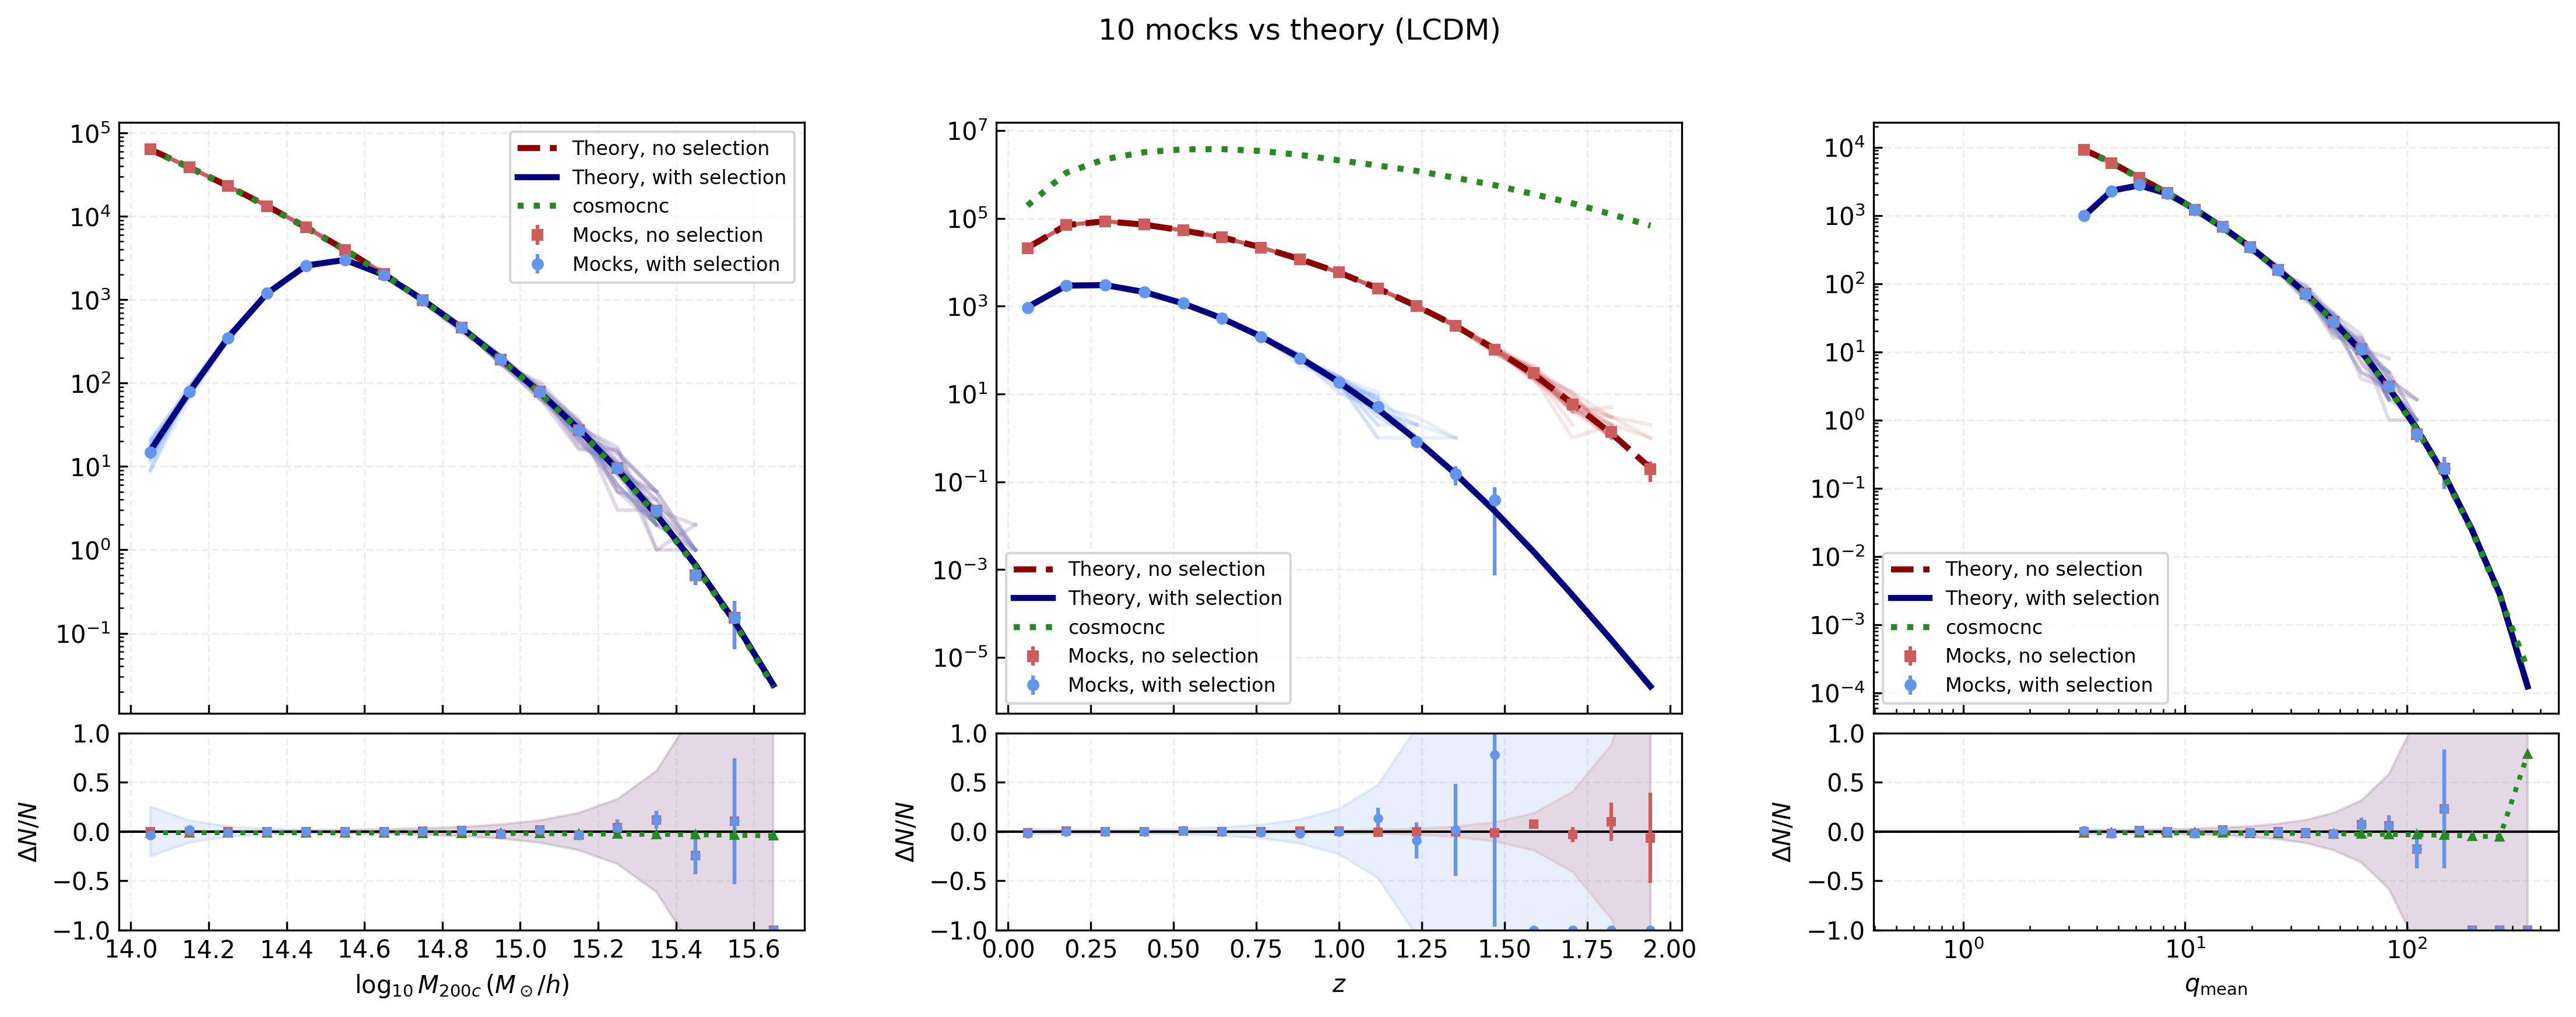

In [69]:
# ── PLOT ──────────────────────────────────────────────────────────────────────

fig = plt.figure(figsize=(18, 6), dpi=300)
gs  = fig.add_gridspec(2, 3, height_ratios=[3, 1], hspace=0.05, wspace=0.28)

panels = [
    (M_edges, mock_M_sel, mock_M_nosel, theory_M_sel, theory_M_no_sel, th_nc_M,
     r"$\log_{10} M_{200c}\,(M_\odot/h)$", False),
    (z_edges, mock_z_sel, mock_z_nosel, theory_z_sel, theory_z_no_sel, th_nc_z,
     r"$z$", False),
    (q_edges, mock_q_sel, mock_q_nosel, theory_q_sel, theory_q_no_sel, th_nc_q,
     r"$q_{\rm mean}$", True),
]
COL_SEL    = "cornflowerblue"
COL_NOSEL  = "indianred"
COL_THSEL  = "navy"
COL_THNOSL = "darkred"
COL_NC     = "forestgreen"

for panel, (edges, mocks_sel, mocks_nosel, th_sel, th_nosel, th_nc, xlabel, logx) in enumerate(panels):
    ax  = fig.add_subplot(gs[0, panel])
    axr = fig.add_subplot(gs[1, panel], sharex=ax)
    centres = 0.5 * (edges[1:] + edges[:-1])

    for m in mocks_nosel:
        ax.plot(centres, np.where(m > 0, m, np.nan), color=COL_NOSEL, alpha=0.15)
    for m in mocks_sel:
        ax.plot(centres, np.where(m > 0, m, np.nan), color=COL_SEL, alpha=0.15)

    mean_sel   = mocks_sel.mean(axis=0)
    sem_sel    = mocks_sel.std(axis=0) / np.sqrt(n_seeds)
    mean_nosel = mocks_nosel.mean(axis=0)
    sem_nosel  = mocks_nosel.std(axis=0) / np.sqrt(n_seeds)

    ax.errorbar(centres, mean_nosel, yerr=sem_nosel, fmt="s", ms=4,
                color=COL_NOSEL, label="Mocks, no selection")
    ax.errorbar(centres, mean_sel, yerr=sem_sel, fmt="o", ms=4,
                color=COL_SEL, label="Mocks, with selection")
    ax.plot(centres, th_nosel, color=COL_THNOSL, lw=2.5, ls="--", label="Theory, no selection")
    ax.plot(centres, th_sel,   color=COL_THSEL,  lw=2.5,          label="Theory, with selection")
    ax.plot(centres, th_nc,    color=COL_NC,     lw=2.5, ls=":",  label="cosmocnc")

    ax.set_yscale("log")
    if logx:
        ax.set_xscale("log"); axr.set_xscale("log")
    ax.legend(fontsize=8)
    ax.tick_params(labelbottom=False, which='both', direction='in')
    ax.grid(alpha=0.2, ls='--')

    frac_sel        = (mean_sel - th_sel) / np.maximum(th_sel, 1e-30)
    frac_sel_sem    = sem_sel / np.maximum(th_sel, 1e-30)
    poisson_sel     = 1.0 / np.sqrt(th_sel)
    frac_nosel      = (mean_nosel - th_nosel) / np.maximum(th_nosel, 1e-30)
    frac_nosel_sem  = sem_nosel / np.maximum(th_nosel, 1e-30)
    poisson_nosel   = 1.0 / np.sqrt(th_nosel)
    frac_nc         = (th_nc - th_nosel) / np.maximum(th_nosel, 1e-30)

    axr.fill_between(centres, -poisson_sel, poisson_sel, color=COL_SEL, alpha=0.15)
    axr.fill_between(centres, -poisson_nosel, poisson_nosel, color=COL_NOSEL, alpha=0.15)
    axr.axhline(0, color="k", lw=1)
    axr.errorbar(centres, frac_nosel, yerr=frac_nosel_sem, fmt="s", ms=3, color=COL_NOSEL)
    axr.errorbar(centres, frac_sel,   yerr=frac_sel_sem,   fmt="o", ms=3, color=COL_SEL)
    axr.plot(centres, frac_nc, color=COL_NC, ls=":", lw=2, marker="^", ms=3)

    axr.set_ylim(-1, 1)
    axr.set_xlabel(xlabel)
    axr.set_ylabel(r"$\Delta N/N$")
    axr.tick_params(which='both', direction='in')
    axr.grid(alpha=0.2, ls='--')

fig.suptitle(f"10 mocks vs theory (LCDM)")
plt.show()

Computing curves on shared grid...
z=0.25 (gen z=0.250, cnc z=0.250):
  ratio at log10(M)=14.5         : 1.0114
z=0.50 (gen z=0.500, cnc z=0.500):
  ratio at log10(M)=14.5         : 1.0128
z=1.00 (gen z=1.000, cnc z=1.000):
  ratio at log10(M)=14.5         : 1.0334
z=1.50 (gen z=1.500, cnc z=1.500):
  ratio at log10(M)=14.5         : 1.0565


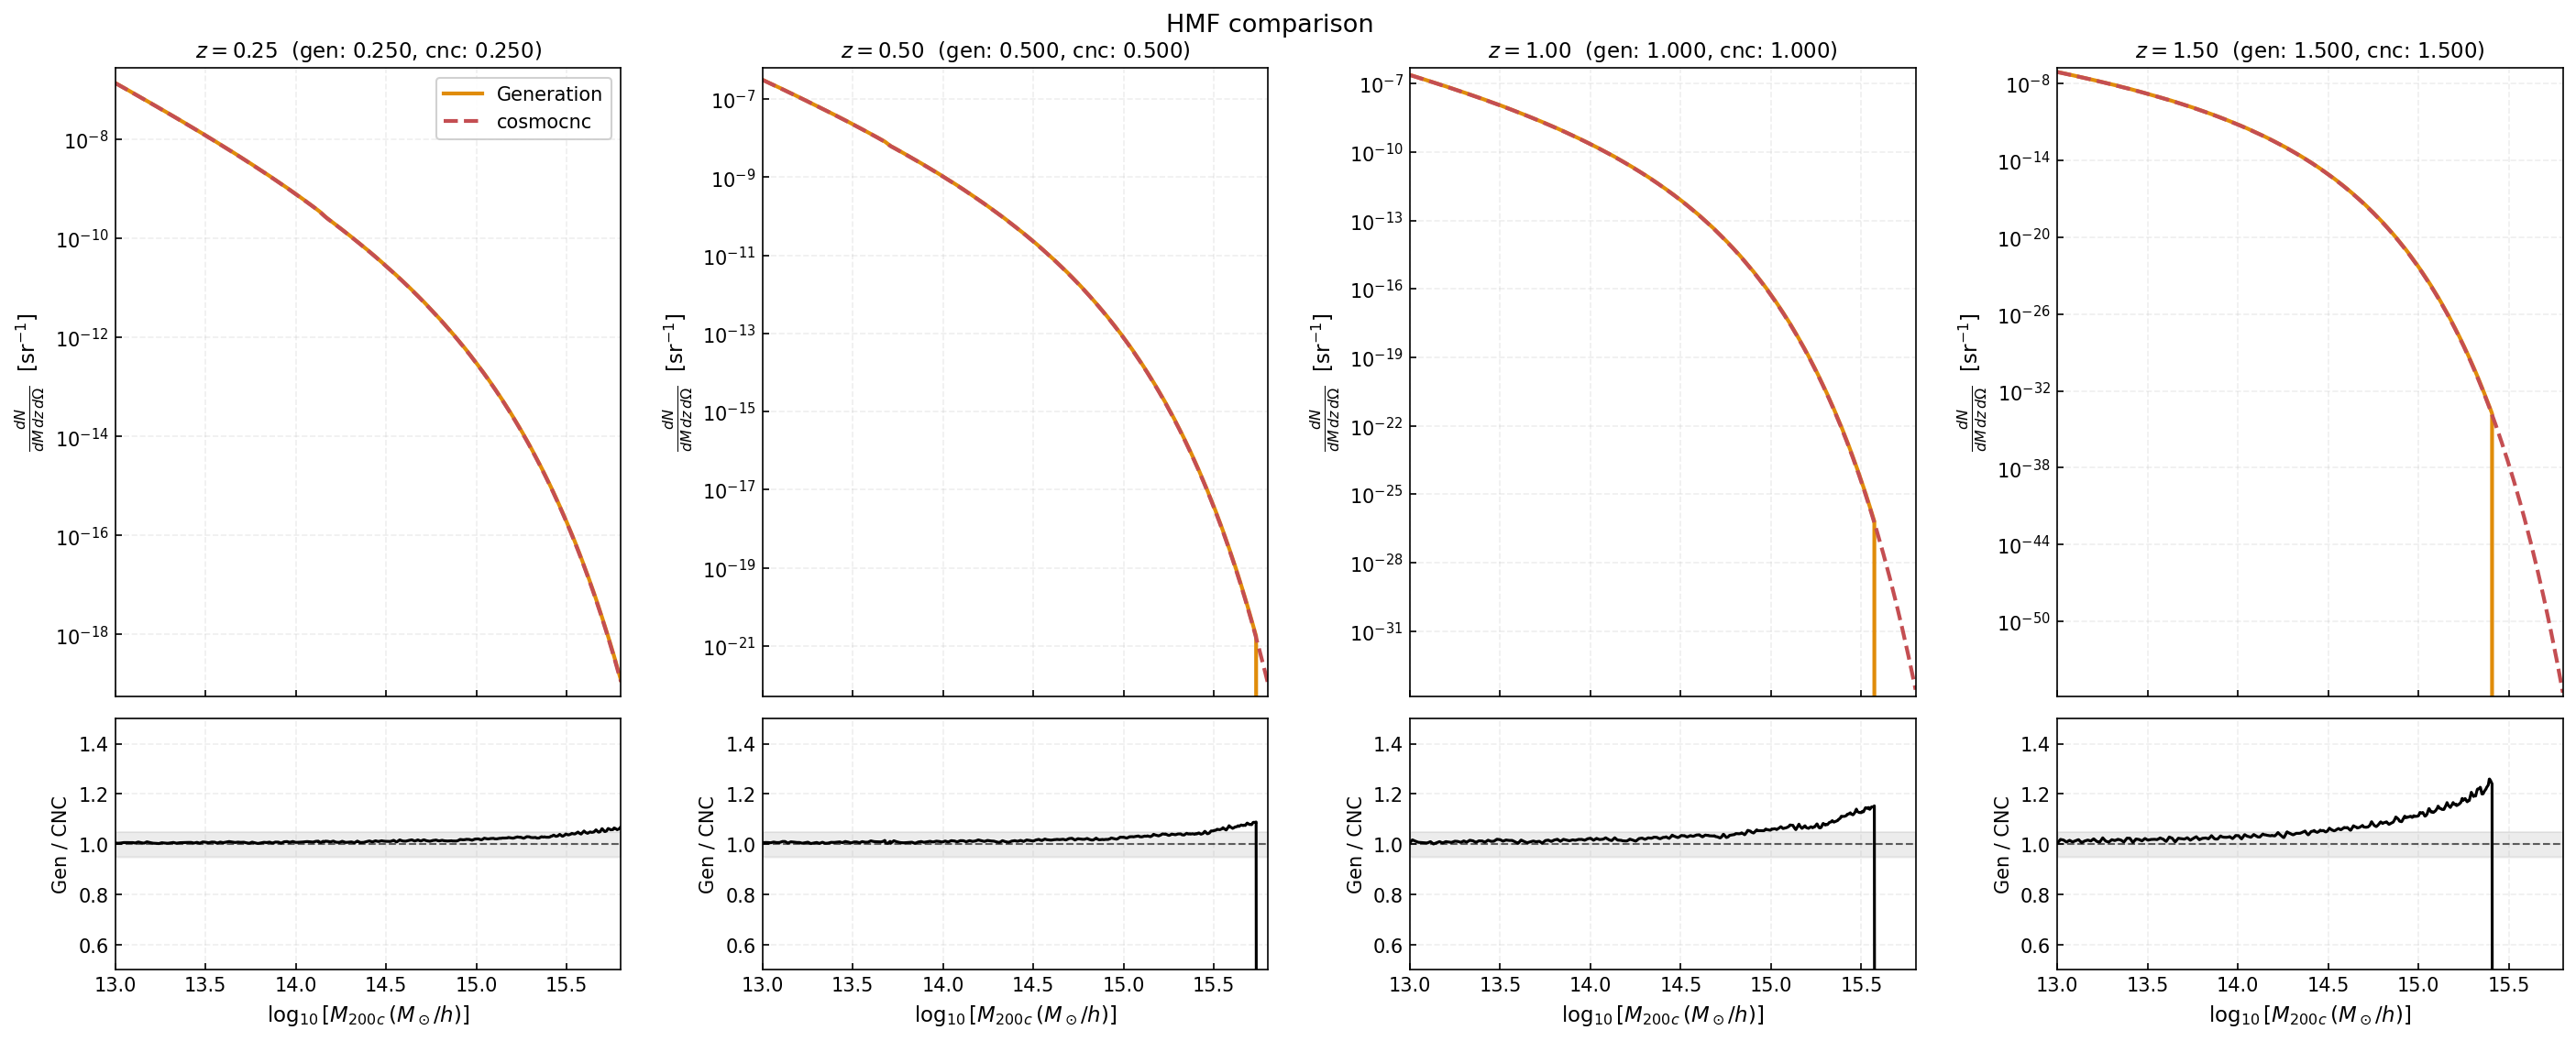

In [70]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import integrate

%matplotlib inline

# ── config ────────────────────────────────────────────────────────────────────
H_FID = 0.68
Z_PLOT = [0.25, 0.5, 1.0, 1.5]

HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
M_TRANSITION = 10**12.5


# Shared grid: fine, log-spaced, covering the full mass range both pipelines
# can supply. This grid is used for EVERYTHING below -- the plotted curves,
# the ratio, and the integrated N. No other grid is used anywhere.
LOG10_M_LO, LOG10_M_HI, N_SHARED = 13.0, 15.8, 2000
log10_M_SHARED = np.linspace(LOG10_M_LO, LOG10_M_HI, N_SHARED)
M_SHARED = 10**log10_M_SHARED
ln_M_SHARED = np.log(M_SHARED)

from feedback_mimic import (
    dn_dlog10Mtot, get_NFW_profile, get_realspace_profile,
    dV_dz, Mtot_to_MDelta, get_some_quantities,
)

K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1.0 / K_ARR.min()), 1500)

Z_ARR_FULL = np.linspace(0.0, 2.0, 81)
Z_ARR_FULL = Z_ARR_FULL[Z_ARR_FULL > 0]


def _log_interp(x_query, x_table, y_table_positive):
    """Interpolate a strictly-positive, steeply-varying function by
    interpolating ln(y) linearly in x, then exponentiating back.
    Returns 0 (not NaN) outside x_table's range, so downstream Simpson
    integrals over the shared grid don't need extra masking."""
    ln_y = np.log(np.maximum(y_table_positive, 1e-300))
    ln_y_interp = np.interp(x_query, x_table, ln_y, left=-np.inf, right=-np.inf)
    return np.exp(ln_y_interp)


# =============================================================================
# Generation: dn/(dlnM dz dOmega) on its own native grid, fully explicit
# =============================================================================

def generation_hmf_native(z_request):
    iz_pick = np.argmin(np.abs(Z_ARR_FULL - z_request))
    z_file = float(Z_ARR_FULL[iz_pick])

    with open(f"{HALO_INPUT_FILE}/{z_file}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data = pickle.load(f)

    Mtot = data['M']           # Msol/h
    hmf_vir = data['hmf']      # dn/dM_vir directly (= (1/M)dn/dlnM), units h^4/(Msol*Mpc^3)

    r_t, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = \
        get_some_quantities(data)

    valid = Mtot > M_TRANSITION
    Mtot_v = Mtot[valid]
    hmf_v  = hmf_vir[valid]
    r_t_v  = r_t[valid]
    r_s_v  = r_s[valid]

    rho_v = get_realspace_profile(
        u_k=get_NFW_profile(r_v=r_t_v, k_arr=K_ARR, r_s=r_s_v, r_t=r_t_v),
        r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot_v, r_t=r_t_v)
    M200c, _ = Mtot_to_MDelta(
        data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
        Del=200, reference_density="critical",
        axion_dic=None, rho=rho_v, k_arr=K_ARR)

    order = np.argsort(M200c)
    M200c_s  = M200c[order]
    Mtot_v_s = Mtot_v[order]
    hmf_v_s  = hmf_v[order]    # dn/dM_vir, h^4/(Msol*Mpc^3), M_vir in Msol/h

    jac = np.gradient(Mtot_v_s) / np.gradient(M200c_s)   # dM_vir/dM_200c (both Msol/h)
    hmf_dM200c = hmf_v_s * jac          # dn/dM_200c, h^4/(Msol*Mpc^3), M_200c in Msol/h

    hmf_dM200c *= dV_dz(data, z=z_request)/(4. * np.pi)

    return z_file, M200c_s, hmf_dM200c

def cosmocnc_hmf_native(z_request, nc=nc):
    ln_M_nc = np.asarray(nc.ln_M)
    redshift_vec_nc = np.asarray(nc.redshift_vec)
    M500_full = np.tile(np.exp(ln_M_nc) * 1e14, (len(redshift_vec_nc), 1))    # (n_z, n_M) - physical Msol m500c
    hmf_matrix_nc   = np.asarray(nc.hmf_matrix).copy() # <- this is dn/dlnM500c in physical units
    hmf_matrix_nc   /=  M500_full # dn/dM500c in physical units

    from cosmocnc_axionHMcode_jax.cosmocnc_jax.mass_conversion import _nfw_m, _nfw_m_prime
    def nfw_m500c_conversions(c500c, n_iter=15):
        """Given c500c, returns (M200c/M500c, c200c) from the same Newton solve."""
        m_c500 = _nfw_m(c500c)
        def step(_, y):
            cy = c500c * y
            mc = _nfw_m(cy)
            F  = 2.5 * y**(-3) - m_c500 / mc
            Fp = -7.5 * y**(-4) + (m_c500 * c500c * _nfw_m_prime(cy)) / (mc**2)
            return y - F / Fp
        y0 = np.full_like(c500c, 1.5)
        y = y0
        for i in range(n_iter):
            y = step(i, y)
        M200_over_M500 = (y**3) / 2.5
        c200c = c500c * y
        return M200_over_M500, c200c
    
    M200_over_M500 = nfw_m500c_conversions(nc.profile_params['concentration_500c'])[0]
    M200_full = M200_over_M500 * M500_full   # M200c, physical Msol, per z and M
    dM500_dM200 = np.gradient((M500_full), axis=1)/np.gradient((M200_full), axis=1)
    hmf_matrix_nc *= dM500_dM200 # now dn/dM200c - in physical units
    
    iz_nc = np.argmin(np.abs(redshift_vec_nc - z_request))
    z_nc_actual = float(redshift_vec_nc[iz_nc])

    M200c_row = M200_full[iz_nc]*H_FID
    hmf_row_persr  = hmf_matrix_nc[iz_nc]/H_FID# / H_FID**4

    return z_nc_actual, M200c_row, hmf_row_persr

# =============================================================================
# Put BOTH curves on the ONE shared grid -- log-space interpolation
# =============================================================================

def build_shared_grid_curves(z_request):
    z_gen, M_gen, hmf_gen = generation_hmf_native(z_request)
    z_nc,  M_nc,  hmf_nc  = cosmocnc_hmf_native(z_request)

    hmf_gen_shared = _log_interp(log10_M_SHARED, np.log10(M_gen), hmf_gen)
    hmf_nc_shared  = _log_interp(log10_M_SHARED, np.log10(M_nc),  hmf_nc)

    return z_gen, z_nc, hmf_gen_shared, hmf_nc_shared


# =============================================================================
# Build everything from the shared grid, print + plot consistently
# =============================================================================

print("Computing curves on shared grid...")
results = {}
for z in Z_PLOT:
    z_gen, z_nc, hmf_gen_sh, hmf_nc_sh = build_shared_grid_curves(z)
    results[z] = dict(z_gen=z_gen, z_nc=z_nc, hmf_gen=hmf_gen_sh, hmf_nc=hmf_nc_sh)

    # Ratio computed on the SAME shared grid as everything else
    ratio = np.where(hmf_nc_sh > 0, hmf_gen_sh / hmf_nc_sh, np.nan)
    results[z]['ratio'] = ratio
    
    ratio_at_ref = np.interp(14.5, log10_M_SHARED, ratio)
    print(f"z={z:.2f} (gen z={z_gen:.3f}, cnc z={z_nc:.3f}):")
    print(f"  ratio at log10(M)=14.5         : {ratio_at_ref:.4f}")

# ── PLOT ──────────────────────────────────────────────────────────────────────

n_z = len(Z_PLOT)
fig = plt.figure(figsize=(5*n_z, 8), dpi=150)
gs  = gridspec.GridSpec(2, n_z, figure=fig,
                        height_ratios=[1, 0.4], hspace=0.05,
                        left=0.08, right=0.97, bottom=0.10, top=0.92,
                        wspace=0.28)

C_GEN = "#E08C0A"
C_CNC = "#C44E52"

for col, z in enumerate(Z_PLOT):
    r = results[z]
    ax_top = fig.add_subplot(gs[0, col])
    ax_bot = fig.add_subplot(gs[1, col])

    ax_top.plot(log10_M_SHARED, r['hmf_gen'], color=C_GEN, lw=2.0, label='Generation')
    ax_top.plot(log10_M_SHARED, r['hmf_nc'],  color=C_CNC, lw=2.0, ls='--', label='cosmocnc')
    ax_top.set_yscale('log')
    ax_top.set_title(f"$z={z:.2f}$  (gen: {r['z_gen']:.3f}, cnc: {r['z_nc']:.3f})", fontsize=11)
    ax_top.tick_params(labelbottom=False, which='both', direction='in')
    ax_top.grid(alpha=0.2, linestyle='--')
    ax_top.set_ylabel(r'$\frac{dN}{dM\, dz\, d\Omega}$  [sr$^{-1}$]', fontsize=11)
    if col == 0:
        ax_top.legend(fontsize=10, framealpha=0.9)
    valid = r['hmf_nc'] > 0
    if valid.sum() > 0:
        ax_top.set_ylim(r['hmf_nc'][valid].min() * 0.5, r['hmf_nc'][valid].max() * 2.)

    ax_bot.axhline(1.0, color='k', lw=1.0, ls='--', alpha=0.6)
    ax_bot.fill_between(log10_M_SHARED, 0.95, 1.05, color='gray', alpha=0.15)
    ax_bot.plot(log10_M_SHARED, r['ratio'], color='k', lw=1.5)
    ax_bot.set_ylim(0.5, max(1.5, np.nanmax(r['ratio'][valid]) * 1.1 if valid.sum() else 4.0))
    ax_bot.set_ylabel('Gen / CNC', fontsize=10)
    ax_bot.set_xlabel(r'$\log_{10}[M_{200c}\,(M_\odot/h)]$', fontsize=11)
    ax_bot.tick_params(which='both', direction='in')
    ax_bot.grid(alpha=0.2, linestyle='--')

for col in range(n_z):
    fig.axes[2*col].set_xlim(LOG10_M_LO, LOG10_M_HI)
    fig.axes[2*col+1].set_xlim(LOG10_M_LO, LOG10_M_HI)

fig.suptitle(r'HMF comparison', fontsize=13, y=0.97)
plt.show()

##### MCMC

In [1]:
import pickle
import numpy as np
from scipy.optimize import minimize, brentq, least_squares

import os
from cosmocnc_axionHMcode_jax.cosmocnc_jax.mass_conversion import _nfw_m, _nfw_m_prime

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /home/user/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/


/home/user/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/hmf.py:17: UserWarning: Explicitly requested dtype float64 requested in array is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  TINKER08_DELTA_LOG = jnp.log10(jnp.array([200.,300.,400.,600.,800.,1200.,1600.,2400.,3200.], dtype=jnp.float64))
/home/user/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/hmf.py:18: UserWarning: Explicitly requested dtype float64 requested in array is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  TINKER08_DELTA_LIN = jnp.array([200.,300.,400.,600.,800.,1200.,1600.,2400.,3200.], dtype=jnp.float64)
/home/user/FeedbackMimic/cosm

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /home/user/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/


red star minuslogpost 355892.07 at omega_m=0.14249006, A_s=2.1270667e-09, A_sz=-4.3541084
red star minuslogpost 355894.63 at omega_m=0.13843347, A_s=2.2665033e-09, A_sz=-4.3474928
red star minuslogpost 355892.44 at omega_m=0.14343534, A_s=2.1016415e-09, A_sz=-4.3553198
red star minuslogpost 355893.24 at omega_m=0.14426211, A_s=2.0979015e-09, A_sz=-4.3635366
red star minuslogpost 355893.06 at omega_m=0.14923031, A_s=1.9231658e-09, A_sz=-4.3512456
red star minuslogpost 355892.93 at omega_m=0.14170778, A_s=2.1563953e-09, A_sz=-4.3534559
red star minuslogpost 355892.4 at omega_m=0.14351116, A_s=2.0941222e-09, A_sz=-4.3555018
red star minuslogpost 355892.16 at omega_m=0.14434881, A_s=2.0847282e-09, A_sz=-4.3626844
red star minuslogpost 355892.93 at omega_m=0.14489965, A_s=2.0687216e-09, A_sz=-4.3657891
red star minuslogpost 355893.21 at omega_m=0.14191265, A_s=2.1392791e-09, A_sz=-4.3496525
red star minuslogpost 355893.97 at omega_m=0.13991691, A_s=2.2335191e-09, A_sz=-4.3566224
red star mi

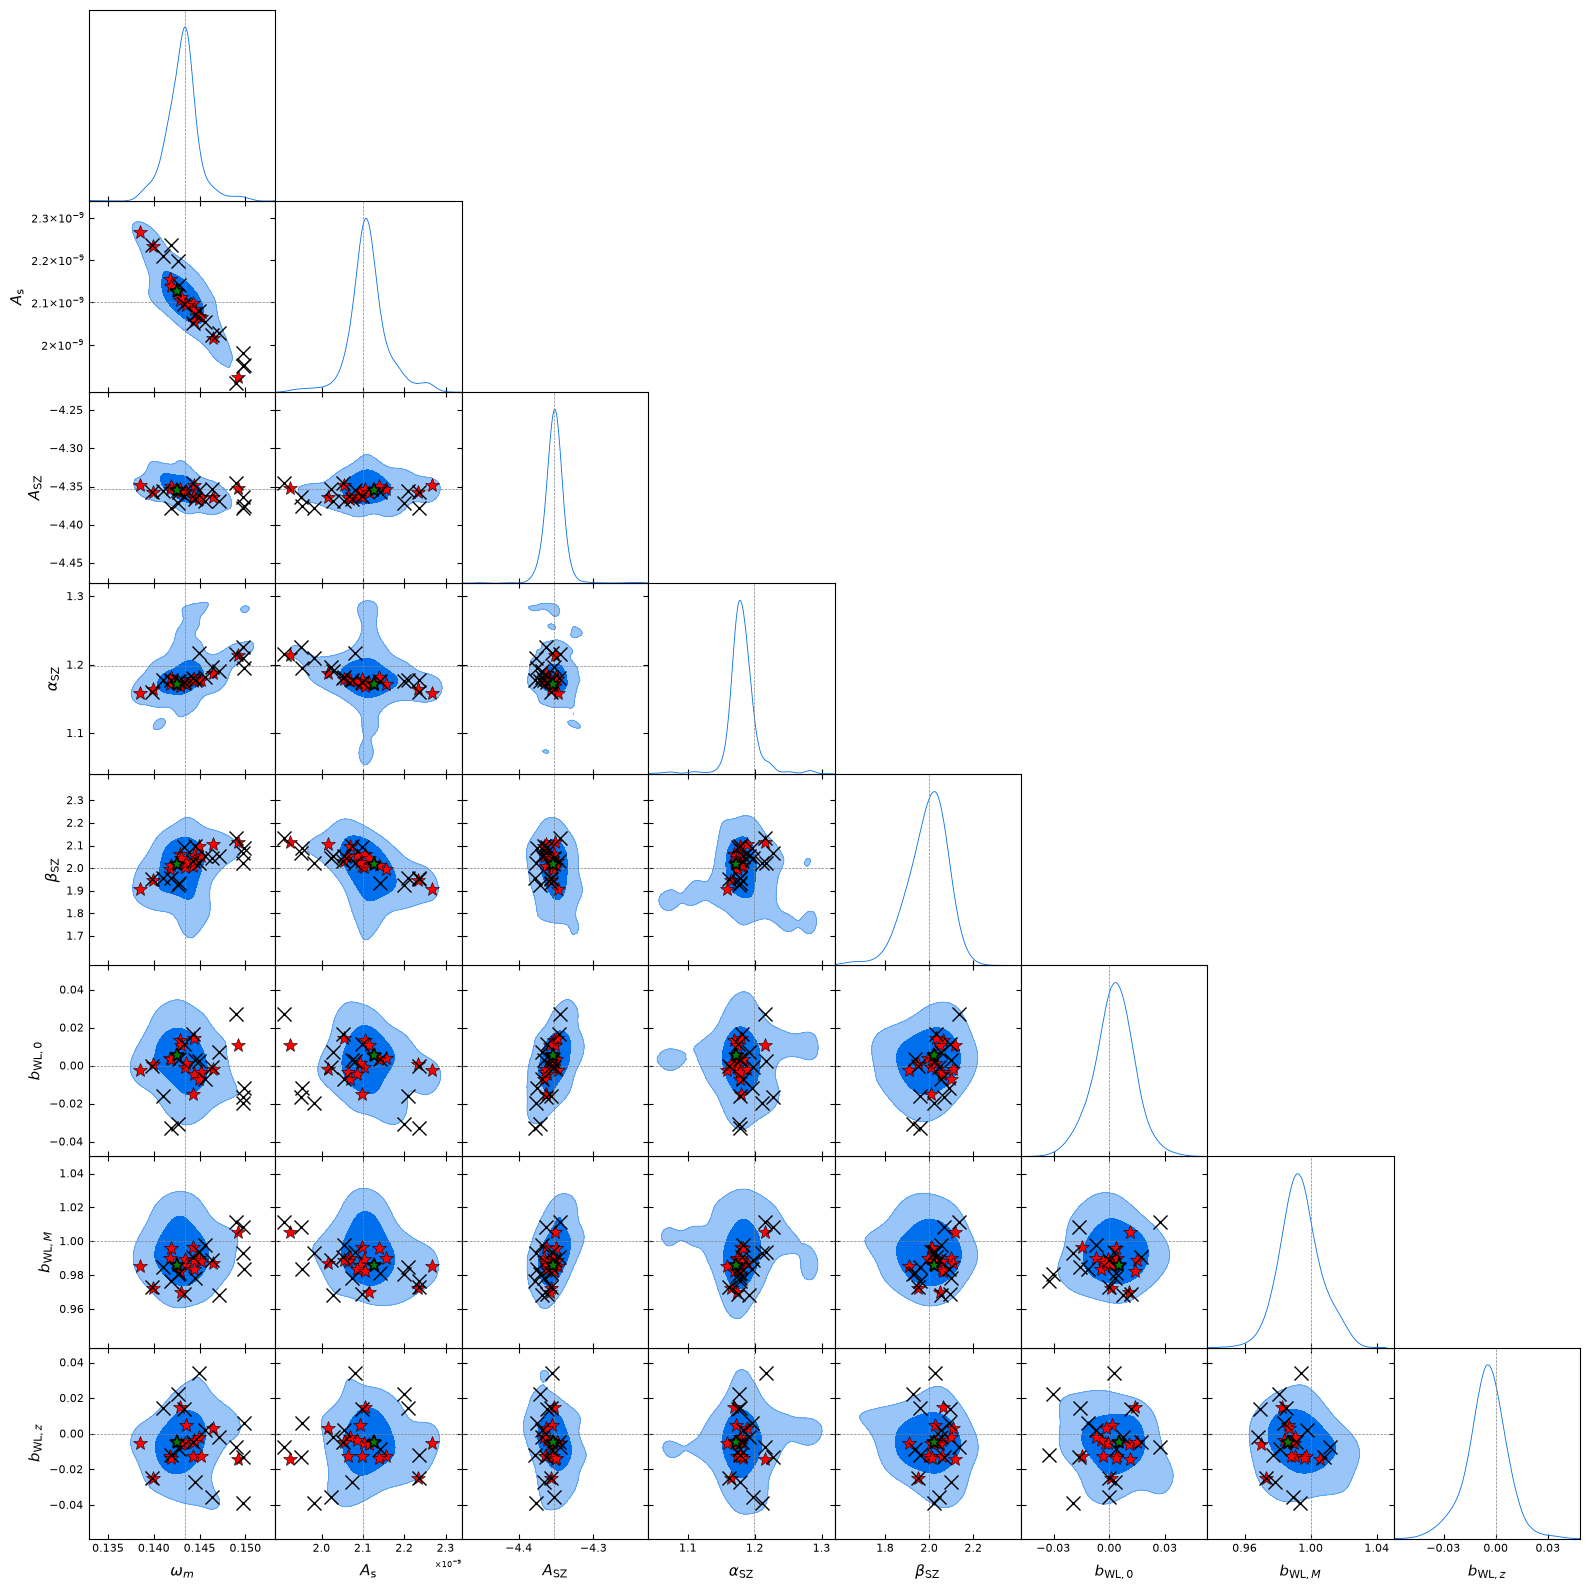

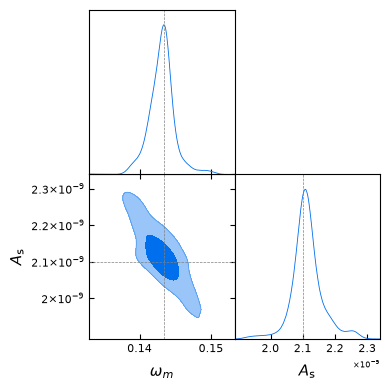

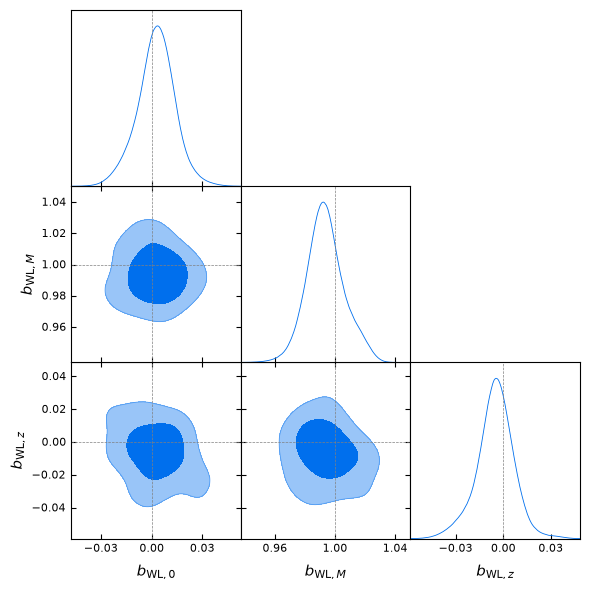

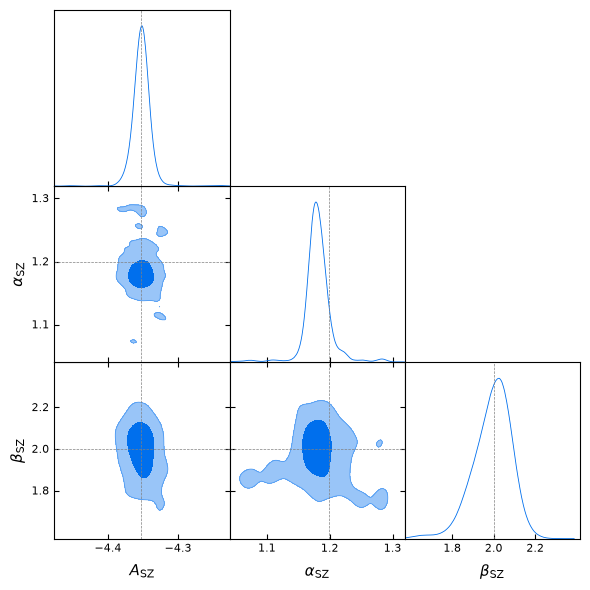

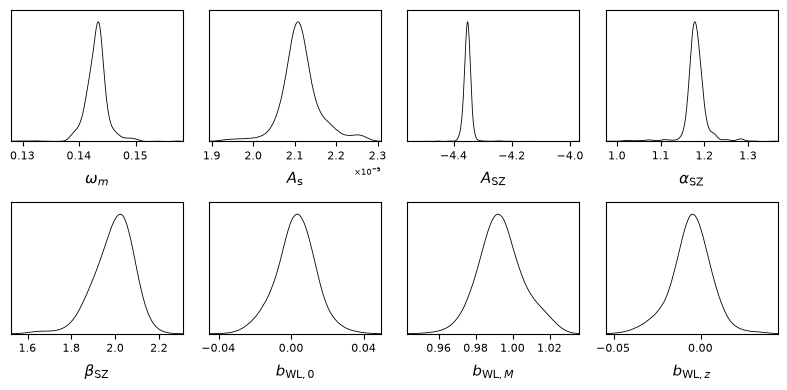

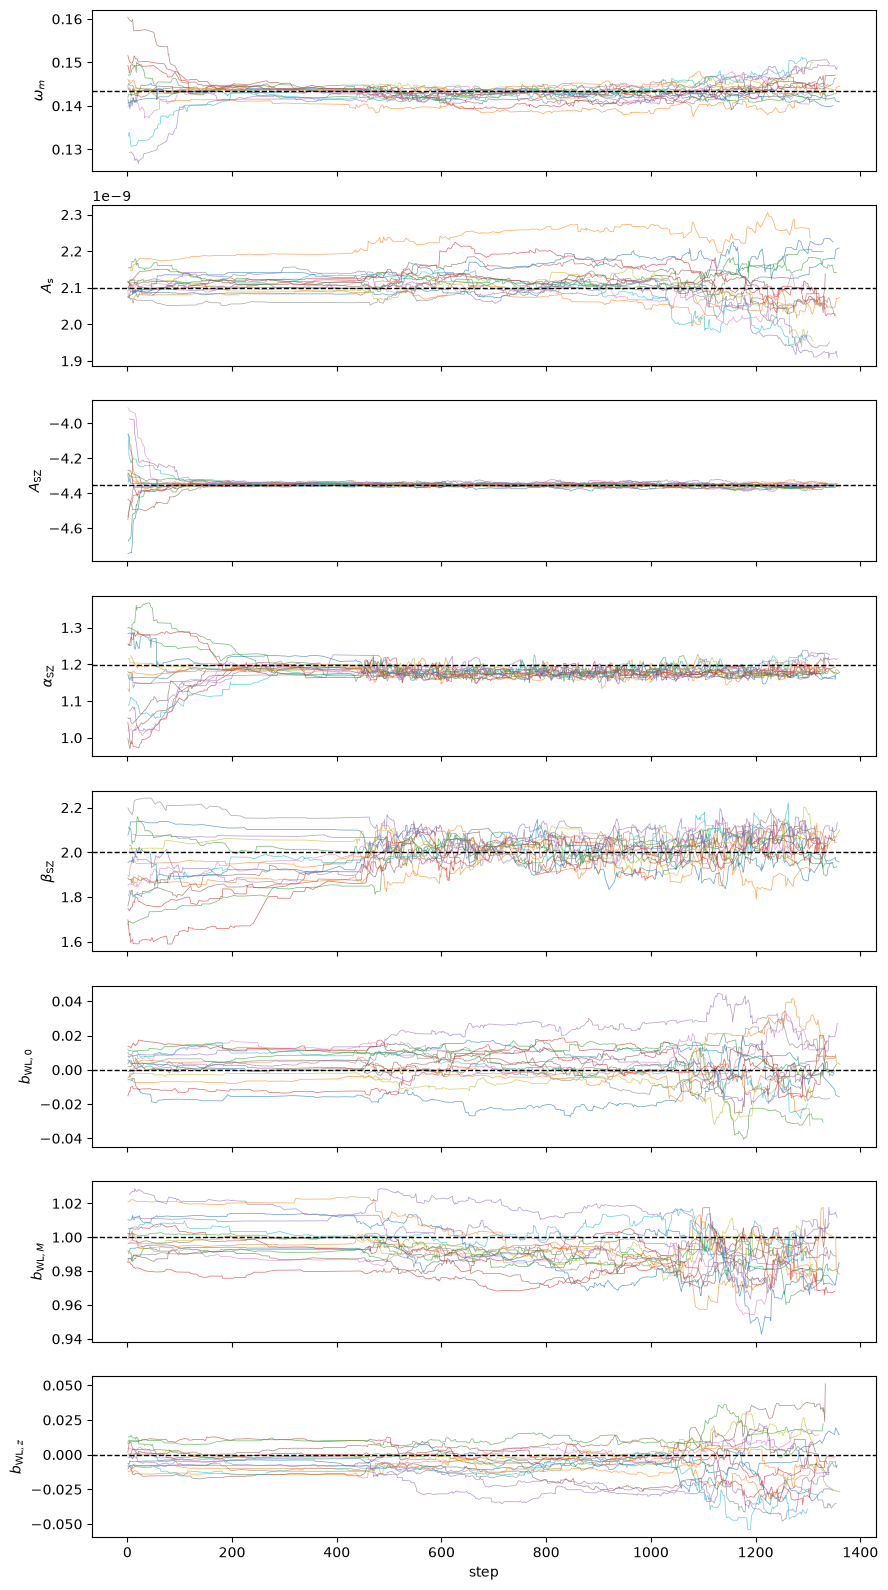

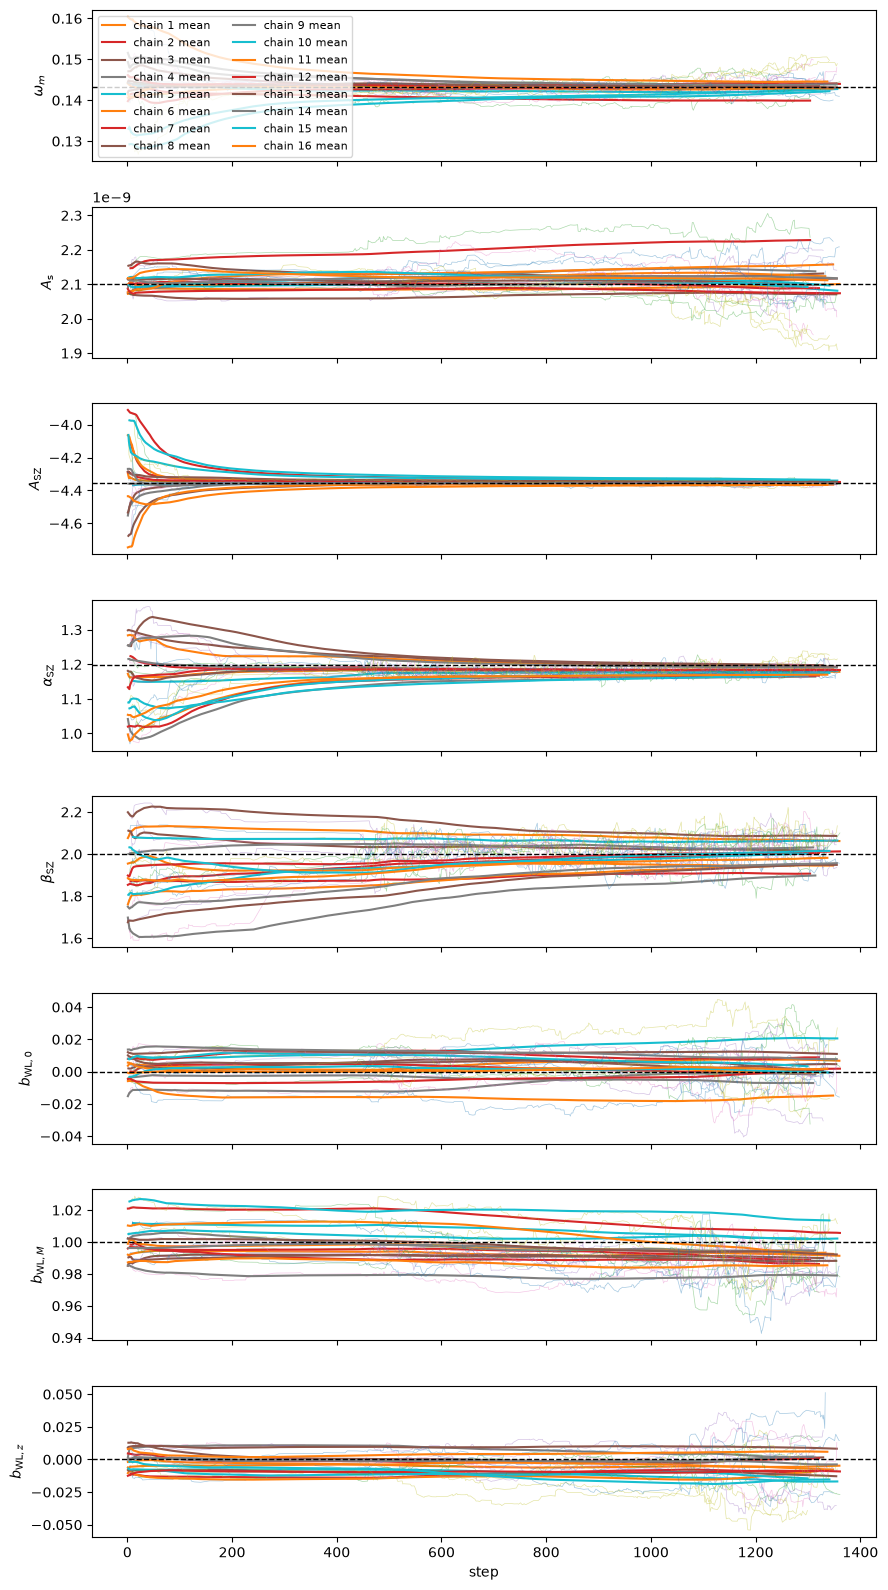

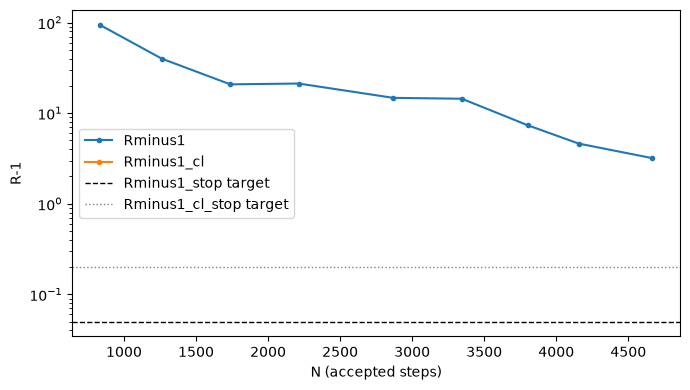

In [79]:
# pip install getdist   (if not already installed)
from getdist import MCSamples

import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
from getdist import loadMCSamples, plots
# ── config, matches run_mcmc.py ──────────────────────────────────────────
mock_obs_type = "LCDM_DES_mock_seed50" 
OUTPUT_DIR = "/home/user/FeedbackMimic/results/"
catalogues = {
    "LCDM_DES_mock_seed50"                        : f"{OUTPUT_DIR}mock_catalogs/LCDM_DES_mock_seed50.pkl",
}
fiducials = {
    "LCDM_DES_mock_seed50"                        : (0.143344, 2.1e-09, -4.352890598769685, 1.1991734303623067, 1.9996943667059135, 0.0, 0.0, 1.0),
}
output_names = {
    "LCDM_DES_mock_seed50"                        : f"{OUTPUT_DIR}mcmc/LCDM_DES_50_cobaya",
}

# ─────────────────────────────────────────────────────────────────────────

catalogue_name = catalogues[mock_obs_type]
output_name = output_names[mock_obs_type]
(omega_m_fid, A_s_fid, A_sz_fid, alpha_sz_fid, beta_sz_fid, b_WL0_fid, b_WLz_fid, b_WLM_fid) = fiducials[mock_obs_type]
params = ["omega_m", "A_s", "A_sz", "alpha_sz", "beta_sz", "b_WL_0", "b_WL_M", "b_WL_z"]
labels = {
    "omega_m": r"\omega_m", "A_s": r"A_\mathrm{s}", "A_sz": r"A_\mathrm{SZ}",
    "alpha_sz": r"\alpha_\mathrm{SZ}", "beta_sz": r"\beta_\mathrm{SZ}",
    "b_WL_0": r"b_{\mathrm{WL},0}", "b_WL_M": r"b_{\mathrm{WL},M}", "b_WL_z": r"b_{\mathrm{WL},z}",
}
truths = {"omega_m": omega_m_fid, "A_s": A_s_fid, "A_sz": A_sz_fid,
          "alpha_sz": alpha_sz_fid, "beta_sz": beta_sz_fid, 
          "b_WL_0": b_WL0_fid, "b_WL_M": b_WLM_fid, "b_WL_z": b_WLz_fid}
samples = loadMCSamples(output_name, settings={'ignore_rows': 0.0})
chain_files = sorted(glob.glob(output_name + ".*.txt"))
chain_files = [f for f in chain_files if f.split('.')[-2].isdigit()]  # skip non-chain files
def read_chain(fname):
    with open(fname) as f:
        header = f.readline().lstrip('#').split()
    return pd.read_csv(fname, sep=r'\s+', comment='#', names=header)

# ── 1. triangle / corner plot — the main result ──────────────────────────
stats = samples.getMargeStats()
param_limits = {}
for p in params:
    par = stats.parWithName(p)
    lo = par.mean - 4.5 * par.err
    hi = par.mean + 4.5 * par.err
    # Make sure the fiducial is visible
    lo = min(lo, truths[p])
    hi = max(hi, truths[p])
    param_limits[p] = [lo, hi]

g = plots.get_subplot_plotter()
g.triangle_plot(
    [samples],
    params,
    filled=True,
    markers=truths,
    param_limits=param_limits,
)

########################## high likelihood contour
'''
dfs = [read_chain(cf) for cf in chain_files]
df_all = pd.concat(dfs, ignore_index=True)
mask = df_all["minuslogpost"] < 1207422
filtered = df_all.loc[mask]
print(f"{mask.sum()} / {len(mask)} samples survive")
samples_cut = MCSamples(
    samples=filtered[params].values,
    weights=filtered["weight"].values,
    names=params,
    labels=[labels[p] for p in params],
)
g.triangle_plot(
    [samples, samples_cut],
    params,
    filled=True,
    markers=truths,
    param_limits=param_limits,
    colors = ['C0','red'], contour_colors=['C0', 'red'],
)
'''
########################## points
chain_best = []
chain_last = []
for cf in chain_files:
    df = read_chain(cf)
    # Cobaya usually stores minuslogpost
    if "minuslogpost" in df.columns:
        best = df.loc[df["minuslogpost"].idxmin()]
    else:
        raise RuntimeError("Couldn't find posterior columns.")
    last = df.iloc[-1]
    chain_best.append(best)
    chain_last.append(last)

    best_index = df["minuslogpost"].idxmin()
    print(f"red star minuslogpost {df["minuslogpost"][best_index]} at omega_m={df["omega_m"][best_index]}, A_s={df["A_s"][best_index]}, A_sz={df["A_sz"][best_index]}")
global_best = min(
    chain_best,
    key=lambda r: r["minuslogpost"]
)
n = len(params)
for i in range(n):
    for j in range(i):

        ax = g.subplots[i, j]

        xpar = params[j]
        ypar = params[i]
        
        # Highest-likelihood point from each chain (triangle)
        for k, row in enumerate(chain_best):
            ax.plot(
                row[xpar], row[ypar],
                marker='*',
                color=f"red",
                markersize=10,
                markeredgecolor='k',
                markeredgewidth=0.4,
                linestyle='None',
                zorder=20,
            )

        # Most recent point from each chain (star)
        for k, row in enumerate(chain_last):
            ax.plot(
                row[xpar], row[ypar],
                marker='x',
                color=f"black",
                markersize=10,
                markeredgecolor='k',
                markeredgewidth=1.,
                linestyle='None',
                zorder=21,
            )
        ax.plot(
            global_best[xpar], global_best[ypar],
            marker='*',
            color='green',
            markersize=10,
            markeredgecolor='black',
            markeredgewidth=1.2,
            linestyle='None',
            zorder=100,
        )
print(f"Global smallest minuslogpost = {global_best['minuslogpost']}")
##########################


g.export("results/triangle_full.png")

g.triangle_plot(samples, ["omega_m", "A_s"], filled=True, markers=truths,
    param_limits=param_limits)
g.export("results/triangle_cosmo.png")
g.triangle_plot(samples, ["b_WL_0", "b_WL_M", "b_WL_z"], filled=True, markers=truths,
    param_limits=param_limits)
g.export("results/triangle_bWL.png")
g.triangle_plot(samples, ["A_sz", "alpha_sz", "beta_sz"], filled=True, markers=truths,
    param_limits=param_limits)
g.export("results/triangle_SZ.png")

# ── 2. 1D marginalized posteriors, all params in one figure ──────────────
g2 = plots.get_subplot_plotter()
g2.plots_1d(samples, params, nx=4)
g2.export("results/posteriors_1d.png")

# ── 3. numeric summary (mean, error, vs. truth) ──────────────────────────
stats = samples.getMargeStats()
for p in params:
    par = stats.parWithName(p)
    print(f"{p:>10s} = {par.mean:.5g} +/- {par.err:.3g}   (truth: {truths[p]:.5g})")

# ── 4. raw trace plots — mixing/burn-in check, one panel per param,
# all 8 chains overlaid, UNTRIMMED (this is where you actually judge burn-in) ──
fig, axes = plt.subplots(len(params), 1, figsize=(9, 2*len(params)), sharex=True)
for cf in chain_files:
    df = read_chain(cf)
    step = np.cumsum(df['weight'].values)   # true step number, accounting for MH repeats
    for ax, p in zip(axes, params):
        ax.plot(step, df[p].values, lw=0.5, alpha=0.7)
for ax, p in zip(axes, params):
    ax.set_ylabel(f"${labels[p]}$")
    ax.axhline(truths[p], color='k', ls='--', lw=1)
axes[-1].set_xlabel("step")
fig.tight_layout()
fig.savefig("results/traces.png", dpi=110)

# ── 5. raw trace plots + running mean per chain ───────────────────────────
fig, axes = plt.subplots(len(params), 1, figsize=(9, 2*len(params)), sharex=True)

for k, cf in enumerate(chain_files):
    df = read_chain(cf)

    # true step number accounting for MH repeats
    step = np.cumsum(df['weight'].values)

    for ax, p in zip(axes, params):
        # raw chain
        ax.plot(
            step, df[p].values,
            lw=0.5,
            alpha=0.4,
        )

        # weighted running mean
        weighted_sum = np.cumsum(df[p].values * df['weight'].values)
        running_weight = np.cumsum(df['weight'].values)
        running_mean = weighted_sum / running_weight

        ax.plot(
            step,
            running_mean,
            lw=1.5,
            label=f"chain {k+1} mean" if p == params[0] else None,
        )


for ax, p in zip(axes, params):
    ax.set_ylabel(f"${labels[p]}$")
    ax.axhline(truths[p], color='k', ls='--', lw=1)

    ymin, ymax = ax.get_ylim()
    ycenter = 0.5 * (ymin + ymax)
    half_range = 0.5 * (ymax - ymin)   # half of the original half-range
    ax.set_ylim(ycenter - half_range, ycenter + half_range)

axes[0].legend(fontsize=8, ncol=2)
axes[-1].set_xlabel("step")

fig.tight_layout()
fig.savefig("results/traces_with_running_mean.png", dpi=110)

# ── 6. Gelman-Rubin R-1 convergence, from cobaya's own .progress file ────
prog_file = output_name + ".progress"
with open(prog_file) as f:
    header = f.readline().lstrip('#').split()
prog = pd.read_csv(prog_file, sep=r'\s+', comment='#', names=header)

r1_cols = [c for c in prog.columns if 'Rminus1' in c]
fig3, ax3 = plt.subplots(figsize=(7, 4))
for c in r1_cols:
    ax3.plot(prog['N'], prog[c], marker='o', ms=3, label=c)
ax3.axhline(0.05, color='k', ls='--', lw=1, label='Rminus1_stop target')
ax3.axhline(0.2, color='gray', ls=':', lw=1, label='Rminus1_cl_stop target')
ax3.set_yscale('log')
ax3.set_xlabel('N (accepted steps)'); ax3.set_ylabel('R-1')
ax3.legend()
fig3.tight_layout()
fig3.savefig("results/rminus1.png", dpi=110)

print("done: triangle_full.png, triangle_cosmo.png, triangle_bWL.png, "
      "posteriors_1d.png, traces.png, traces_with_running_mean.png, rminus1.png")

In [83]:
# how many accepted rows exist right now
import pandas as pd, glob
chain_files = sorted(glob.glob(f"{output_name}.*.txt"))
chain_files = [f for f in chain_files if f.split('.')[-2].isdigit()]
total_accepted = 0
for cf in chain_files:
    with open(cf) as f:
        header = f.readline().lstrip('#').split()
    df = pd.read_csv(cf, sep=r'\s+', comment='#', names=header)
    print(f"{cf}: {len(df)} accepted rows")
    total_accepted += len(df)
print(total_accepted)

/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.1.txt: 275 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.10.txt: 289 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.11.txt: 324 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.12.txt: 339 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.13.txt: 322 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.14.txt: 322 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.15.txt: 311 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.16.txt: 333 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.2.txt: 295 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.3.txt: 352 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.4.txt: 354 accepted rows
/home/user/FeedbackMimic/results/mcmc/LCDM_DES_50_cobaya.5.txt: 290 accepted rows
/home/use

In [77]:
from getdist import loadMCSamples

samples.removeBurnFraction(0.0)

print(samples.getNumSampleSummaryText())

using 4055 rows, 12 parameters; mean weight 4.716152897657214, tot weight 19124.0
Equiv number of single samples (sum w)/max(w): 193
Effective number of weighted samples (sum w)^2/sum(w^2): 1507



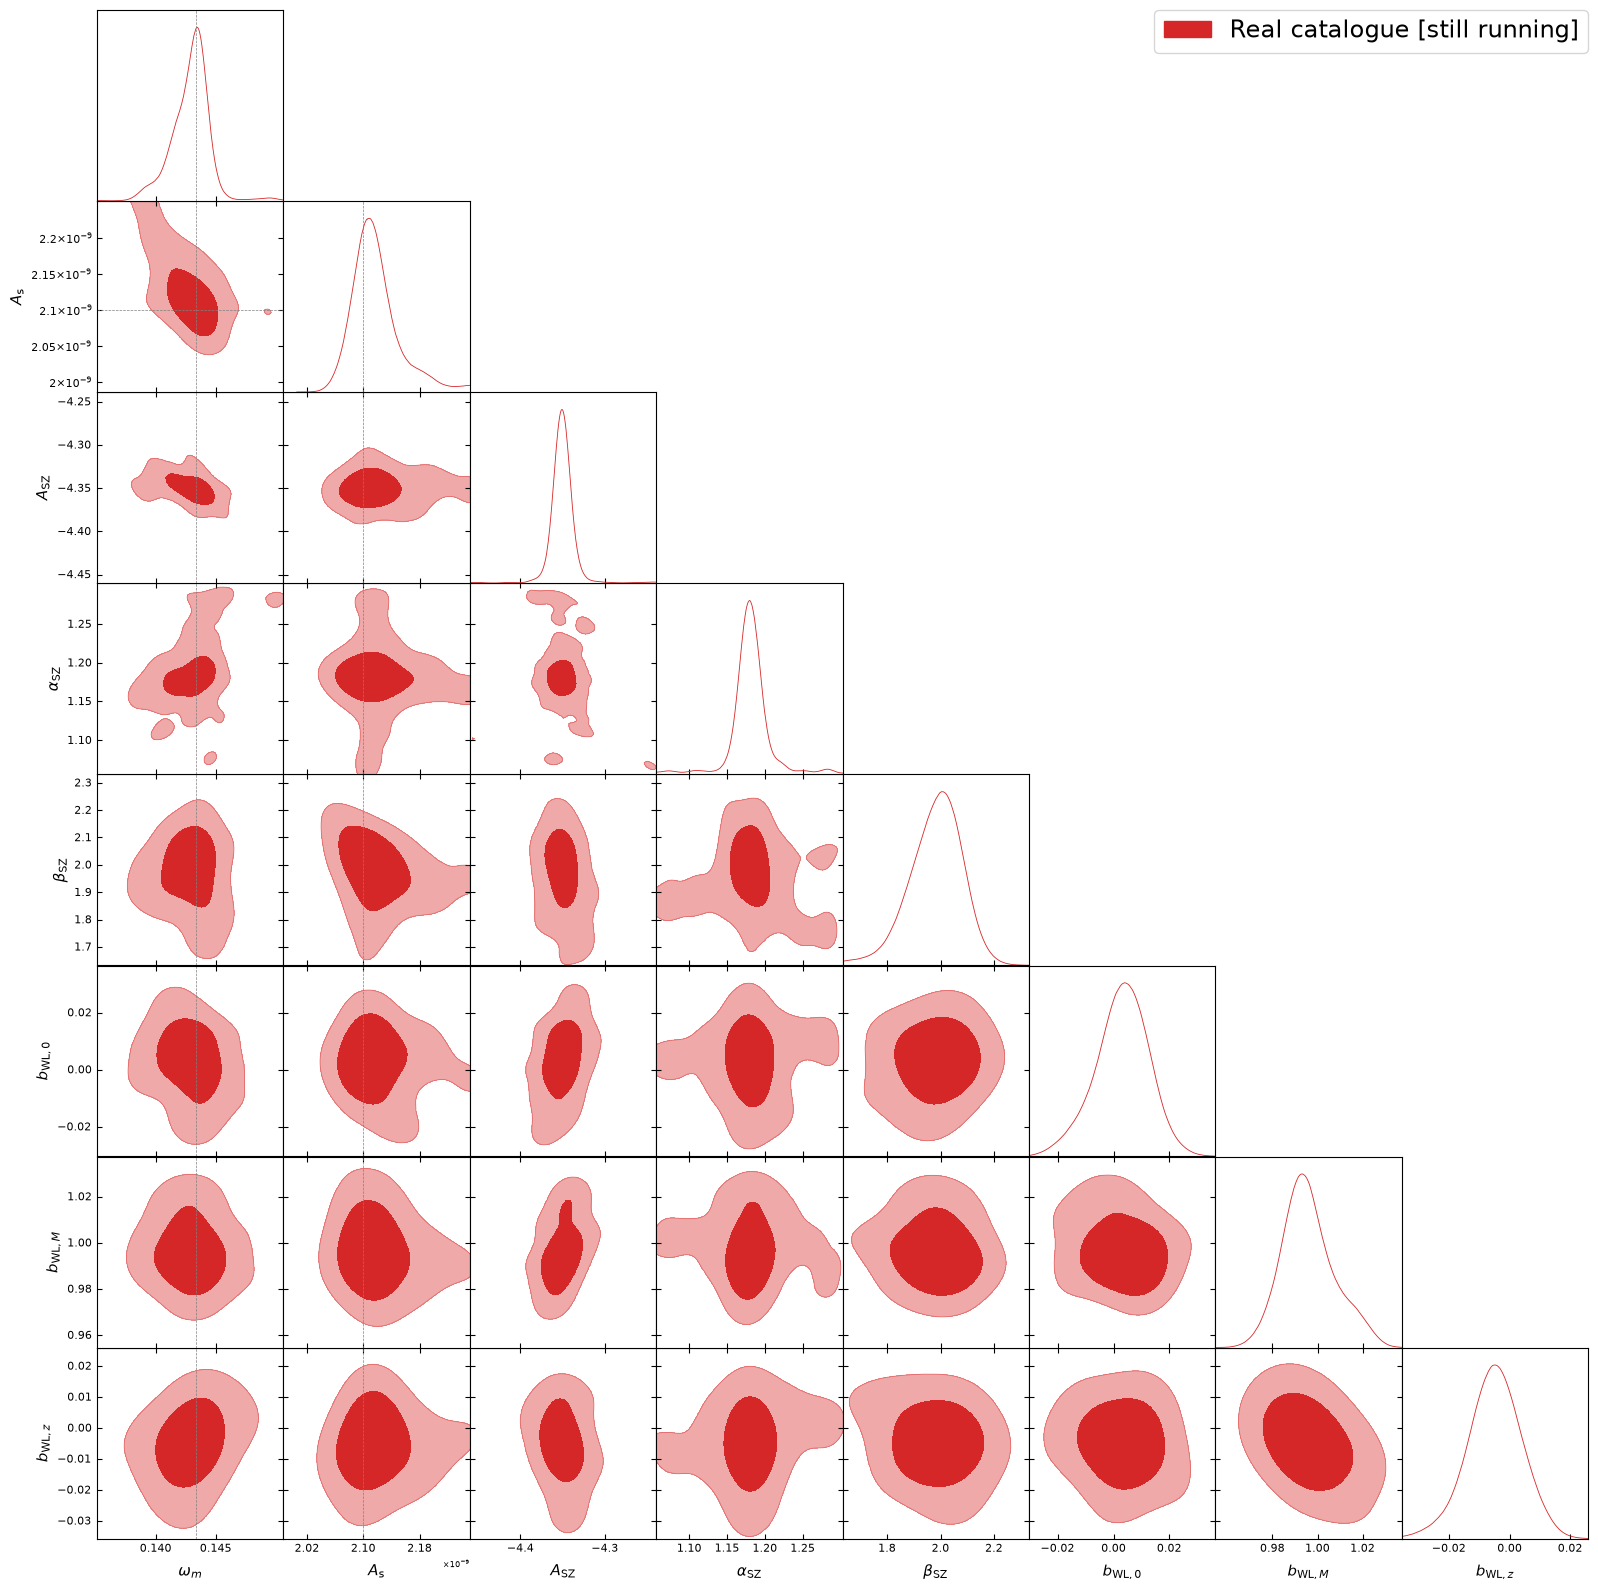

In [5]:
import numpy as np
from getdist import loadMCSamples, plots
# ------------------------------------------------------------------
# Runs to compare
# ------------------------------------------------------------------
runs = {
    "LCDM_DES_mock_seed50": {
        "path": output_names["LCDM_DES_mock_seed50"],
        "label": "Real catalogue [still running]",
        "color": "C3",
    },
}

# Load chains
samples_list = [
    loadMCSamples(run["path"], settings={"ignore_rows": 0.0})
    for run in runs.values()
]

run_labels = [
    run["label"]
    for run in runs.values()
]

run_colors = [
    run["color"]
    for run in runs.values()
]


# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
params = [
    "omega_m",
    "A_s",
    "A_sz",
    "alpha_sz",
    "beta_sz",
    "b_WL_0",
    "b_WL_M",
    "b_WL_z",
]

labels = {
    "omega_m": r"\omega_m",
    "A_s": r"A_\mathrm{s}",
    "A_sz": r"A_\mathrm{SZ}",
    "alpha_sz": r"\alpha_\mathrm{SZ}",
    "beta_sz": r"\beta_\mathrm{SZ}",
    "b_WL_0": r"b_{\mathrm{WL},0}",
    "b_WL_M": r"b_{\mathrm{WL},M}",
    "b_WL_z": r"b_{\mathrm{WL},z}",
}

# Only cosmology + SZ fiducials
truths = {
    "omega_m": 0.143344,
    "A_s": 2.1e-9,
}


# ------------------------------------------------------------------
# Plot limits using all chains
# ------------------------------------------------------------------
param_limits = {}

for p in params:

    vals = []

    for s in samples_list:
        par = s.getMargeStats().parWithName(p)
        vals.append((par.mean, par.err))

    lo = min(mean - 3.5 * err for mean, err in vals)
    hi = max(mean + 3.5 * err for mean, err in vals)

    # Include fiducials only where defined
    if p in truths:
        lo = min(lo, truths[p])
        hi = max(hi, truths[p])

    param_limits[p] = [lo, hi]


# ------------------------------------------------------------------
# Triangle plot
# ------------------------------------------------------------------
g = plots.get_subplot_plotter()

g.settings.alpha_filled_add = 0.5
g.settings.legend_fontsize = 20

g.triangle_plot(
    samples_list,
    params,
    filled=True,
    legend_labels=run_labels,
    legend_loc="upper right",
    contour_colors=run_colors,
    markers=truths,
    param_limits=param_limits,
)


#g.export("results/triangle_comparison.pdf")
g.export("results/triangle_comparison.png", dpi=300)

#### Misc below here

In [1]:
from getdist import loadMCSamples, plots
import numpy as np
import pickle

OUTPUT_DIR = "/home/jange/scratch/FeedbackMimic/results/"

params = ["omega_m", "A_s", "A_sz", "alpha_sz", "beta_sz", "b_WL_0", "b_WL_z", "b_WL_M"]

fiducial_values = np.asarray((0.143344, 2.1e-09, -4.353355099, 1.199496418, 2.000448160, 0.0, 0.0, 1.0))
peak_values = np.asarray([1.359035e-01, 2.342296e-09, -4.353091e+00, 1.170671e+00, 1.915366e+00, -2.399707e-03, 3.104662e-03, 9.830193e-01,])
n_scan = 15
t_values = np.linspace(-0.5, 1.5, n_scan)
parameter_vectors = (
    fiducial_values[None, :]
    + t_values[:, None]
    * (peak_values - fiducial_values)[None, :]
)
print(peak_values)
print(fiducial_values)

[ 1.359035e-01  2.342296e-09 -4.353091e+00  1.170671e+00  1.915366e+00
 -2.399707e-03  3.104662e-03  9.830193e-01]
[ 1.43344000e-01  2.10000000e-09 -4.35335510e+00  1.19949642e+00
  2.00044816e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]


In [2]:
lnL_dict = {}
with open("results/lnL_likelihood_scan.pkl", "rb") as f:
    lnL_dict = pickle.load(f)

In [3]:
lnL_dict.keys()

dict_keys(['LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42', 'LCDM_deepEuclid_42', 'LCDM_deepEuclid_42_ONLYQNOWL', 'LCDM_DES_42', 'LCDM_DES_43', 'LCDM_DES_44', 'LCDM_COSMOCNC_DES_42', 'LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42', 'LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL', 'LCDM_DES_42_ONLYQNOWL', 'LCDM_deepEuclid_44', 'LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42'])

In [4]:
from tqdm import tqdm
import os
import numpy as np
import pickle
########## note! be careful with the tomographic bin settings matching the catalogues ##########
os.environ["TOMOGRAPHIC_BINS"] = "DES"
from mcmc_likelihood import get_log_likelihood

catalogue_names_to_plot = ["LCDM_DES_44","LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42",]
                           #"LCDM_deepEuclid_44","LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42",]
                           #"LCDM_DES_42","LCDM_DES_43","LCDM_DES_44",
                           #"LCDM_COSMOCNC_DES_42",
                           #"LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42",]
                           #"LCDM_COSMOCNC_SR_Euclid_42-SR_best_fit_LCDM_DES_42",
                           #"LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42",
                           #"LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL",
                           #"LCDM_Euclid_42",]
                           #"LCDM_deepEuclid_42",]
                           #"LCDM_DES_42_ONLYQNOWL",]
                           #"LCDM_deepEuclid_42_ONLYQNOWL",]
catalogues = {
    "LCDM_DES_42"                        : f"{OUTPUT_DIR}mock_catalogs/LCDM_DES_mock_seed42.pkl",
    "LCDM_DES_43"                        : f"{OUTPUT_DIR}mock_catalogs/LCDM_DES_mock_seed43.pkl",
    "LCDM_DES_44"                        : f"{OUTPUT_DIR}mock_catalogs/LCDM_DES_mock_seed44.pkl",
    "LCDM_COSMOCNC_DES_42"               : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_DES_mock_seed42.pkl",
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42"
            : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_SR_DES-SR_best_fit_LCDM_DES_42_mock_seed42.pkl",
    "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42"
            : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_SR_DES-SR_best_fit_LCDM_DES_42_mock_seed44.pkl",
    "LCDM_COSMOCNC_SR_Euclid_42-SR_best_fit_LCDM_DES_42"
            : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_SR_Euclid-SR_best_fit_LCDM_DES_42_mock_seed42.pkl",
    "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42"
            : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_SR_deepEuclid-SR_best_fit_LCDM_DES_42_mock_seed42.pkl",
    "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42"
            : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_SR_deepEuclid-SR_best_fit_LCDM_DES_42_mock_seed44.pkl",
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL"
            : f"{OUTPUT_DIR}mock_catalogs/LCDM_COSMOCNC_SR_DES-SR_best_fit_LCDM_DES_42_mock_seed42.pkl",
    "LCDM_Euclid_42"         : f"{OUTPUT_DIR}mock_catalogs/LCDM_Euclid_mock_seed42.pkl",
    "LCDM_deepEuclid_42"     : f"{OUTPUT_DIR}mock_catalogs/LCDM_deepEuclid_mock_seed42.pkl",
    "LCDM_deepEuclid_44"     : f"{OUTPUT_DIR}mock_catalogs/LCDM_deepEuclid_mock_seed44.pkl",
    "LCDM_DES_42_ONLYQNOWL"  : f"{OUTPUT_DIR}mock_catalogs/LCDM_DES_mock_seed42.pkl",
    "LCDM_deepEuclid_42_ONLYQNOWL"  : f"{OUTPUT_DIR}mock_catalogs/LCDM_deepEuclid_mock_seed42.pkl",
}

for catalogue_name in catalogue_names_to_plot:
    if catalogue_name in lnL_dict.keys():
        print(f"{catalogue_name} already in the dict, so not recomputing")
        continue
    print(catalogue_name)
    try:
        lnL_values = []
        if catalogue_name in ["LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL",
                              "LCDM_DES_42_ONLYQNOWL", "LCDM_deepEuclid_42_ONLYQNOWL"]:
            for i, theta in tqdm(enumerate(parameter_vectors)):
                (OMEGA_M_VAL, A_S_VAL, A_SZ_VAL, ALPHA_SZ_VAL, BETA_SZ_VAL,B_WL_0_VAL,B_WL_Z_VAL,B_WL_M_VAL) = theta
                lnL_values.append(get_log_likelihood(
                    catalogue_name=catalogues[catalogue_name],
                    omega_m=OMEGA_M_VAL,
                    A_s=A_S_VAL,
                    A_sz=A_SZ_VAL,
                    alpha_sz=ALPHA_SZ_VAL,
                    beta_sz=BETA_SZ_VAL,
                    b_WL_0=B_WL_0_VAL,
                    b_WL_z=B_WL_Z_VAL,
                    b_WL_M=B_WL_M_VAL,
                    observables = [['q_so_sim']], 
                    n_points=16384,
                ))
        else:
            for i, theta in tqdm(enumerate(parameter_vectors)):
                (OMEGA_M_VAL, A_S_VAL, A_SZ_VAL, ALPHA_SZ_VAL, BETA_SZ_VAL,B_WL_0_VAL,B_WL_Z_VAL,B_WL_M_VAL) = theta
                lnL_values.append(get_log_likelihood(
                    catalogue_name=catalogues[catalogue_name],
                    omega_m=OMEGA_M_VAL,
                    A_s=A_S_VAL,
                    A_sz=A_SZ_VAL,
                    alpha_sz=ALPHA_SZ_VAL,
                    beta_sz=BETA_SZ_VAL,
                    b_WL_0=B_WL_0_VAL,
                    b_WL_z=B_WL_Z_VAL,
                    b_WL_M=B_WL_M_VAL, 
                    n_points=16384,
                ))
        lnL_dict[catalogue_name] = lnL_values
    except:
        print('there was a problem')

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/


/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/hmf.py:17: UserWarning: Explicitly requested dtype float64 requested in array is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  TINKER08_DELTA_LOG = jnp.log10(jnp.array([200.,300.,400.,600.,800.,1200.,1600.,2400.,3200.], dtype=jnp.float64))
/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/hmf.py:18: UserWarning: Explicitly requested dtype float64 requested in array is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  TINKER08_DELTA_LIN = jnp.array([200.,300.,400.,600.,800.,1200.,1600.,2400.,3200.], dtype=jnp.float64)
/scra

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/cosmocnc_axionHMcode_jax/cosmocnc_jax/
cache_suffix = 
Loaded precomputed tables from cache
Shear cache already made
LCDM_DES_44 already in the dict, so not recomputing
LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42


0it [00:00, ?it/s]

PATH_TO_CLASS_SZ_DATA not set. Setting it now...
Defaulting to: /home/jange/class_sz_data_directory


2026-07-29 22:43:58.965085: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/cnc.py:808: DeprecationWarning: compute_class_szfast is deprecated. Use initialize_classy_szfast instead.
  self.cosmology = cosmology_model(cosmo_params=self.cosmo_params,
/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")
15it [02:25,  9.70s/it]


In [5]:
with open("results/lnL_likelihood_scan.pkl", "wb") as f:
    pickle.dump(lnL_dict, f, protocol=pickle.HIGHEST_PROTOCOL)

<>:117: SyntaxWarning: invalid escape sequence '\l'
<>:123: SyntaxWarning: invalid escape sequence '\l'
<>:117: SyntaxWarning: invalid escape sequence '\l'
<>:123: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_234954/3868978536.py:117: SyntaxWarning: invalid escape sequence '\l'
  '''
/tmp/ipykernel_234954/3868978536.py:123: SyntaxWarning: invalid escape sequence '\l'
  '''
15it [00:00, 155729.11it/s]


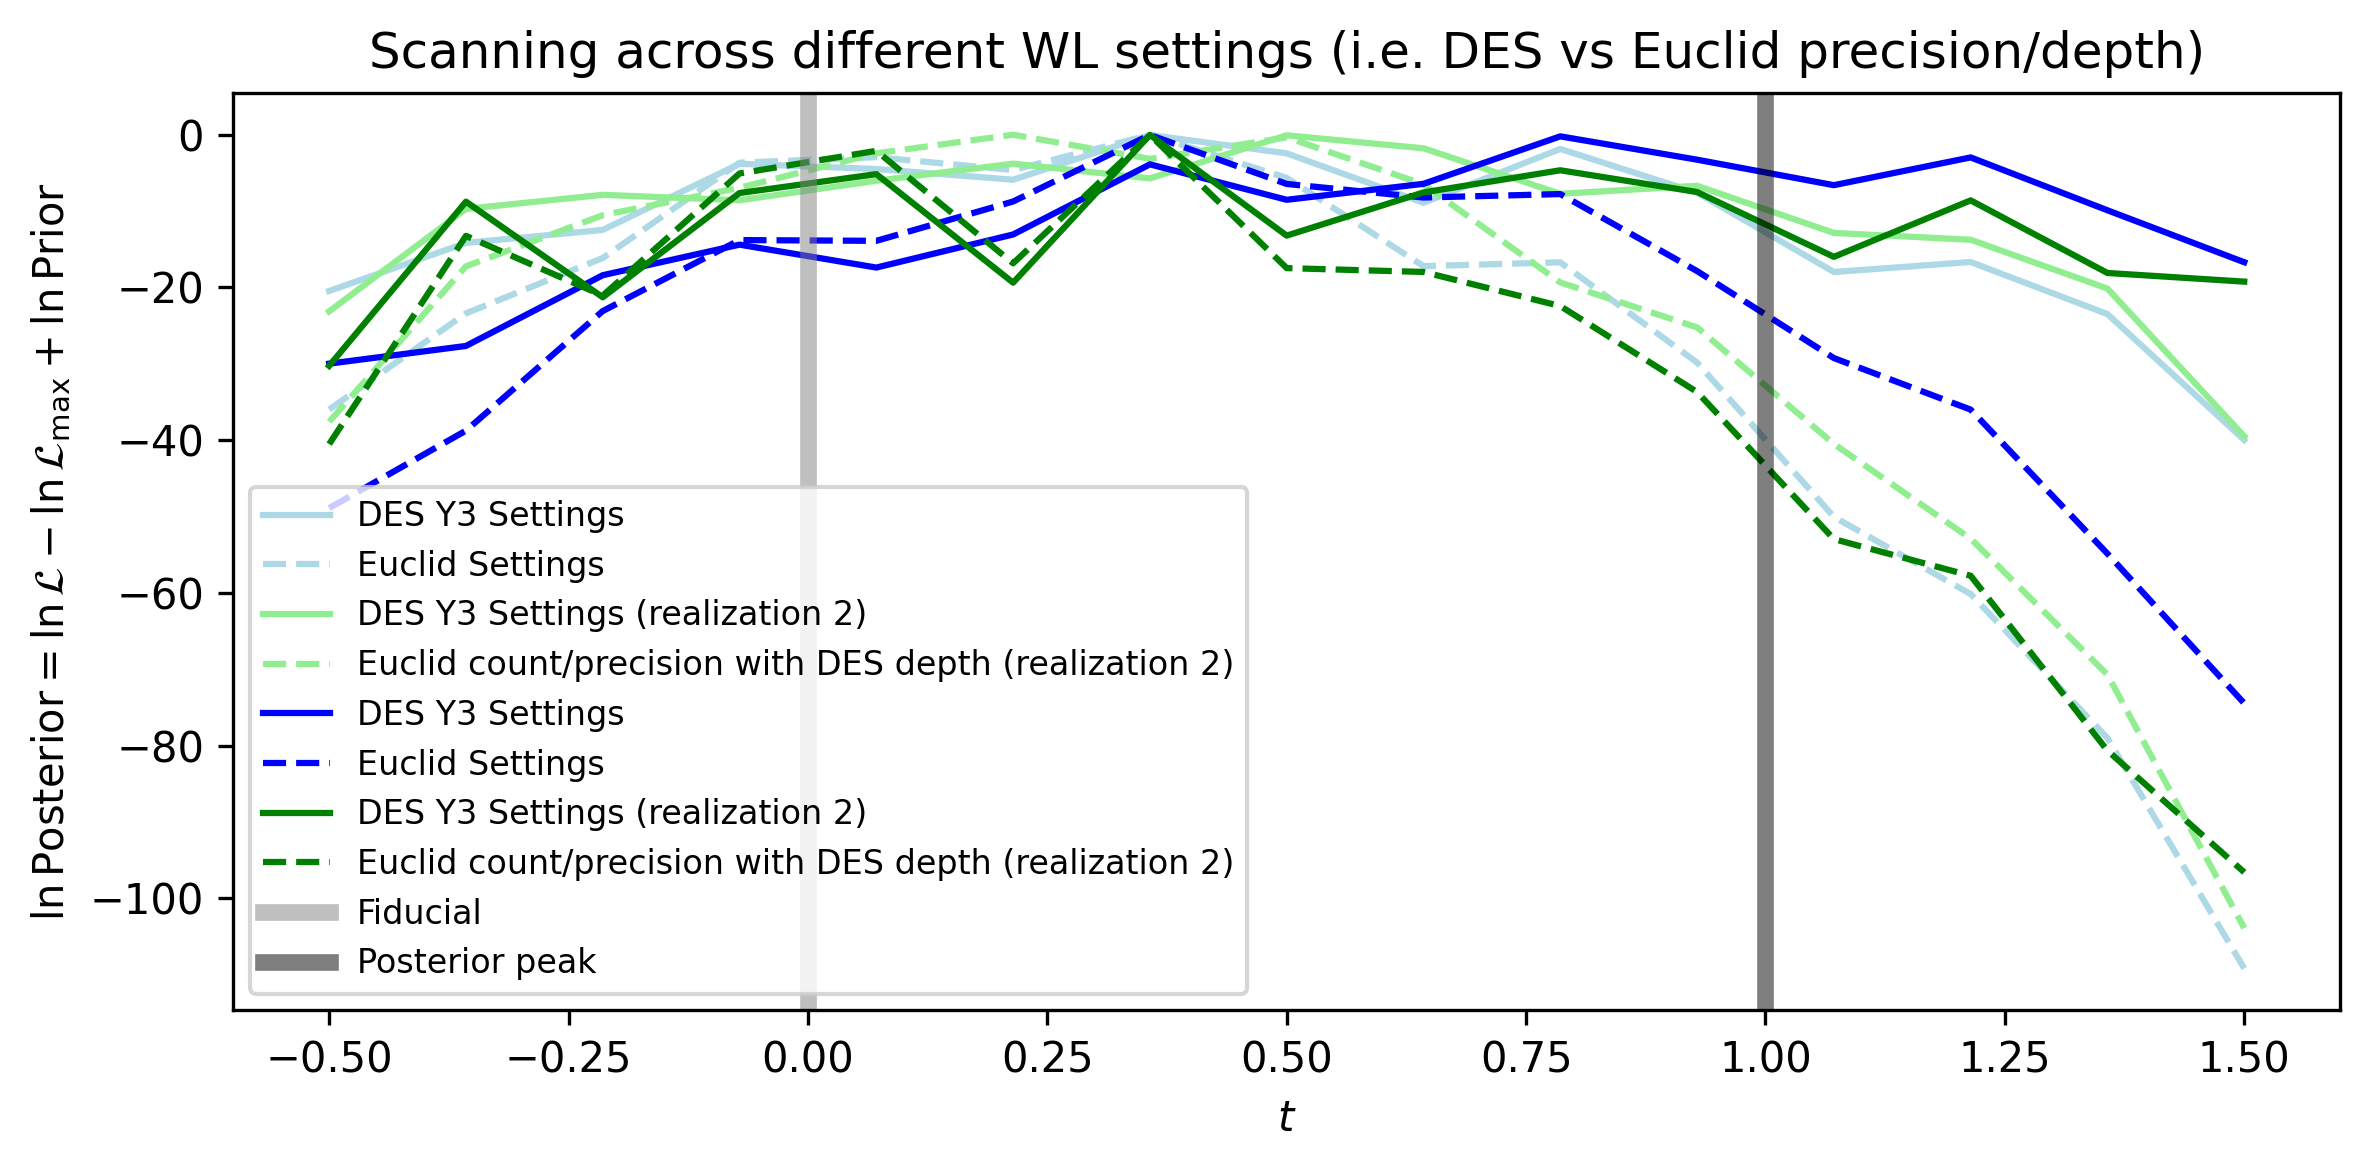

In [12]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 4), dpi=300)

colors = {
    "LCDM_DES_42"                        : 'blue',
    "LCDM_DES_43"                        : 'red',
    "LCDM_DES_44"                        : 'green',
    "LCDM_COSMOCNC_DES_42"               : 'cornflowerblue',
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42" : 'lightblue',
    "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42" : 'lightgreen',
    "LCDM_COSMOCNC_SR_Euclid_42-SR_best_fit_LCDM_DES_42" : 'lightblue',
    "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42" : 'lightblue',
    "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42" : 'lightgreen',
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL" : 'lightgreen',
    "LCDM_Euclid_42"                     : 'blue',
    "LCDM_deepEuclid_42"                 : 'blue',
    "LCDM_deepEuclid_44"                 : 'green',
    "LCDM_DES_42_ONLYQNOWL"              : 'green',
    "LCDM_deepEuclid_42_ONLYQNOWL"       : 'red',
}
linestyles = {
    "LCDM_DES_42"                        : '-',
    "LCDM_DES_43"                        : '-',
    "LCDM_DES_44"                        : '-',
    "LCDM_COSMOCNC_DES_42"               : '-',
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42" : '-',
    "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42" : '-',
    "LCDM_COSMOCNC_SR_Euclid_42-SR_best_fit_LCDM_DES_42" : '-.',
    "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42" : '--',
    "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42" : '--',
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL" : ':',
    "LCDM_Euclid_42"                     : '-.',
    "LCDM_deepEuclid_42"                 : '--',
    "LCDM_deepEuclid_44"                 : '--',
    "LCDM_DES_42_ONLYQNOWL"              : ':',
    "LCDM_deepEuclid_42_ONLYQNOWL"        : '-'
}


# Note: using the scaling relation parameters that best fit the catalogue
############################################
'''
my_title = 'Scanning across three real catalogues (i.e. realization/sampling test)'
catalogue_names_to_plot = ["LCDM_DES_42", "LCDM_DES_43", "LCDM_DES_44"]
labels = {
    "LCDM_DES_42" : "Real catalogue (seed 42), used in mcmc",
    "LCDM_DES_43" : "Real catalogue (seed 43)",
    "LCDM_DES_44" : "Real catalogue (seed 44)"
}
'''
############################################
'''
my_title = 'Scanning across different implementations (i.e. cosmocnc vs generation code test)'
catalogue_names_to_plot = ["LCDM_DES_42", "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42"]
labels = {
    "LCDM_DES_42" : "Real catalogue hmf and profile-to-q relation",
    "LCDM_COSMOCNC_DES_42" : "cosmocnc hmf and profile-to-q relation",
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42" : "cosmocnc hmf and scaling relation for q",
}
'''
############################################
'''
my_title = 'Scanning across different WL settings (i.e. DES vs Euclid precision/depth)\n[note: cosmocnc hmf and scaling relation for q]'
catalogue_names_to_plot = ["LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42",
                           "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42",
                           "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42",
                           "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42"]
labels = {
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42" : "DES Y3 Settings",
    "LCDM_COSMOCNC_SR_Euclid_42-SR_best_fit_LCDM_DES_42" : "Euclid count/precision with DES depth",
    "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42" : "DES Y3 Settings (realization 2)",
    "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42" : "Euclid count/precision with DES depth (realization 2)",
    "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42": "Euclid Settings",
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL" : "No WL data in likelihood"
}
'''
############################################
'''
my_title = 'Scanning across different WL settings (i.e. DES vs Euclid precision/depth)\n[note: now using the real catalogue hmf and profile-to-q-relation]'
catalogue_names_to_plot = ["LCDM_DES_42", "LCDM_deepEuclid_42",
                          "LCDM_DES_44", "LCDM_deepEuclid_44"]
labels = {
    "LCDM_DES_42" : "DES Y3 Settings",
    "LCDM_Euclid_42" : "Euclid count/precision with DES depth",
    "LCDM_deepEuclid_42": "Euclid Settings",
    "LCDM_deepEuclid_42_ONLYQNOWL" : "No WL data in likelihood (consistency check)",
    "LCDM_DES_42_ONLYQNOWL" : "No WL data in likelihood",
    "LCDM_DES_44" : "DES Y3 Settings (realization 2)",
    "LCDM_deepEuclid_44" : "Euclid count/precision with DES depth (realization 2)",
}
'''
############################################
my_title = 'Scanning across different WL settings (i.e. DES vs Euclid precision/depth)'
catalogue_names_to_plot = ["LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42",
                           "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42",
                           "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42",
                           "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42",
                          "LCDM_DES_42", "LCDM_deepEuclid_42",
                          "LCDM_DES_44", "LCDM_deepEuclid_44"]
labels = {
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42" : "DES Y3 Settings",
    "LCDM_COSMOCNC_SR_Euclid_42-SR_best_fit_LCDM_DES_42" : "Euclid count/precision with DES depth",
    "LCDM_COSMOCNC_SR_DES_44-SR_best_fit_LCDM_DES_42" : "DES Y3 Settings (realization 2)",
    "LCDM_COSMOCNC_SR_deepEuclid_44-SR_best_fit_LCDM_DES_42" : "Euclid count/precision with DES depth (realization 2)",
    "LCDM_COSMOCNC_SR_deepEuclid_42-SR_best_fit_LCDM_DES_42": "Euclid Settings",
    "LCDM_COSMOCNC_SR_DES_42-SR_best_fit_LCDM_DES_42_ONLYQNOWL" : "No WL data in likelihood",
    "LCDM_DES_42" : "DES Y3 Settings",
    "LCDM_Euclid_42" : "Euclid count/precision with DES depth",
    "LCDM_deepEuclid_42": "Euclid Settings",
    "LCDM_deepEuclid_42_ONLYQNOWL" : "No WL data in likelihood (consistency check)",
    "LCDM_DES_42_ONLYQNOWL" : "No WL data in likelihood",
    "LCDM_DES_44" : "DES Y3 Settings (realization 2)",
    "LCDM_deepEuclid_44" : "Euclid count/precision with DES depth (realization 2)",
}
############################################
'''
for catalogue_name in catalogue_names_to_plot:
    plt.plot(t_values, lnL_dict[catalogue_name], 
             label=labels[catalogue_name], color=colors[catalogue_name], ls=linestyles[catalogue_name])
plt.ylabel(r"$\ln \mathcal{L}$")
'''
'''
for catalogue_name in catalogue_names_to_plot:
    plt.plot(t_values, (lnL_dict[catalogue_name] - np.min(lnL_dict[catalogue_name])) / (np.max(lnL_dict[catalogue_name]) - np.min(lnL_dict[catalogue_name])), 
             label=labels[catalogue_name], color=colors[catalogue_name], ls=linestyles[catalogue_name])
plt.ylabel(r"$\frac{\ln \mathcal{L} - \ln \mathcal{L}_\text{min}}{\ln \mathcal{L}_\text{max} - \ln \mathcal{L}_\text{min}}$")
'''

ln_Prior = []
for i, theta in tqdm(enumerate(parameter_vectors)):
    (OMEGA_M_VAL, A_S_VAL, A_SZ_VAL, ALPHA_SZ_VAL, BETA_SZ_VAL,B_WL_0_VAL,B_WL_Z_VAL,B_WL_M_VAL) = theta
    ln_Prior.append(-0.5 * (B_WL_0_VAL / 0.02)**2
                    -0.5 * ((B_WL_M_VAL-1.) / 0.02)**2
                    -0.5 * (B_WL_Z_VAL / 0.02)**2)
for catalogue_name in catalogue_names_to_plot:
    plt.plot(t_values, lnL_dict[catalogue_name] - np.max(lnL_dict[catalogue_name]) + np.asarray(ln_Prior), 
             label=labels[catalogue_name], color=colors[catalogue_name], ls=linestyles[catalogue_name])
plt.ylabel(r"$\ln \text{Posterior} = \ln \mathcal{L} - \ln \mathcal{L}_\text{max} + \ln \text{Prior}$")

plt.title(my_title)

plt.axvline(0, lw=4, alpha=0.5, linestyle="-", label="Fiducial", c='gray')
plt.axvline(1, lw=4, alpha=0.5, linestyle="-", label="Posterior peak", c='k')
plt.xlabel(r"$t$")

#plt.legend(loc='upper left')
plt.legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

In [14]:
from feedback_mimic import get_some_quantities

In [36]:
ln_L, nc = get_log_likelihood(
    catalogue_name = f"/home/jange/scratch/FeedbackMimic/results/mock_catalogs/before_final_hmf_fixes/LCDM_DES_mock_seed42.pkl",
    omega_m  = 0.143344,
    A_s      = 2.1e-9,
    A_sz     = -4.3054, # just default vals from cosmocnc paper
    alpha_sz = 1.233,
    beta_sz  = 2.0,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    return_nc = True,
)

ratio = []
for redshift in [0.0,0.5,1.0,1.5]:
    with open(f"results/halo_model/{redshift}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
    M_ARR_TEST = data_LCDM['M']
    ################### axionhmcode
    from axionHMcode.cosmology.variance import func_sigma_M
    HM_sigma = func_sigma_M(M_ARR_TEST, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos']['Omega_m_0'])
    from axionHMcode.halo_model.halo_mass_function import func_dlnsigma2_dlnM
    HM_dsigma2 = func_dlnsigma2_dlnM(M_ARR_TEST, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos'], data_LCDM['cosmos']['Omega_m_0'])
    from axionHMcode.cosmology.overdensities import func_delta_c
    HM_dc = func_delta_c(redshift, data_LCDM['cosmos']['Omega_ax_0'],
                            data_LCDM['cosmos']['Omega_m_0'],
                            data_LCDM['cosmos']['Omega_w_0'],
                            data_LCDM['cosmos']['G_a'],
                            data_LCDM['cosmos']['version'])
    ################### cosmocnc
    from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import sigma_R, func_axionHMcode_delta_c
    h_fid = 0.68
    rho_c_0 = nc.cosmology.background_cosmology.critical_density(0.).value*nc.const.mpc**3/nc.const.solar*1e3
    rho_m = rho_c_0*nc.cosmology.cosmo_params["Om0"]
    rho_m_for_sigma = rho_m / h_fid**2 
    k, ps   = nc.cosmology.power_spectrum.get_linear_power_spectrum(redshift)
    #sigma_r = sigma_R((data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total']), cosmology=nc.cosmology)
    sigma_r = sigma_R((k*h_fid**-1, ps*h_fid**3), cosmology=nc.cosmology)
    sigma_r.get_derivative(type_deriv="analytical")
    (sigma) = sigma_r.get_sigma_M(
        M_ARR_TEST, rho_m_for_sigma, get_deriv=False)
    cnc_sigma = sigma
    sigma_r.get_dlnsigma2_dlnM(rho_m_for_sigma, h_fid)
    sigma = sigma_r.get_sigma_M(M_ARR_TEST, rho_m_for_sigma, get_deriv=False)
    dlnsigma2_dlnMvir = sigma_r.get_dlnsigma2_dlnM_M(M_ARR_TEST, rho_m_for_sigma)
    cnc_dsigma2 = dlnsigma2_dlnMvir
    cnc_dc = func_axionHMcode_delta_c(redshift, nc.cosmology.cosmo_params["Om0"], 
                                      nc.cosmology.G_a_cached, 
                                      lambda z: np.sqrt( nc.cosmology.cosmo_params["Om0"]*(1+redshift)**3 + (1.- nc.cosmology.cosmo_params["Om0"])), 
                                      (np.interp(redshift, nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full)
                                           * nc.cosmology.normalisation_cached * (1 + redshift)))
    ratio.append(cnc_dc/HM_dc)

In [41]:
cnc_dc/HM_dc

np.float64(1.000073682085367)

In [47]:
ln_L, nc = get_log_likelihood(
    catalogue_name = f"/home/jange/scratch/FeedbackMimic/results/mock_catalogs/before_final_hmf_fixes/LCDM_DES_mock_seed42.pkl",
    omega_m  = 0.143344,
    A_s      = 2.1e-9,
    A_sz     = -4.353355099,
    alpha_sz = 1.199496418,
    beta_sz  = 2.000448160
    b_WL_0   = 0.0,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    return_nc = True,
)

print(nc.get_number_counts())

None


In [48]:
nc.n_tot

Array(25534.08004577, dtype=float64)

/tmp/ipykernel_234954/3184875602.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 0, 'z')

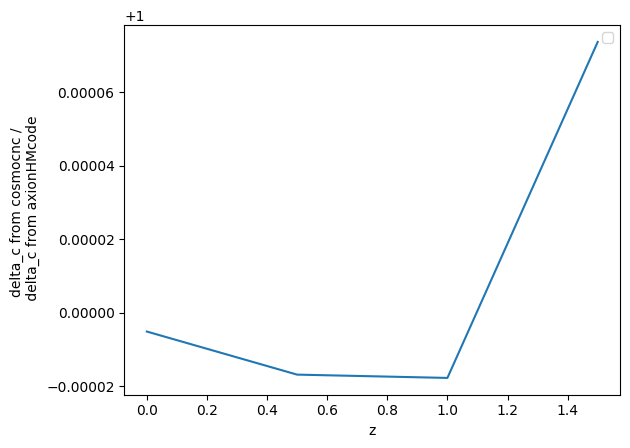

In [43]:
plt.plot([0.0,0.5,1.0,1.5], ratio)
plt.legend()
plt.ylabel('delta_c from cosmocnc / \n delta_c from axionHMcode')
plt.xlabel('z')

In [50]:
HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
with open(f"{HALO_INPUT_FILE}/{0.0}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data = pickle.load(f)

In [51]:
data['cosmos']

{'M_min': 11,
 'M_max': 16,
 'transfer_kmax': 200,
 'omega_b_0': 0.0226576,
 'm_ax': 2.511886431509572e-26,
 'h': 0.68,
 'z': np.float64(0.0),
 'ns': 0.965,
 'As': 2.1e-09,
 'k_piv': 0.05,
 'version': 'dome',
 'Omega_b_0': 0.04899999999999999,
 'omega_ax_0': 1e-20,
 'omega_d_0': 0.1206864,
 'Omega_ax_0': 2.1626297577854667e-20,
 'Omega_d_0': 0.26099999999999995,
 'omega_m_0': 0.143344,
 'Omega_m_0': 0.30999999999999994,
 'omega_db_0': 0.143344,
 'Omega_db_0': 0.30999999999999994,
 'Omega_w_0': 0.6900000000000001,
 'G_a': 0.9316850928053196,
 'sigma_8': 0.825278223}

In [52]:
from axionHMcode.axionCAMB_and_lin_PS import load_cosmology
cosmos = load_cosmology.load_cosmology_input("/home/jange/scratch/FeedbackMimic/axionHMcode_input/axionHMcode_input_preferred.txt") 

In [54]:
from axionHMcode.cosmology.overdensities import func_D_z_unnorm_int


In [59]:
func_D_z_unnorm_int(1.5, cosmos['Omega_m_0'],      cosmos['Omega_w_0'])

0.3973369326956338